# EEG Analysis - Sesi 2
## Fokus: Perbandingan AF7 vs AF8
Pipeline: Load → Preprocessing → Min Shift → Feature Extraction → Visualisasi

In [ ]:
# ============================================================
# CELL 1 - Import Library
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings

warnings.filterwarnings('ignore')
print('Semua library berhasil diimport')

Semua library berhasil diimport


In [ ]:
# ============================================================
# CELL 2 - Mount Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')
print('Google Drive terhubung')

Mounted at /content/drive
Google Drive terhubung


In [ ]:
# ============================================================
# CELL 3 - Load semua CSV dari Drive
# ============================================================
PATH_CSV = '/content/drive/MyDrive/TK AI/EEG/Sesi 2/All_Data'

SUBJEK = ['Aulia', 'Azizah', 'Dandi', 'Irgi', 'Tama', 'Zahrah']

MAPPING_FILE = {
    'Aulia'  : 'EEG_Nonton_Aulia_Sesi2.csv',
    'Azizah' : 'EEG_Nonton_Azizah_Sesi2.csv',
    'Dandi'  : 'EEG_Nonton_Dandi_Sesi2.csv',
    'Irgi'   : 'EEG_Nonton_Irgi_Sesi2.csv',
    'Tama'   : 'EEG_Nonton_Tama_Sesi2.csv',
    'Zahrah' : 'EEG_Nonton_Zahra_Sesi2.csv',
}

data_eeg = {}

for nama, nama_file in MAPPING_FILE.items():
    path = os.path.join(PATH_CSV, nama_file)
    if os.path.exists(path):
        df = pd.read_csv(path)
        data_eeg[nama] = df
        print(f'{nama} - {len(df):,} baris, {len(df.columns)} kolom')
    else:
        print(f'{nama} - file tidak ditemukan: {path}')

Aulia - 45,109 baris, 44 kolom
Azizah - 46,266 baris, 44 kolom
Dandi - 45,308 baris, 44 kolom
Irgi - 45,306 baris, 44 kolom
Tama - 45,065 baris, 44 kolom
Zahrah - 45,109 baris, 44 kolom


In [ ]:
# ============================================================
# CELL 4 - Preprocessing
# Ambil kolom AF7 dan AF8 saja (semua band),
# hapus baris kosong, interpolasi missing values.
# TIDAK ada normalisasi.
# ============================================================

# Kolom yang difokuskan: semua band untuk AF7 dan AF8
KOLOM_AF7 = ['Delta_AF7', 'Theta_AF7', 'Alpha_AF7', 'Beta_AF7', 'Gamma_AF7']
KOLOM_AF8 = ['Delta_AF8', 'Theta_AF8', 'Alpha_AF8', 'Beta_AF8', 'Gamma_AF8']
KOLOM_SEMUA = KOLOM_AF7 + KOLOM_AF8

data_bersih = {}

for nama, df in data_eeg.items():

    # Ambil TimeStamp + kolom AF7 dan AF8
    df = df[['TimeStamp'] + KOLOM_SEMUA].copy()

    # Hapus baris yang semua nilainya kosong
    # df = df.dropna(subset=KOLOM_SEMUA, how='all')

    # Interpolasi linear untuk missing values yang tersisa
    df[KOLOM_SEMUA] = df[KOLOM_SEMUA].interpolate(method='linear', limit_direction='both')

    df = df.reset_index(drop=True)

    terhapus = len(data_eeg[nama]) - len(df)
    data_bersih[nama] = df
    print(f'{nama} - sisa {len(df):,} baris (dihapus {terhapus} baris)')

print('\nPreprocessing selesai')

Aulia - sisa 45,109 baris (dihapus 0 baris)
Azizah - sisa 46,266 baris (dihapus 0 baris)
Dandi - sisa 45,308 baris (dihapus 0 baris)
Irgi - sisa 45,306 baris (dihapus 0 baris)
Tama - sisa 45,065 baris (dihapus 0 baris)
Zahrah - sisa 45,109 baris (dihapus 0 baris)

Preprocessing selesai


In [ ]:
# ============================================================
# CELL 5 - Cek nilai negatif
# ============================================================

print('=== Persentase nilai negatif per subjek ===')
for nama, df in data_bersih.items():
    total = len(df)
    print(f'\n{nama}:')
    for kolom in KOLOM_SEMUA:
        n_neg = (df[kolom] < 0).sum()
        pct   = n_neg / total * 100
        if n_neg > 0:
            print(f'  {kolom}: {n_neg} baris negatif ({pct:.1f}%)')

=== Persentase nilai negatif per subjek ===

Aulia:
  Delta_AF7: 7802 baris negatif (17.3%)
  Theta_AF7: 18542 baris negatif (41.1%)
  Alpha_AF7: 3017 baris negatif (6.7%)
  Beta_AF7: 32299 baris negatif (71.6%)
  Gamma_AF7: 45109 baris negatif (100.0%)
  Delta_AF8: 6511 baris negatif (14.4%)
  Theta_AF8: 16539 baris negatif (36.7%)
  Alpha_AF8: 5520 baris negatif (12.2%)
  Beta_AF8: 34635 baris negatif (76.8%)
  Gamma_AF8: 44796 baris negatif (99.3%)

Azizah:
  Delta_AF7: 12337 baris negatif (26.7%)
  Theta_AF7: 22618 baris negatif (48.9%)
  Alpha_AF7: 3879 baris negatif (8.4%)
  Beta_AF7: 11909 baris negatif (25.7%)
  Gamma_AF7: 45070 baris negatif (97.4%)
  Delta_AF8: 4995 baris negatif (10.8%)
  Theta_AF8: 15958 baris negatif (34.5%)
  Alpha_AF8: 1197 baris negatif (2.6%)
  Beta_AF8: 11373 baris negatif (24.6%)
  Gamma_AF8: 45407 baris negatif (98.1%)

Dandi:
  Delta_AF7: 26821 baris negatif (59.2%)
  Theta_AF7: 36584 baris negatif (80.7%)
  Alpha_AF7: 17541 baris negatif (38.7%)
 

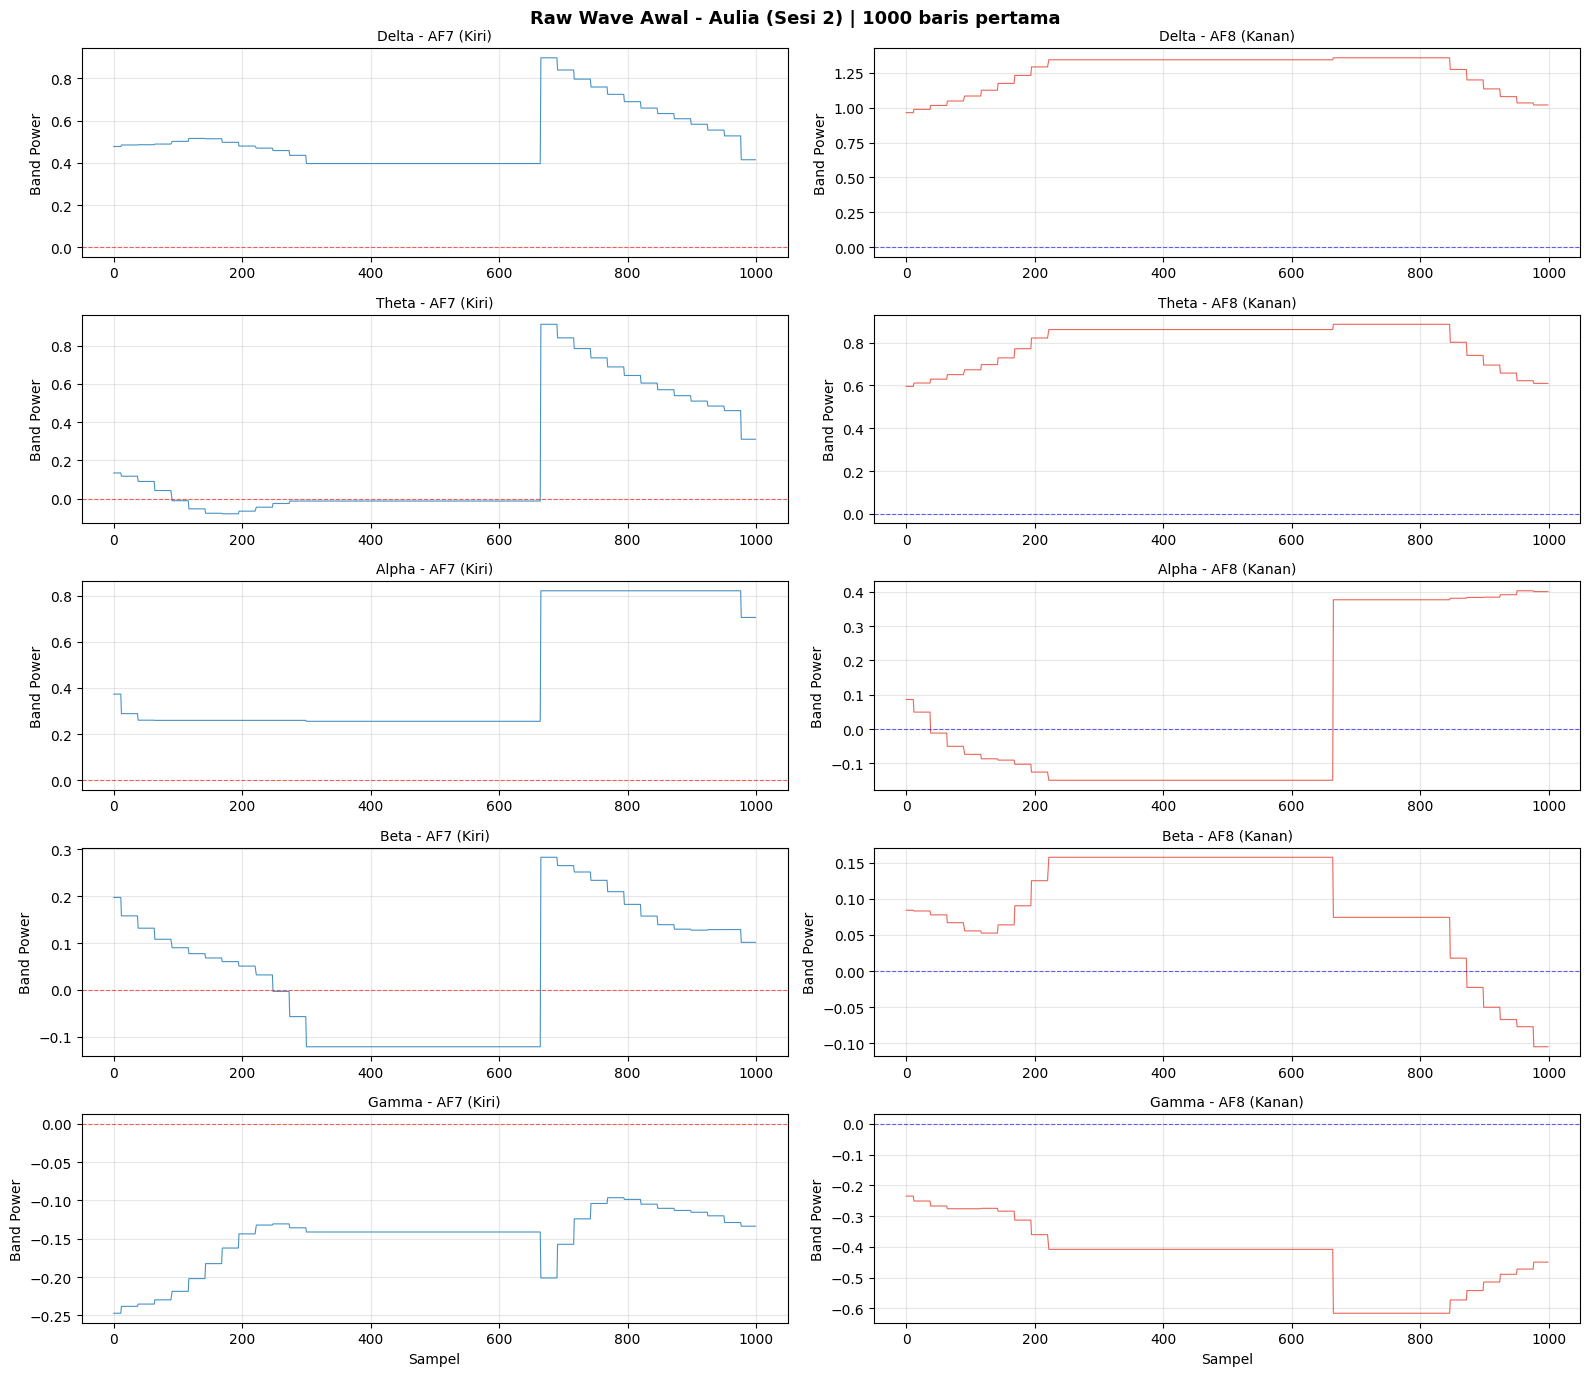

Selesai plot Aulia



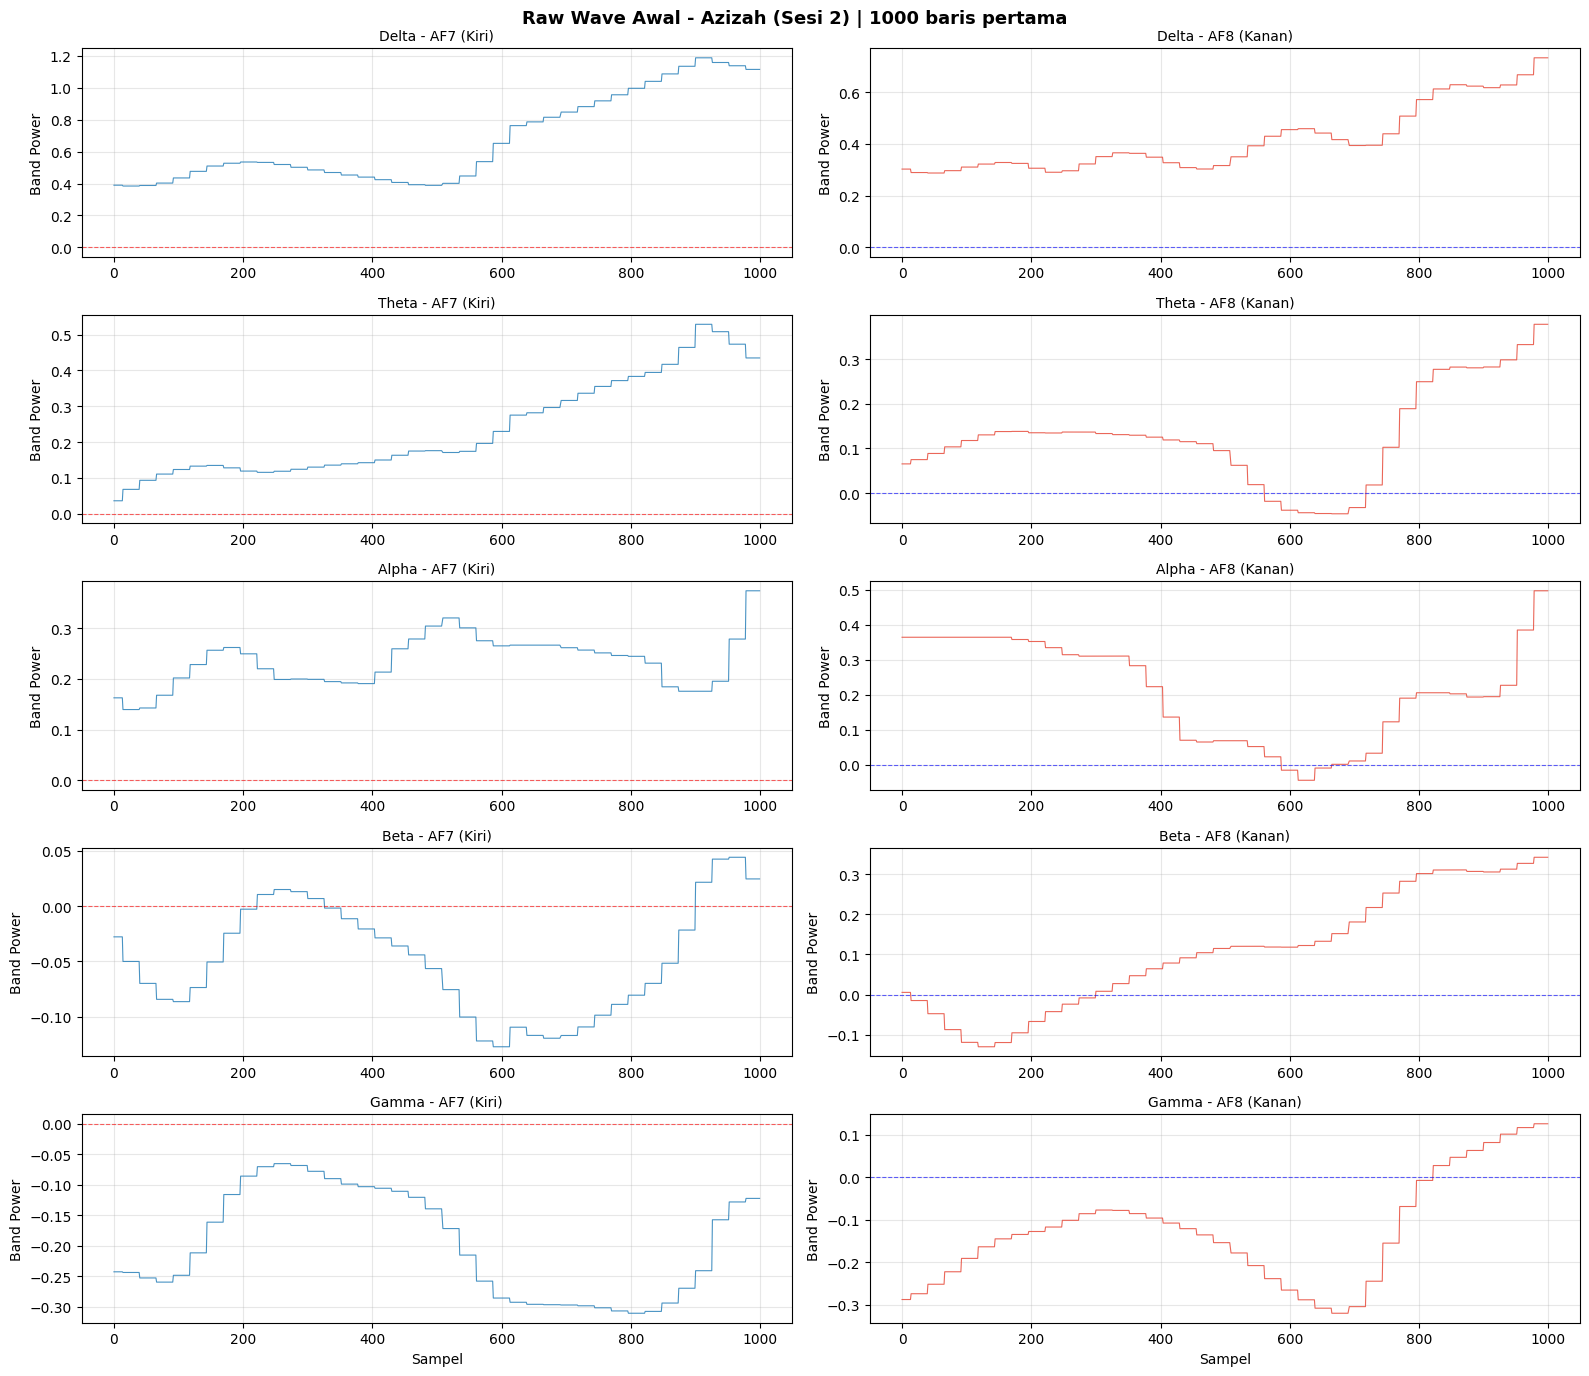

Selesai plot Azizah



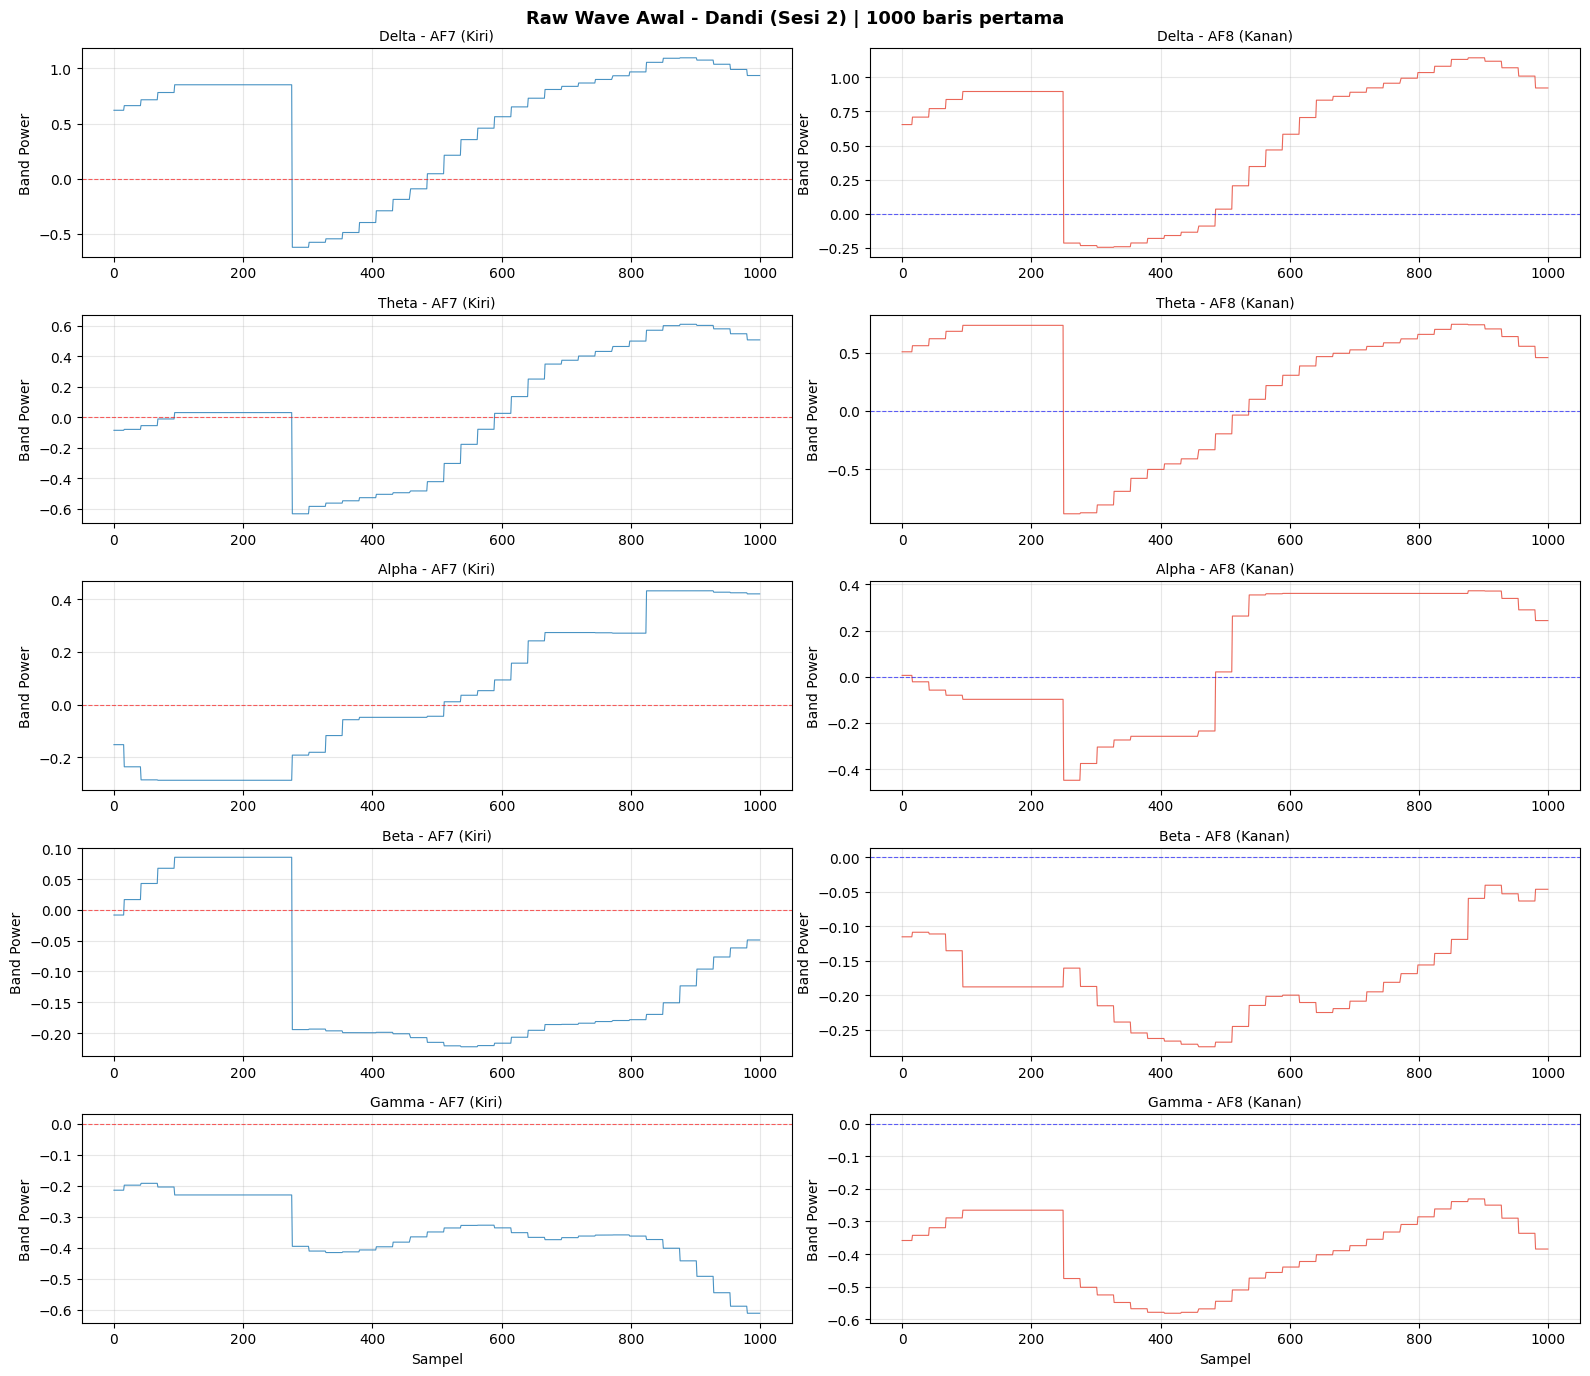

Selesai plot Dandi



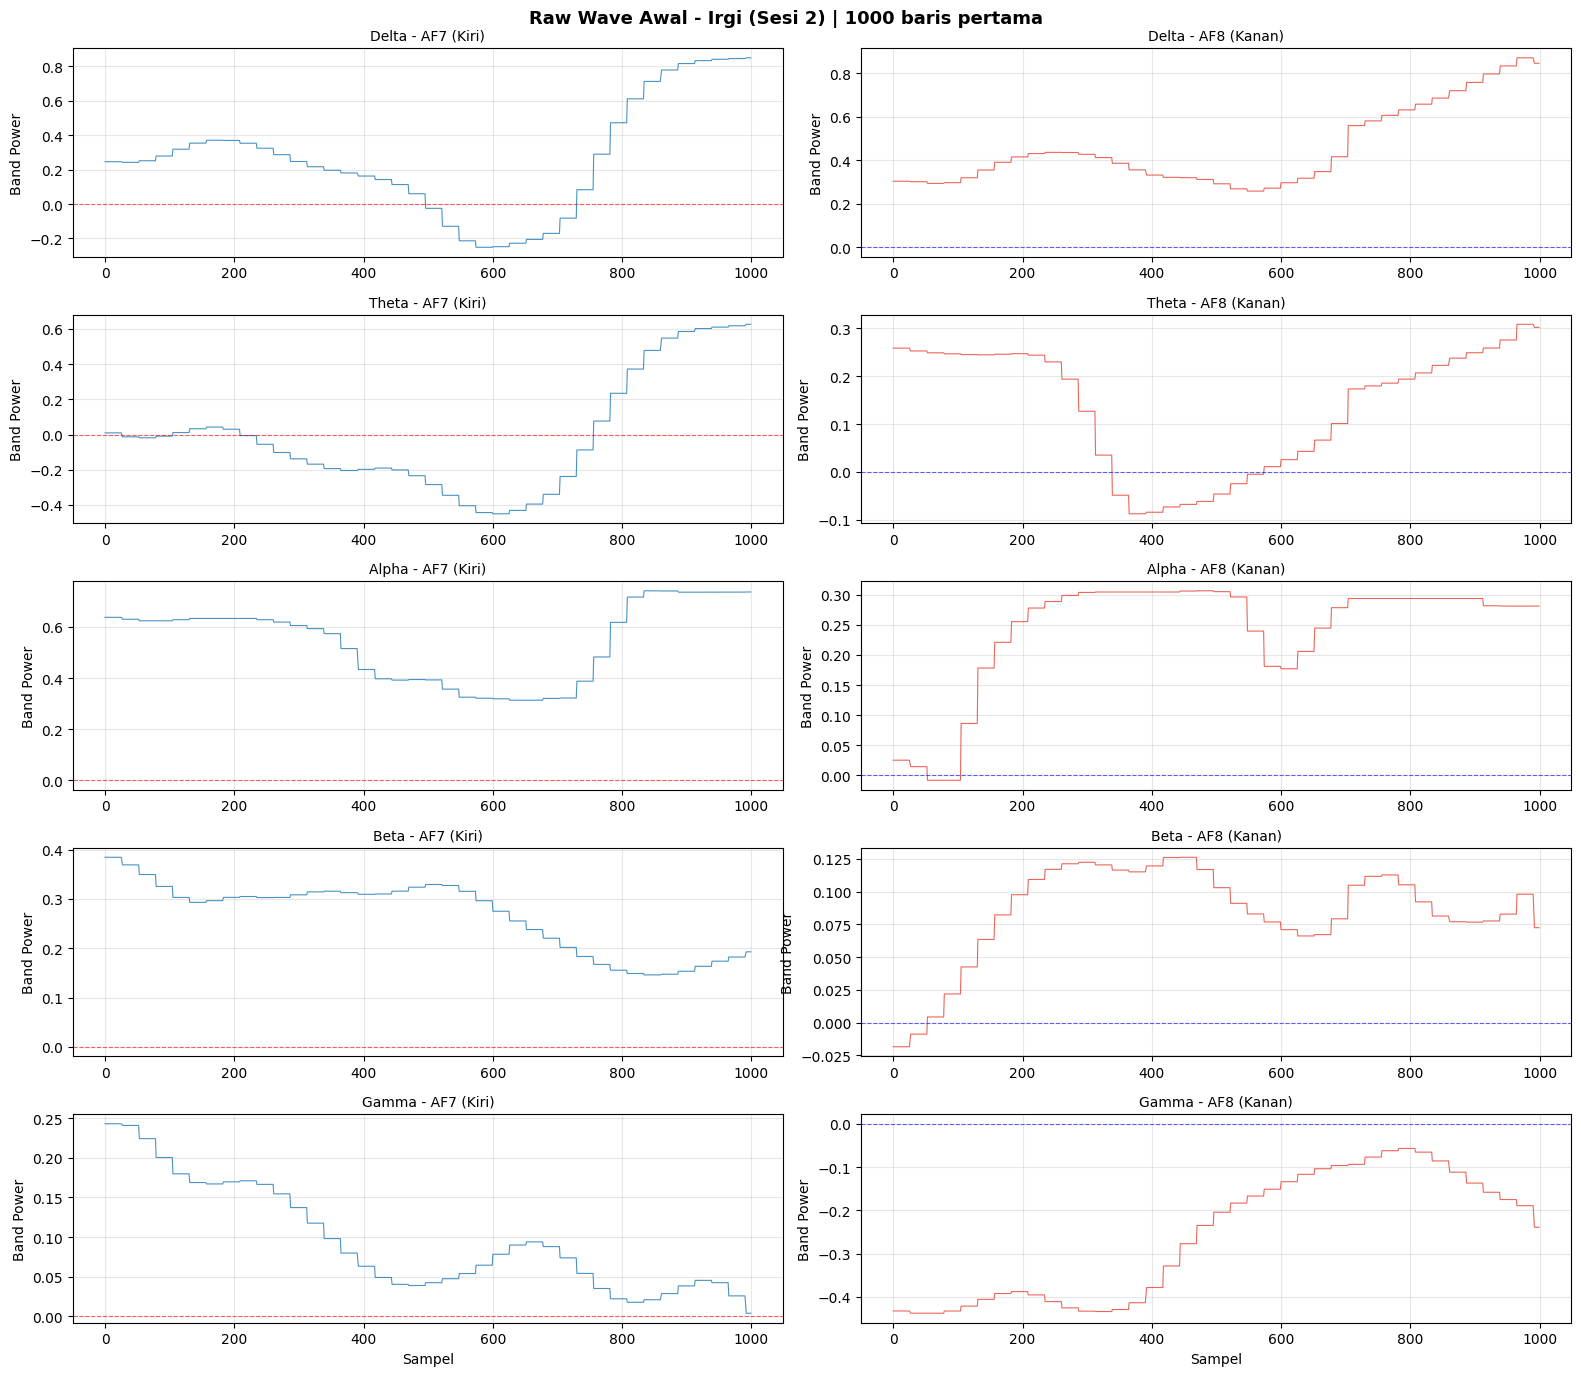

Selesai plot Irgi



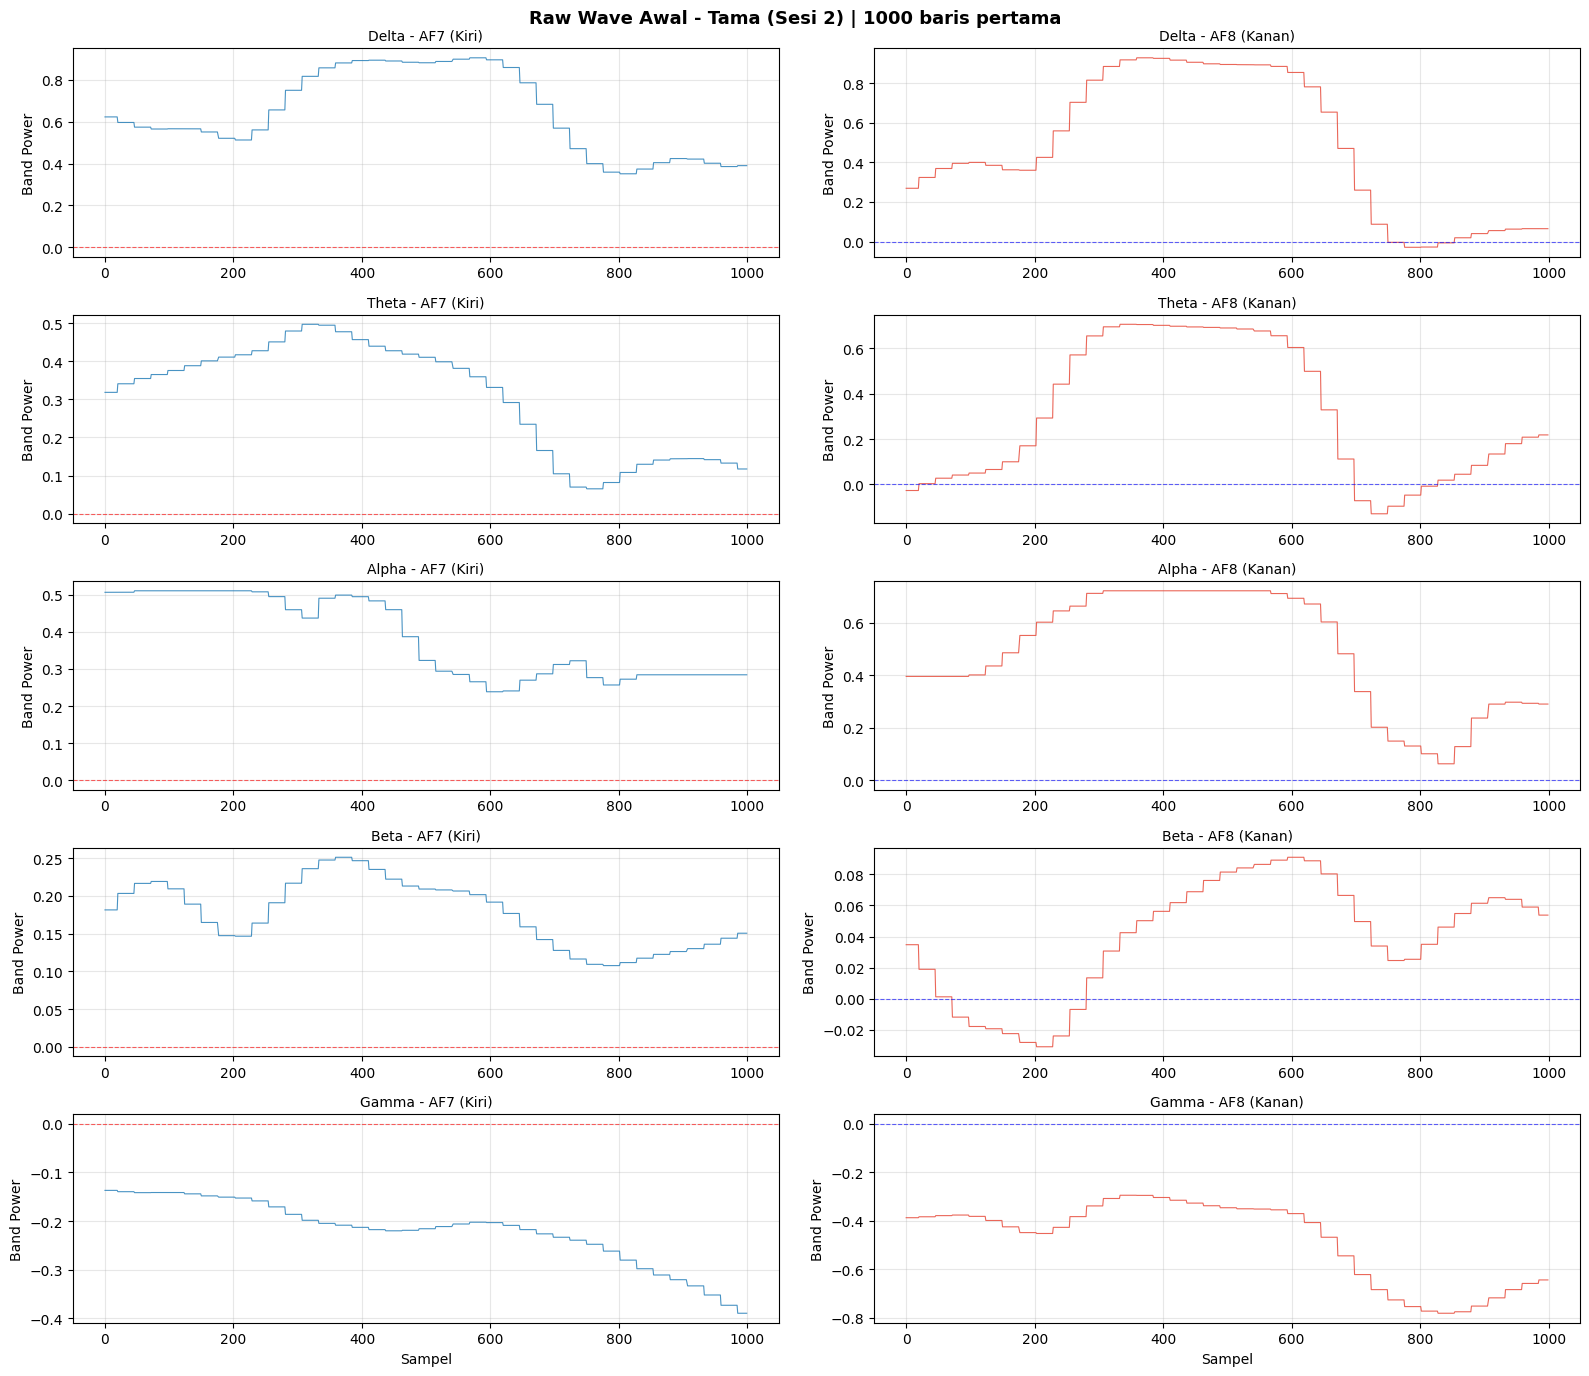

Selesai plot Tama



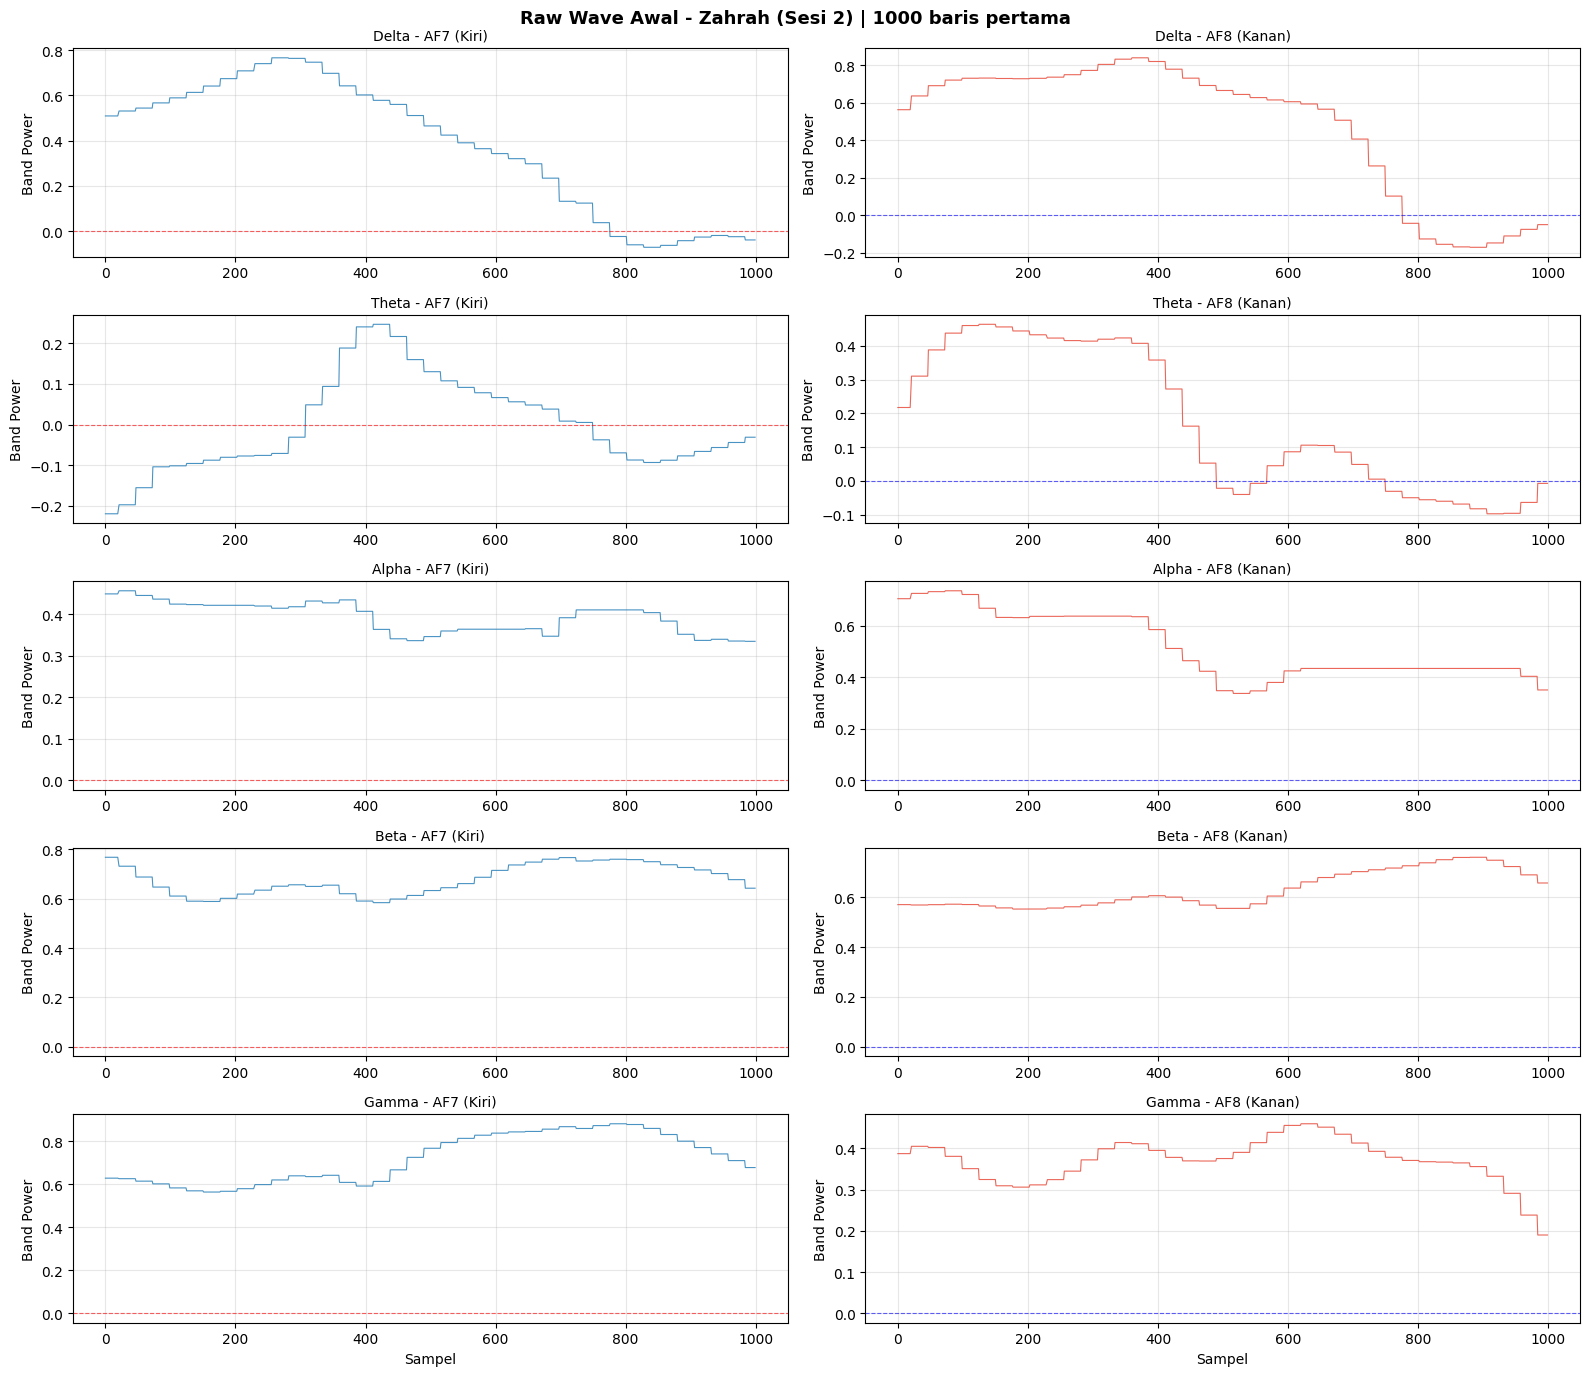

Selesai plot Zahrah



In [ ]:
# ============================================================
# CELL 5b - Visualisasi RAW WAVE awal tiap orang
# Tampilkan 1000 baris pertama data mentah
# untuk melihat distribusi nilai asli termasuk yang negatif
# ============================================================

WARNA = {
    'Aulia'  : '#e74c3c',
    'Azizah' : '#3498db',
    'Dandi'  : '#2ecc71',
    'Irgi'   : '#f39c12',
    'Tama'   : '#9b59b6',
    'Zahrah' : '#1abc9c'
}

BANDS = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']
N_AWAL = 1000  # Baris pertama yang ditampilkan

for nama, df in data_bersih.items():

    fig, axes = plt.subplots(5, 2, figsize=(16, 14))
    fig.suptitle(f'Raw Wave Awal - {nama} (Sesi 2) | {N_AWAL} baris pertama',
                 fontsize=13, fontweight='bold')

    for i, band in enumerate(BANDS):
        kolom_af7 = f'{band}_AF7'
        kolom_af8 = f'{band}_AF8'

        data_af7 = df[kolom_af7].iloc[:N_AWAL]
        data_af8 = df[kolom_af8].iloc[:N_AWAL]

        # AF7 (kiri)
        axes[i][0].plot(data_af7.values, color='#2980b9', linewidth=0.8, alpha=0.85)
        axes[i][0].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.6)
        axes[i][0].set_title(f'{band} - AF7 (Kiri)', fontsize=10)
        axes[i][0].set_ylabel('Band Power')
        axes[i][0].grid(True, alpha=0.3)

        # AF8 (kanan)
        axes[i][1].plot(data_af8.values, color='#e74c3c', linewidth=0.8, alpha=0.85)
        axes[i][1].axhline(y=0, color='blue', linestyle='--', linewidth=0.8, alpha=0.6)
        axes[i][1].set_title(f'{band} - AF8 (Kanan)', fontsize=10)
        axes[i][1].set_ylabel('Band Power')
        axes[i][1].grid(True, alpha=0.3)

    axes[4][0].set_xlabel('Sampel')
    axes[4][1].set_xlabel('Sampel')

    plt.tight_layout()
    plt.show()
    print(f'Selesai plot {nama}\n')

In [ ]:
# ============================================================
# CELL 6 - Baseline Correction (min-shift per kolom per subjek)
# Geser sinyal ke atas sebesar nilai minimumnya.
# Shape sinyal tidak berubah, hanya baseline dikoreksi ke >= 0.
# ============================================================

min_global = min(
    df[kolom].min()
    for df in data_bersih.values()
    for kolom in KOLOM_SEMUA
)

data_clean = {}

for nama, df in data_bersih.items():
    df_clean = df.copy()
    if min_global < 0:
        df_clean[KOLOM_SEMUA] = df_clean[KOLOM_SEMUA] - min_global
    ada_negatif = (df_clean[KOLOM_SEMUA] < 0).any().any()
    data_clean[nama] = df_clean
    print(f'{nama} - masih ada negatif? {ada_negatif}')

print(f'\nNilai minimum global: {min_global:.4f}')
print(f'Semua sinyal di-shift sebesar: {-min_global:.4f}')
print('\nBaseline correction selesai')

Aulia - masih ada negatif? False
Azizah - masih ada negatif? False
Dandi - masih ada negatif? False
Irgi - masih ada negatif? False
Tama - masih ada negatif? False
Zahrah - masih ada negatif? False

Nilai minimum global: -0.8930
Semua sinyal di-shift sebesar: 0.8930

Baseline correction selesai


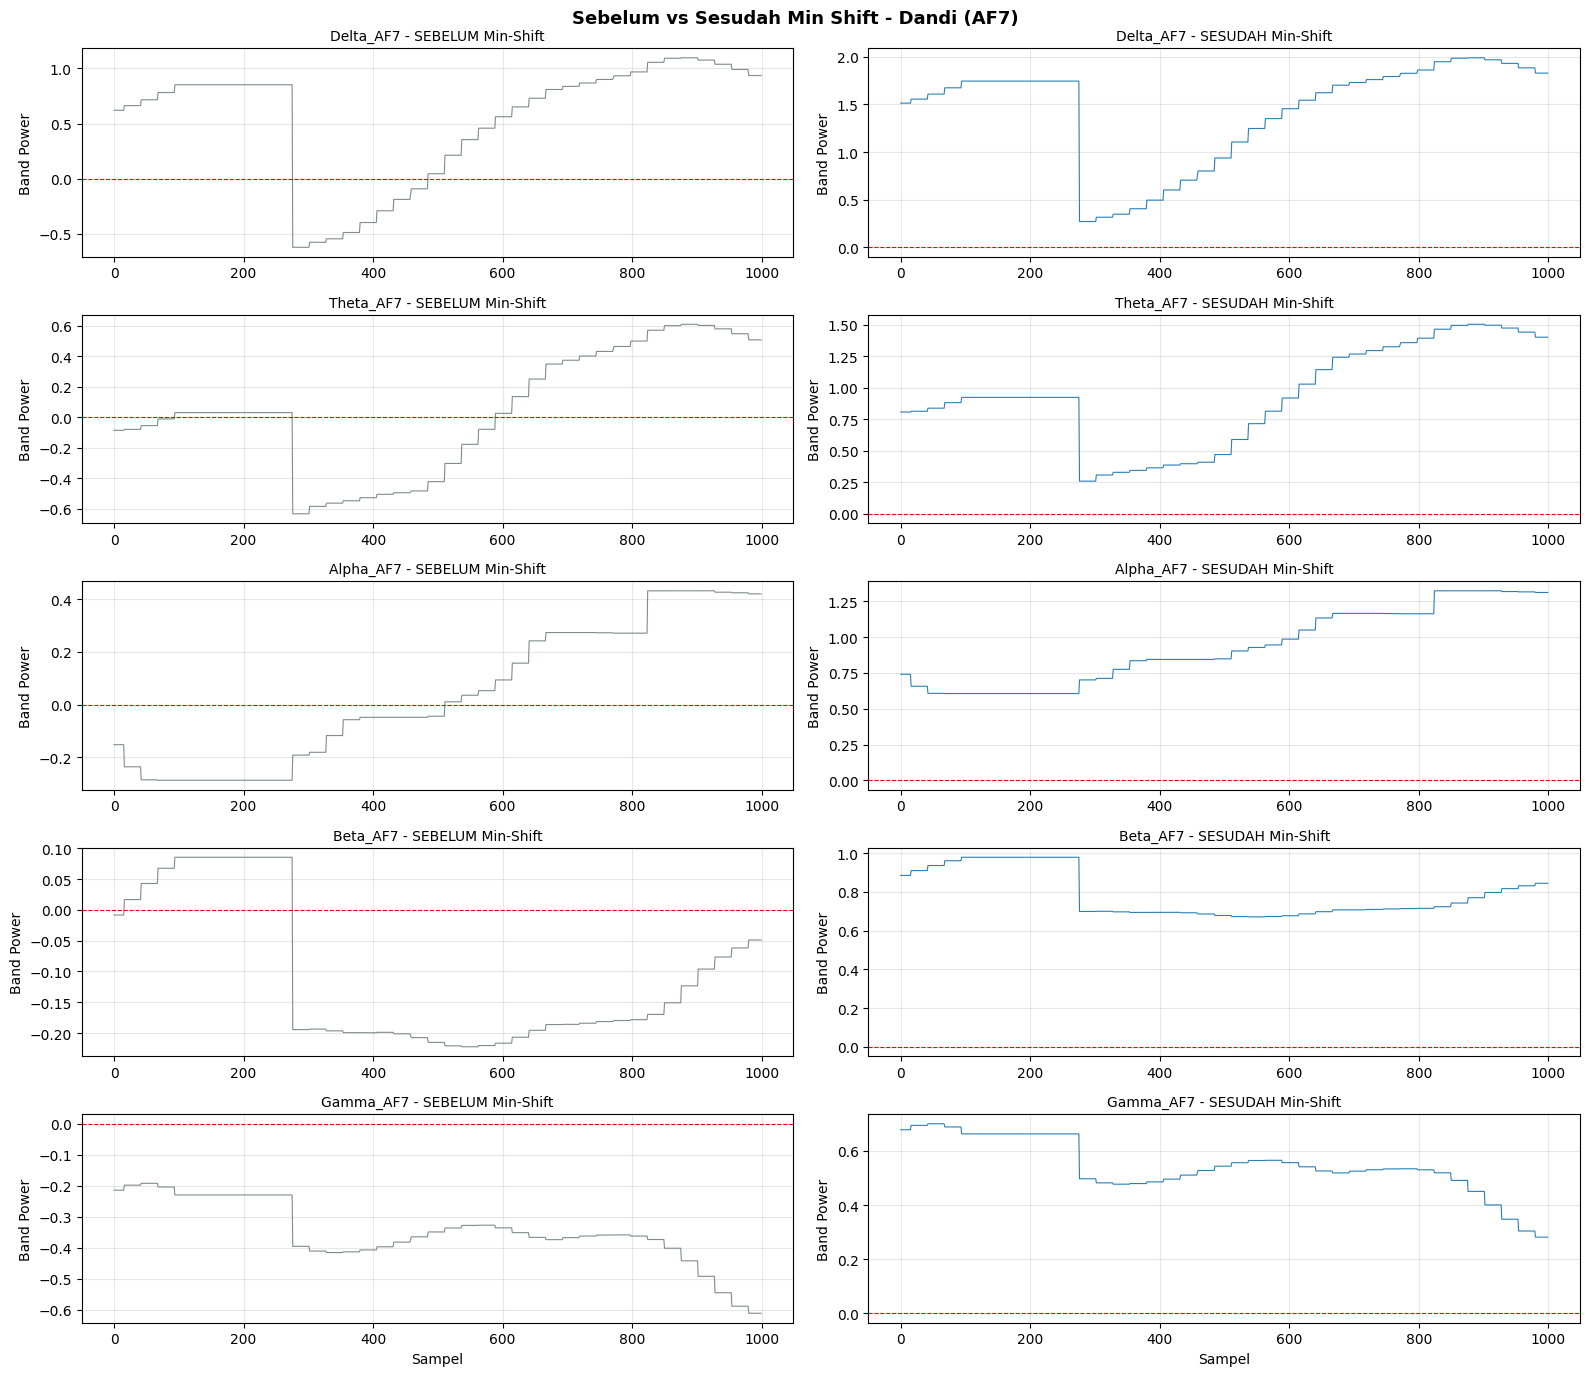

In [ ]:
# ============================================================
# CELL 6b - Perbandingan sebelum vs sesudah min shift
# Visualisasikan efek min shift pada 1 subjek sebagai contoh
# ============================================================

CONTOH_SUBJEK = list(data_bersih.keys())[2]
N_PLOT = 1000

fig, axes = plt.subplots(5, 2, figsize=(16, 14))
fig.suptitle(f'Sebelum vs Sesudah Min Shift - {CONTOH_SUBJEK} (AF7)',
             fontsize=13, fontweight='bold')

for i, band in enumerate(BANDS):
    kolom = f'{band}_AF7'

    sebelum = data_bersih[CONTOH_SUBJEK][kolom].iloc[:N_PLOT]
    sesudah = data_clean[CONTOH_SUBJEK][kolom].iloc[:N_PLOT]

    axes[i][0].plot(sebelum.values, color='#7f8c8d', linewidth=0.8)
    axes[i][0].axhline(y=0, color='red', linestyle='--', linewidth=0.8)
    axes[i][0].set_title(f'{band}_AF7 - SEBELUM Min-Shift', fontsize=10)
    axes[i][0].set_ylabel('Band Power')
    axes[i][0].grid(True, alpha=0.3)

    axes[i][1].plot(sesudah.values, color='#2980b9', linewidth=0.8)
    axes[i][1].axhline(y=0, color='red', linestyle='--', linewidth=0.8)
    axes[i][1].set_title(f'{band}_AF7 - SESUDAH Min-Shift', fontsize=10)
    axes[i][1].set_ylabel('Band Power')
    axes[i][1].grid(True, alpha=0.3)

axes[4][0].set_xlabel('Sampel')
axes[4][1].set_xlabel('Sampel')

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 7 - Feature Extraction: Sliding Window per Detik
# Window berdasarkan detik dari TimeStamp (bukan asumsi 256 Hz)
# Tiap window = 1 detik real, hitung mean AF7 dan AF8 per band
# TIDAK dirata-rata antar sensor — AF7 dan AF8 tetap terpisah
# ============================================================

data_window = {}

for nama, df in data_clean.items():

    # Parse TimeStamp ke detik (floor = bulatkan ke bawah)
    df = df.copy()
    df['detik'] = pd.to_datetime(df['TimeStamp']).dt.floor('s')

    hasil = []
    detik_unik = sorted(df['detik'].unique())

    for i, detik in enumerate(detik_unik):
        window = df[df['detik'] == detik]

        # Skip window yang terlalu sedikit sampelnya (noise)
        if len(window) < 10:
            continue

        row = {'window': i}

        for band in BANDS:
            row[f'{band}_AF7'] = window[f'{band}_AF7'].mean()
            row[f'{band}_AF8'] = window[f'{band}_AF8'].mean()

        hasil.append(row)

    data_window[nama] = pd.DataFrame(hasil).reset_index(drop=True)

print('Sliding window per detik selesai')
print('Jumlah window per subjek:')
for nama, df in data_window.items():
    print(f'  {nama} - {len(df)} window (~{len(df)} detik)')

print('\nPreview kolom:')
print(data_window[list(data_window.keys())[0]].head(3))

Sliding window per detik selesai
Jumlah window per subjek:
  Aulia - 177 window (~177 detik)
  Azizah - 182 window (~182 detik)
  Dandi - 177 window (~177 detik)
  Irgi - 178 window (~178 detik)
  Tama - 176 window (~176 detik)
  Zahrah - 177 window (~177 detik)

Preview kolom:
   window  Delta_AF7  Delta_AF8  Theta_AF7  Theta_AF8  Alpha_AF7  Alpha_AF8  \
0       0   1.388790   1.996486   0.899203   1.580687   1.162507   0.842118   
1       1   1.310262   2.233612   0.874587   1.753266   1.149755   0.744439   
2       2   1.400937   2.238707   1.091589   1.760501   1.284825   0.870490   

   Beta_AF7  Beta_AF8  Gamma_AF7  Gamma_AF8  
0  0.993730  0.968551   0.686537   0.610949  
1  0.811771  1.049688   0.754185   0.486583  
2  0.866345  1.030658   0.744688   0.434933  


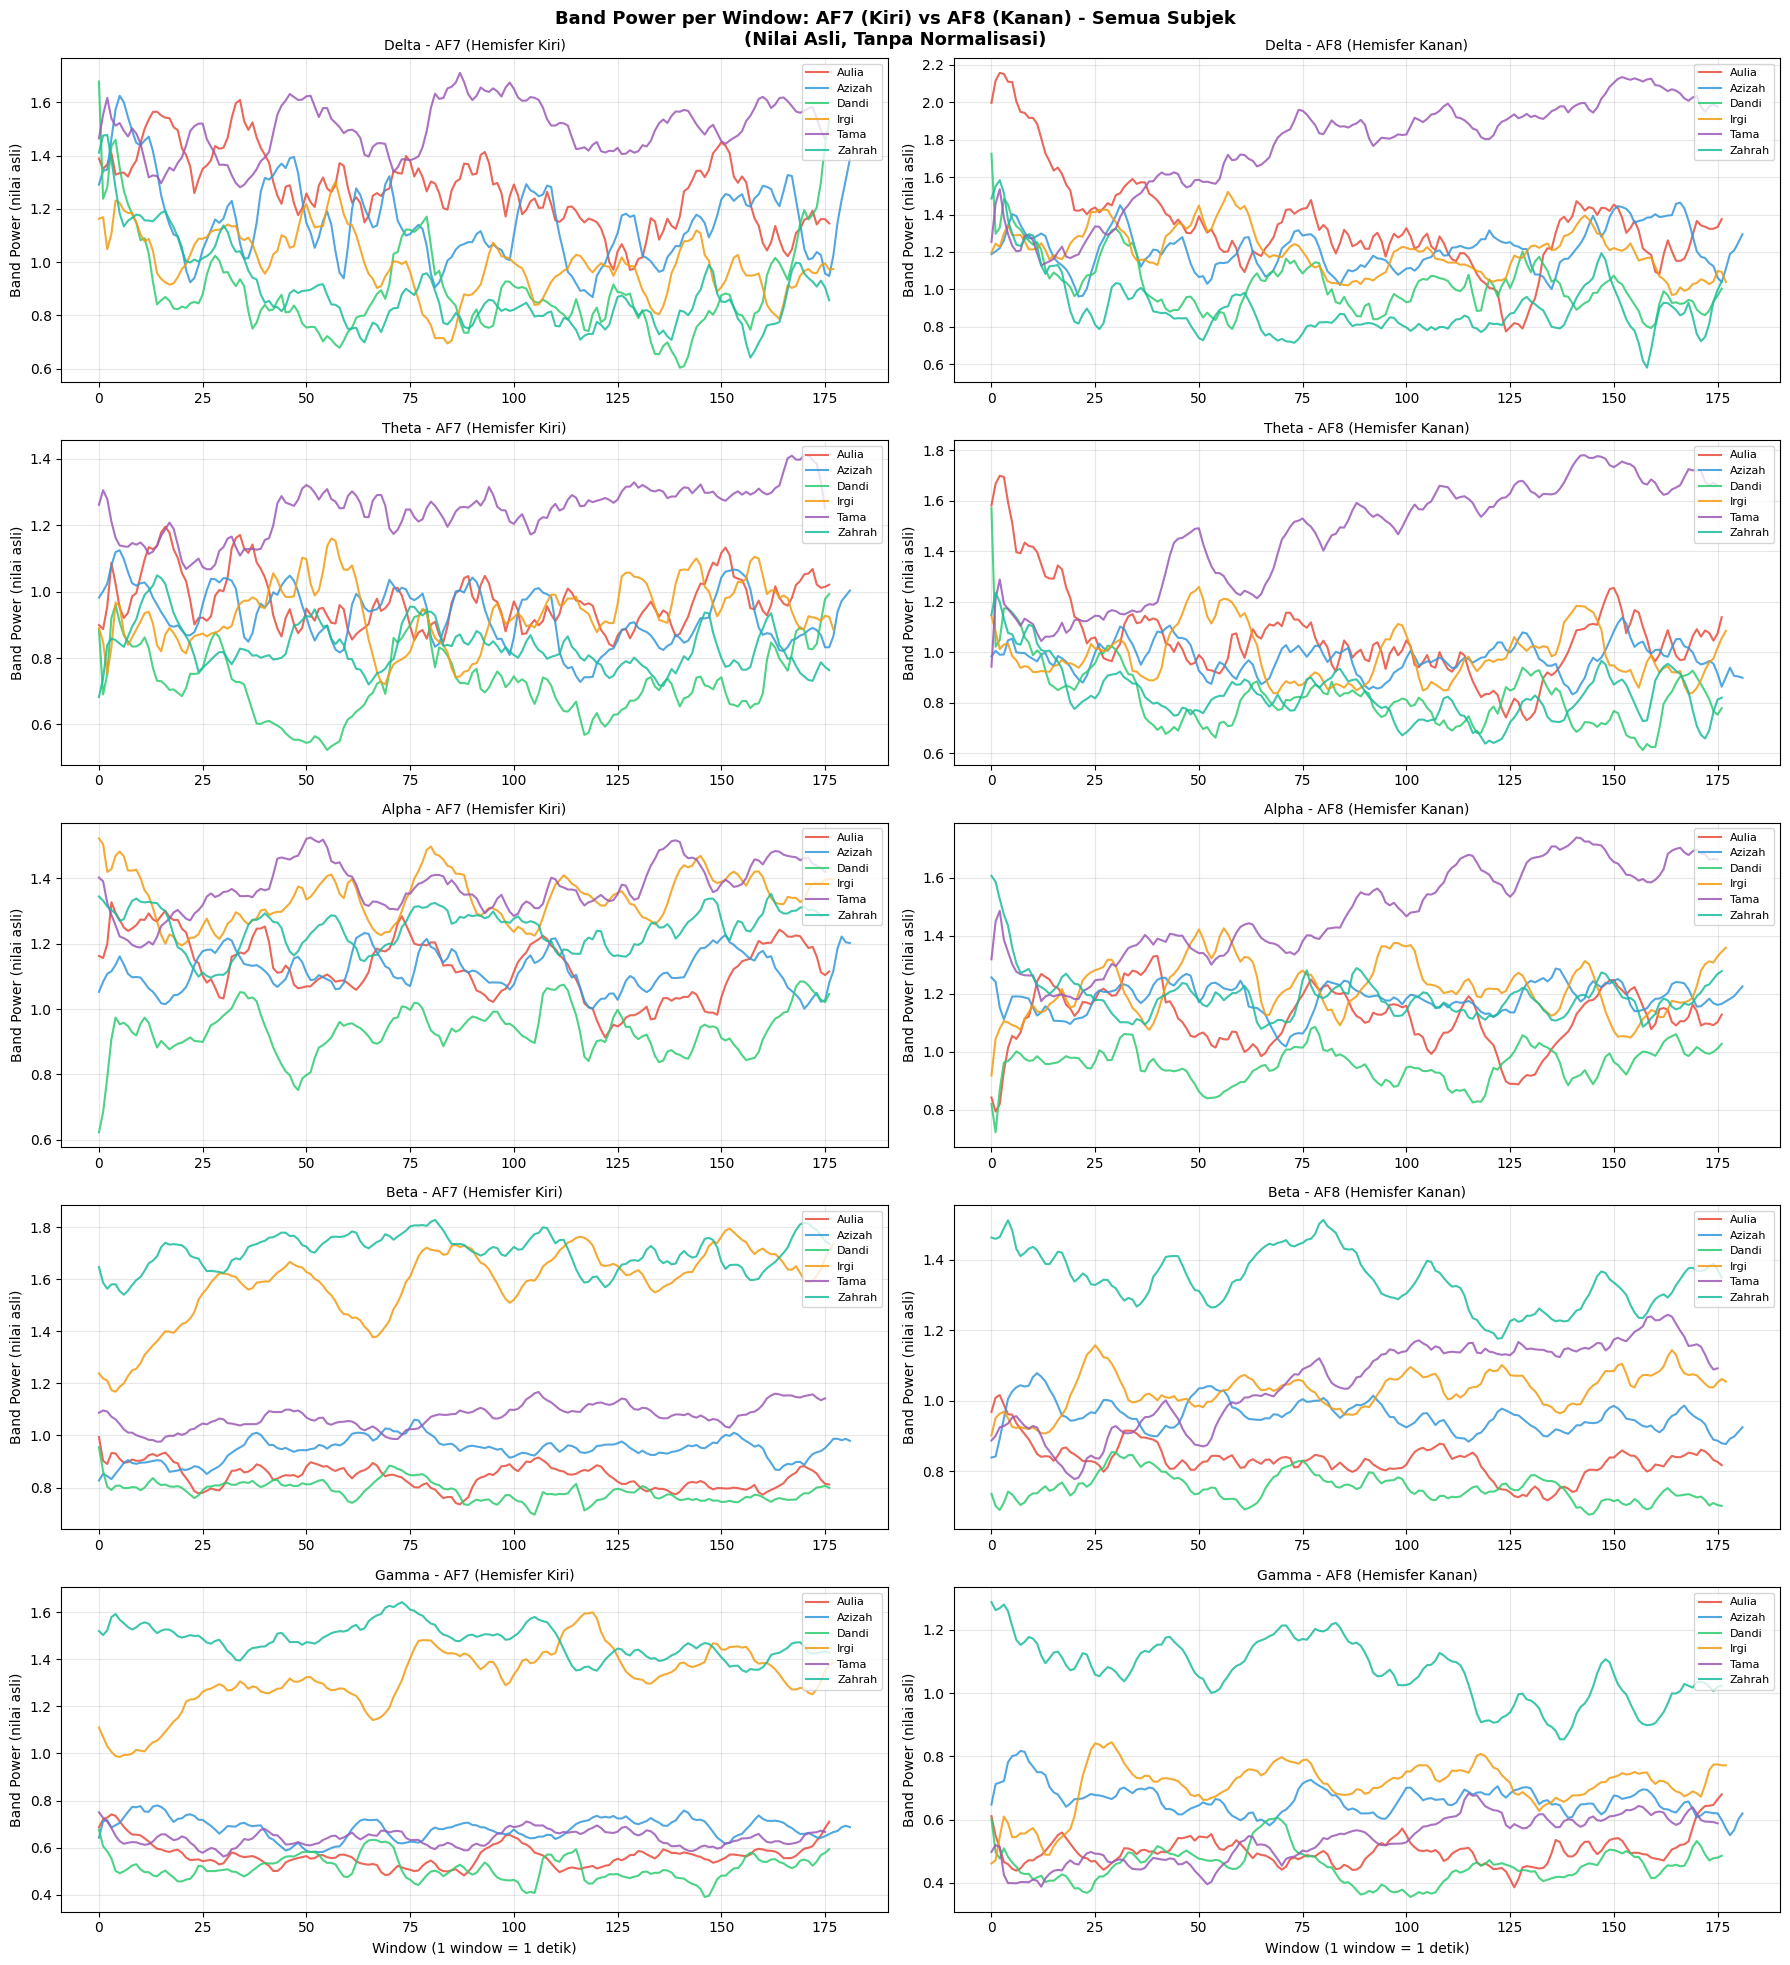

In [ ]:
# ============================================================
# CELL 7b - Visualisasi: AF7 vs AF8 per band, semua subjek
# Kiri = AF7 (hemisfer kiri), Kanan = AF8 (hemisfer kanan)
# ============================================================

fig, axes = plt.subplots(5, 2, figsize=(18, 20))
fig.suptitle('Band Power per Window: AF7 (Kiri) vs AF8 (Kanan) - Semua Subjek\n(Nilai Asli, Tanpa Normalisasi)',
             fontsize=13, fontweight='bold')

for i, band in enumerate(BANDS):
    for nama, df in data_window.items():

        smooth_af7 = df[f'{band}_AF7'].rolling(window=10, min_periods=1).mean()
        smooth_af8 = df[f'{band}_AF8'].rolling(window=10, min_periods=1).mean()

        axes[i][0].plot(df['window'], smooth_af7,
                        color=WARNA[nama], linewidth=1.5,
                        label=nama, alpha=0.85)
        axes[i][1].plot(df['window'], smooth_af8,
                        color=WARNA[nama], linewidth=1.5,
                        label=nama, alpha=0.85)

    axes[i][0].set_title(f'{band} - AF7 (Hemisfer Kiri)', fontsize=10)
    axes[i][0].set_ylabel('Band Power (nilai asli)')
    axes[i][0].legend(fontsize=8, loc='upper right')
    axes[i][0].grid(True, alpha=0.3)

    axes[i][1].set_title(f'{band} - AF8 (Hemisfer Kanan)', fontsize=10)
    axes[i][1].set_ylabel('Band Power (nilai asli)')
    axes[i][1].legend(fontsize=8, loc='upper right')
    axes[i][1].grid(True, alpha=0.3)

axes[4][0].set_xlabel('Window (1 window = 1 detik)')
axes[4][1].set_xlabel('Window (1 window = 1 detik)')

plt.tight_layout()
plt.show()

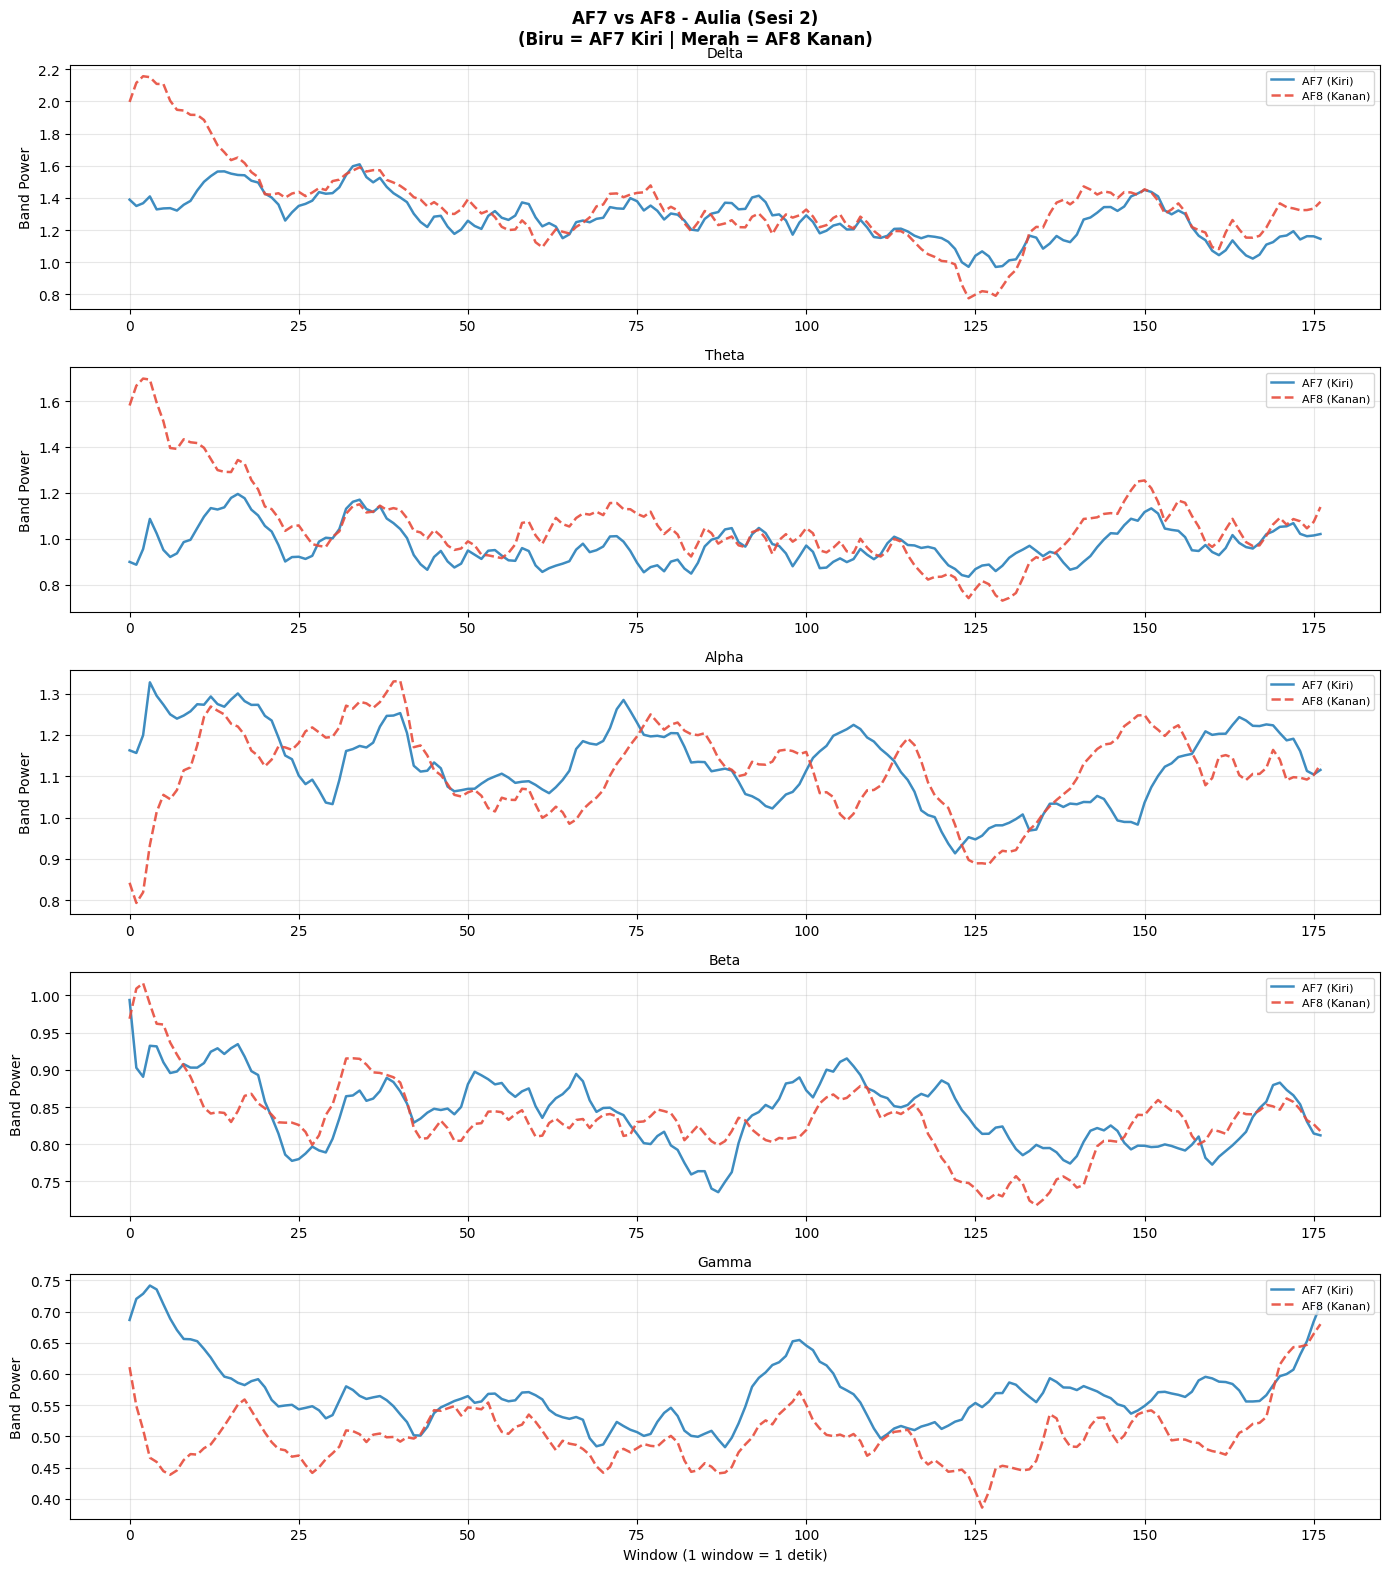

Selesai plot Aulia



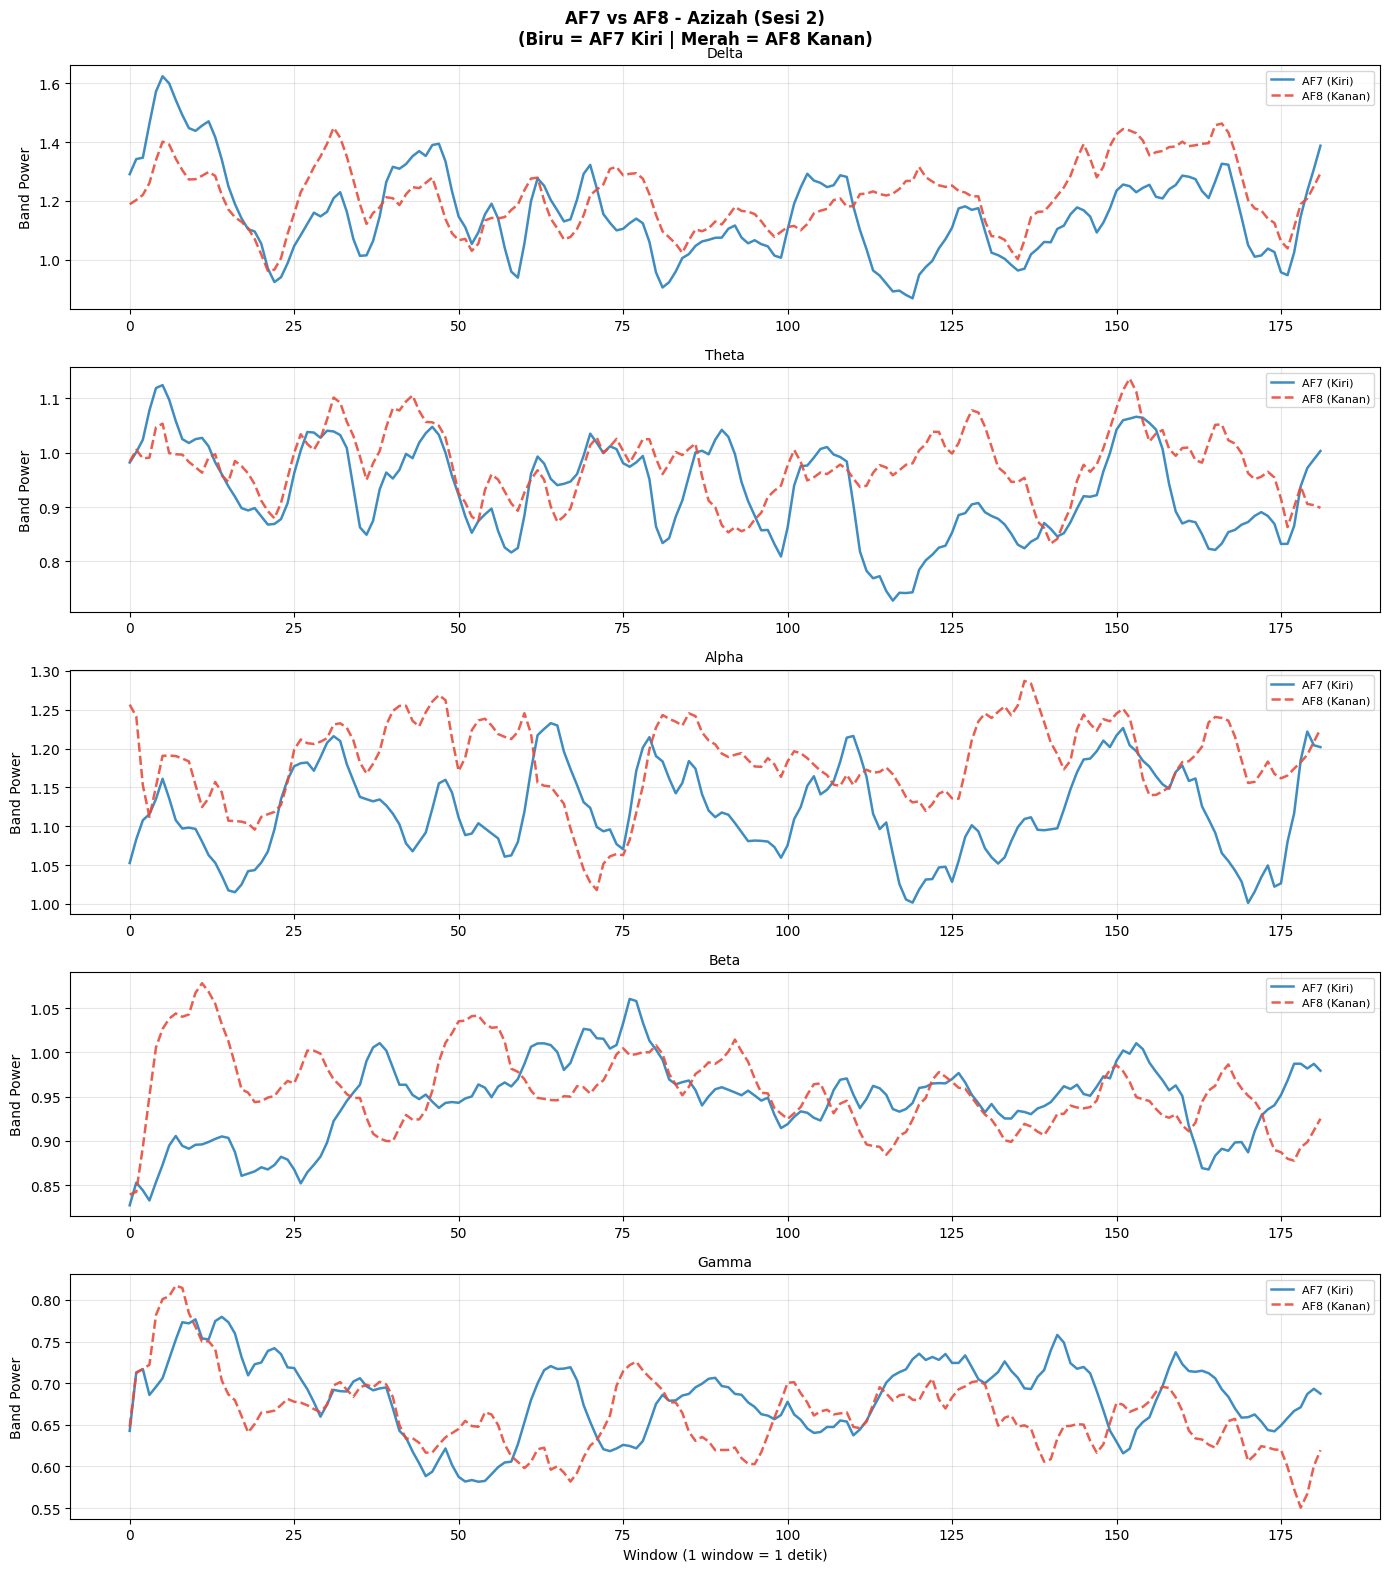

Selesai plot Azizah



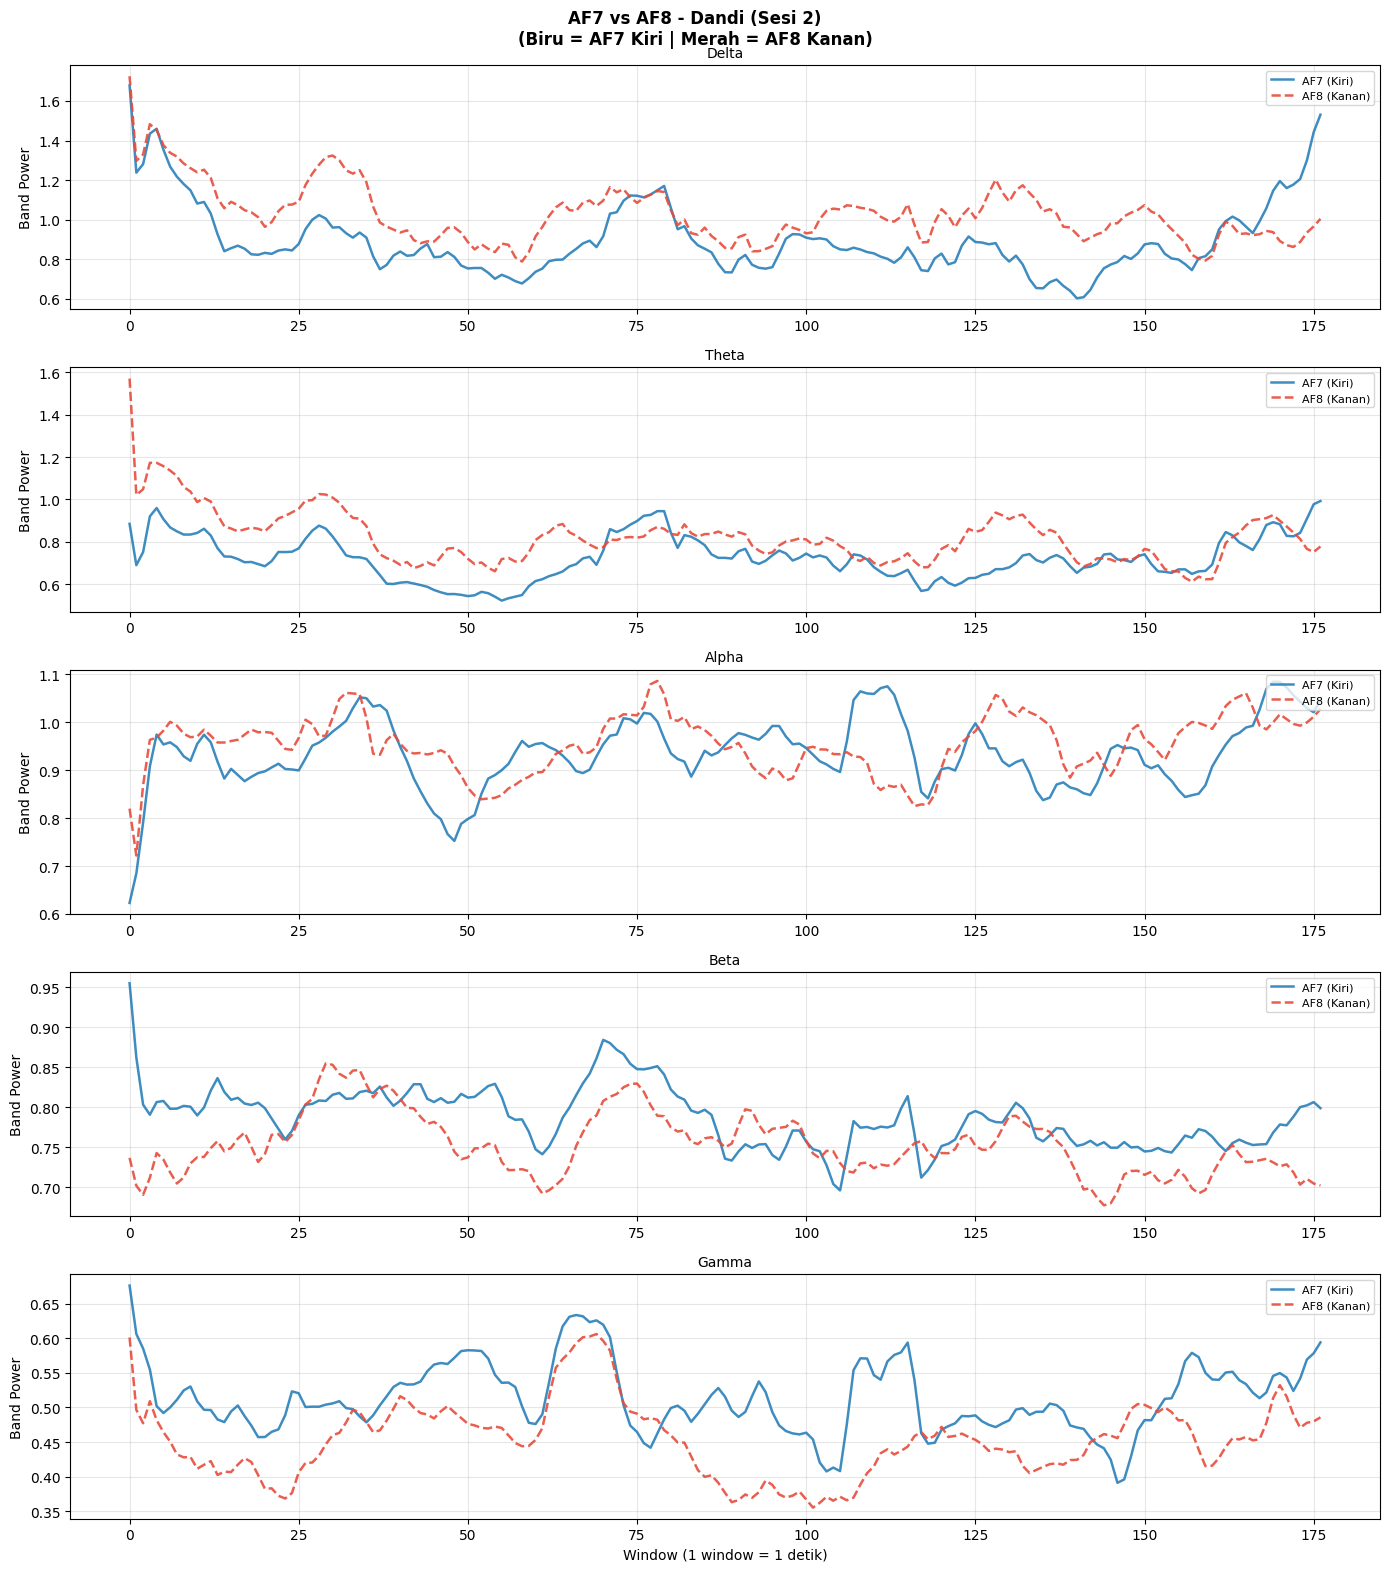

Selesai plot Dandi



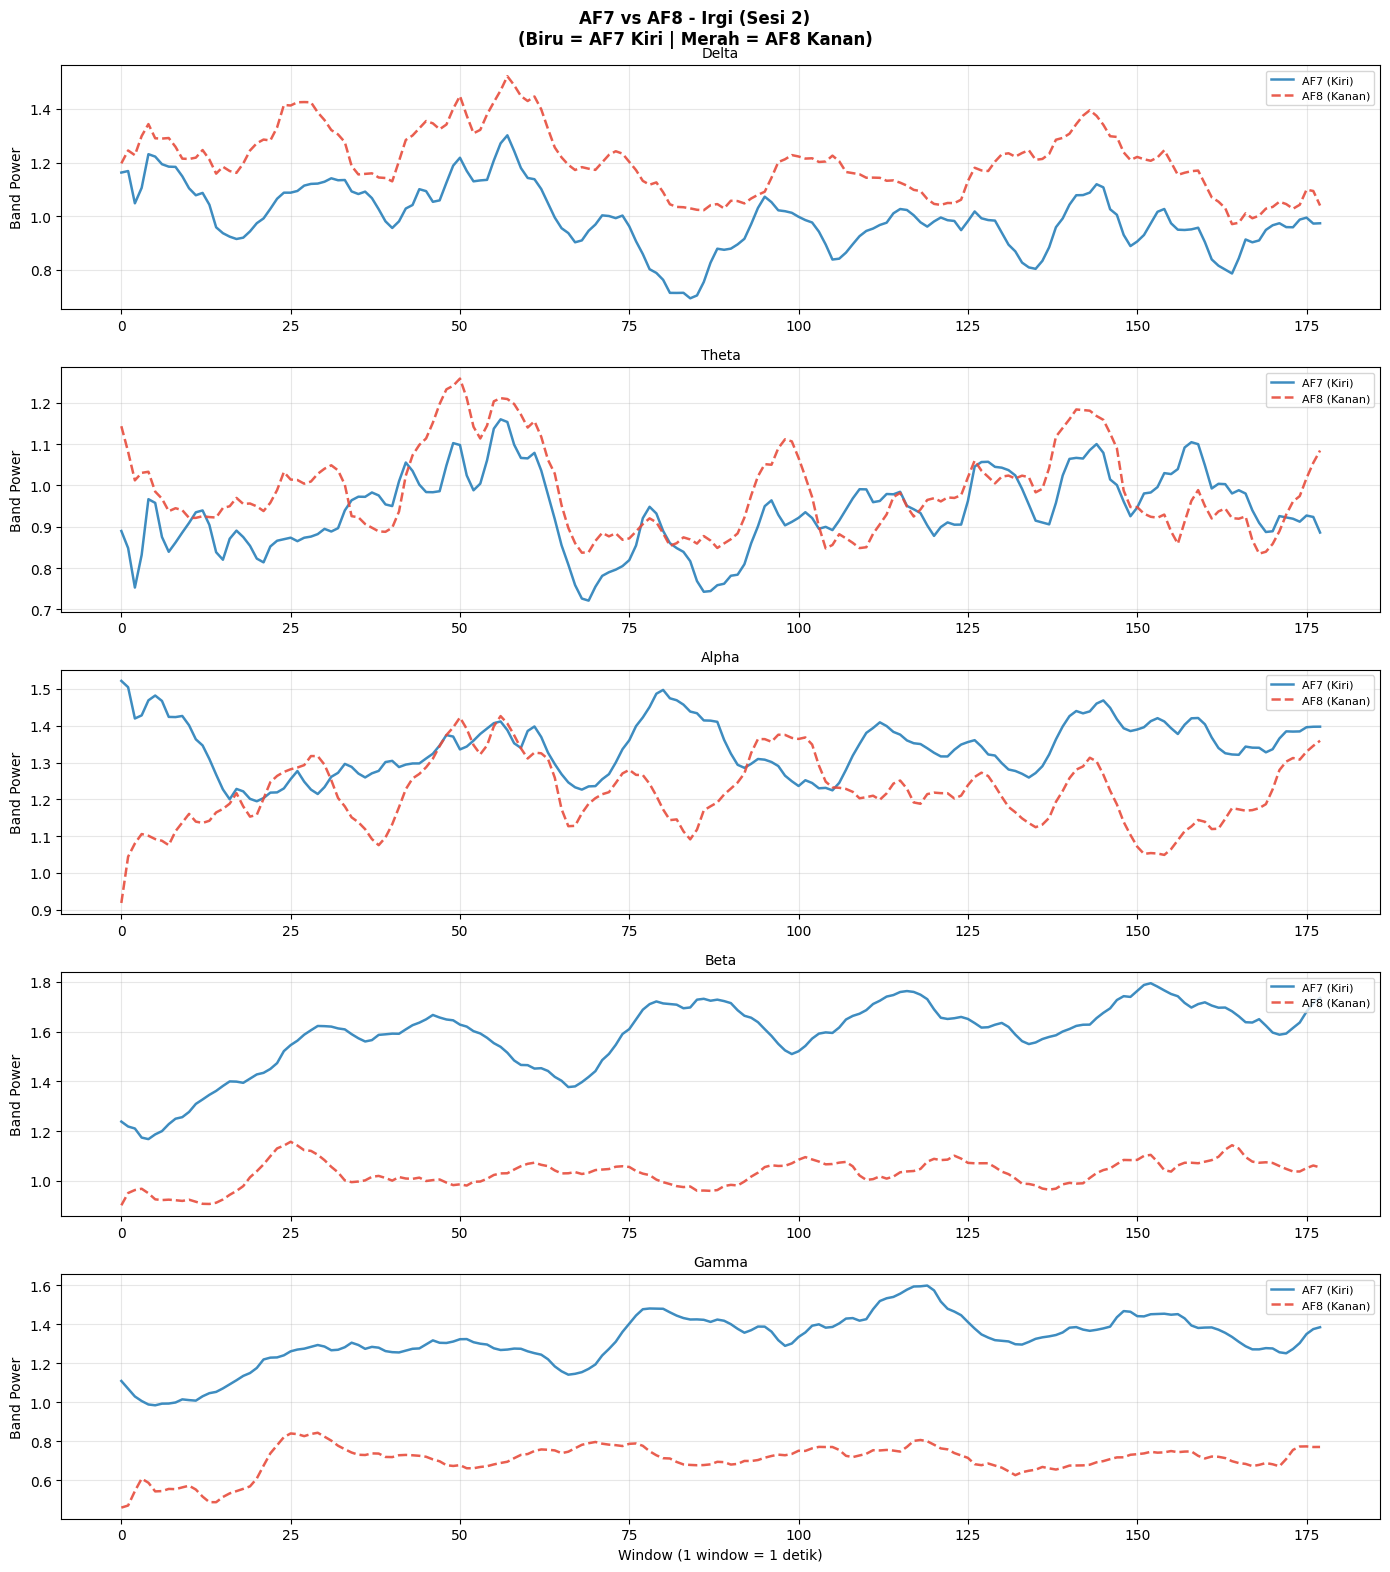

Selesai plot Irgi



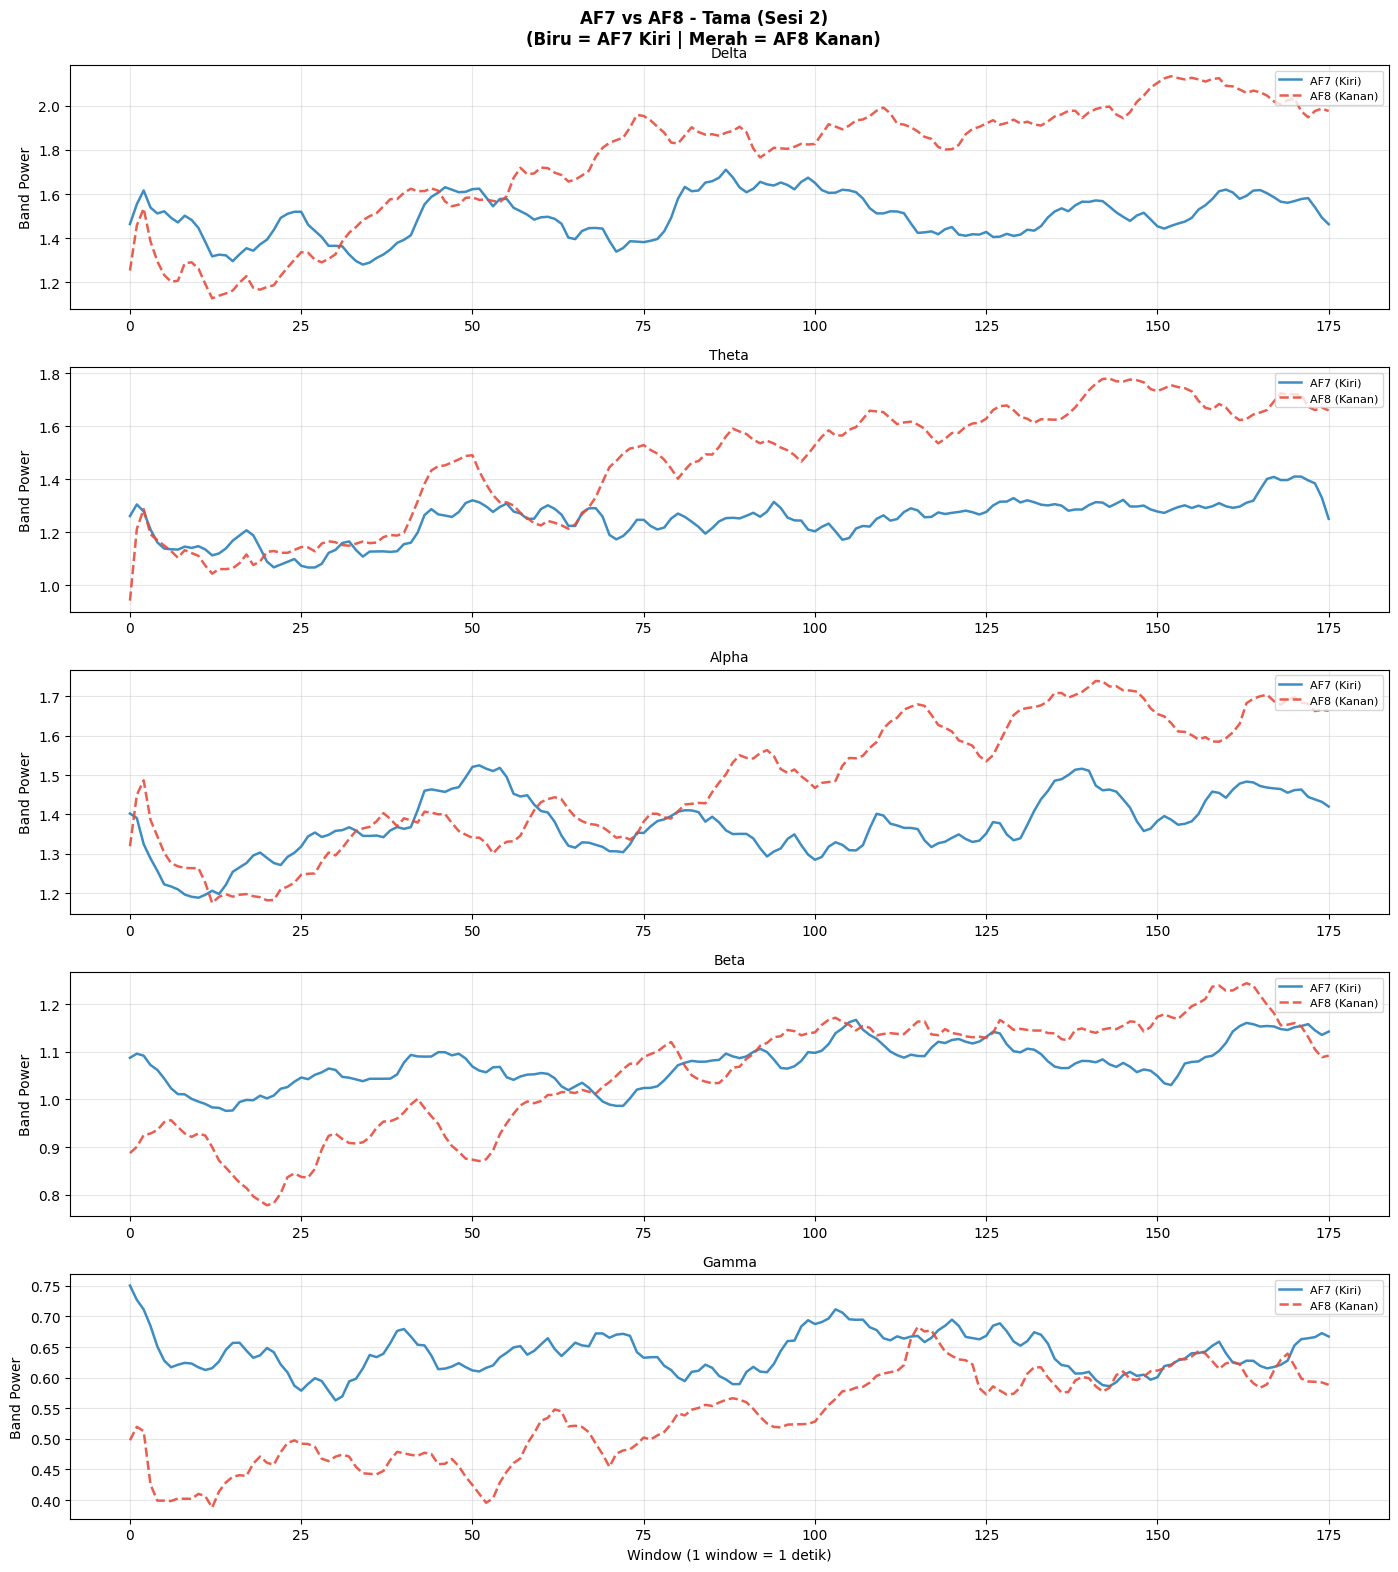

Selesai plot Tama



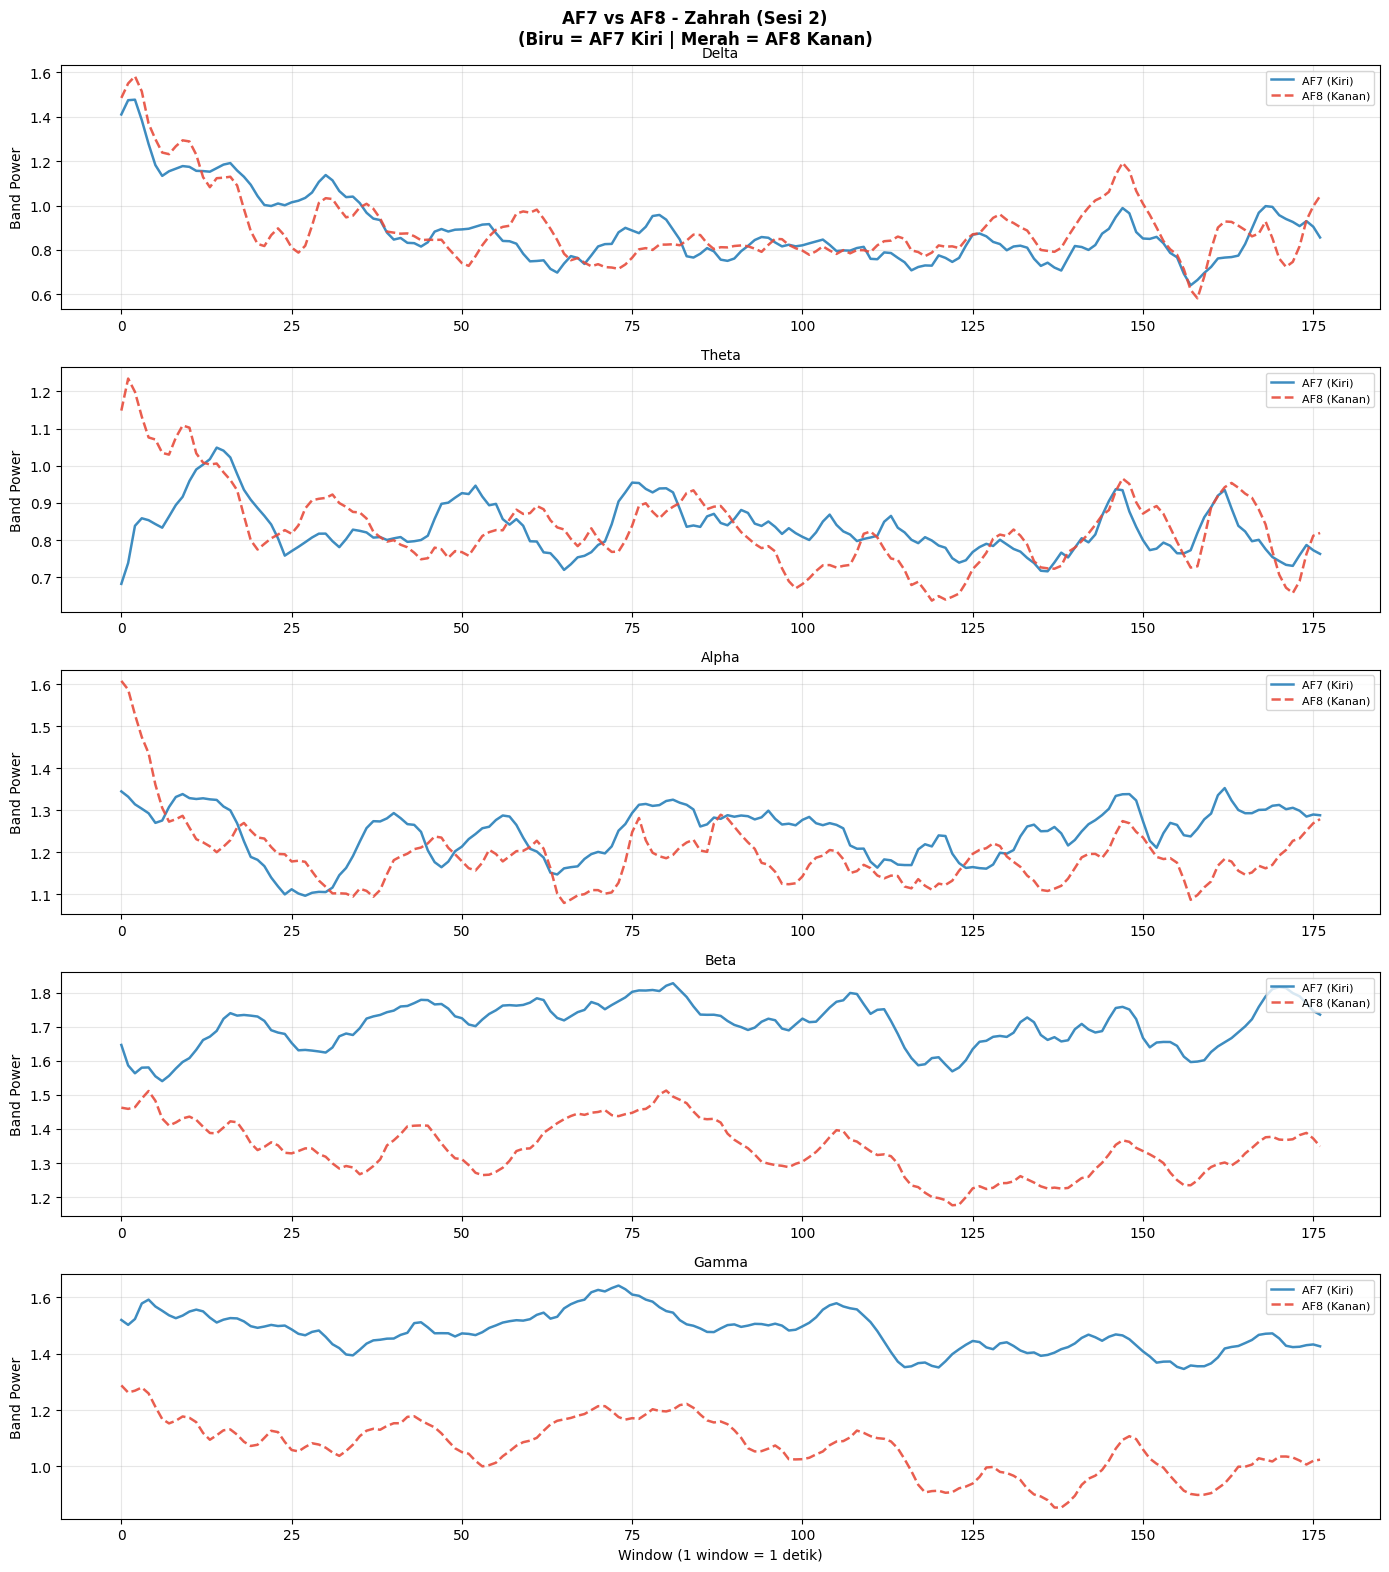

Selesai plot Zahrah



In [ ]:
# ============================================================
# CELL 7c - Visualisasi: AF7 vs AF8 per SUBJEK
# Untuk masing-masing orang, tampilkan perbedaan AF7 dan AF8
# dalam satu plot agar asimetri hemisfer terlihat jelas
# ============================================================

for nama, df in data_window.items():

    fig, axes = plt.subplots(5, 1, figsize=(14, 16))
    fig.suptitle(f'AF7 vs AF8 - {nama} (Sesi 2)\n(Biru = AF7 Kiri | Merah = AF8 Kanan)',
                 fontsize=12, fontweight='bold')

    for i, band in enumerate(BANDS):

        s_af7 = df[f'{band}_AF7'].rolling(window=10, min_periods=1).mean()
        s_af8 = df[f'{band}_AF8'].rolling(window=10, min_periods=1).mean()

        axes[i].plot(df['window'], s_af7,
                     color='#2980b9', linewidth=1.8, label='AF7 (Kiri)', alpha=0.9)
        axes[i].plot(df['window'], s_af8,
                     color='#e74c3c', linewidth=1.8, label='AF8 (Kanan)', alpha=0.9,
                     linestyle='--')

        axes[i].set_title(f'{band}', fontsize=10)
        axes[i].set_ylabel('Band Power')
        axes[i].legend(fontsize=8, loc='upper right')
        axes[i].grid(True, alpha=0.3)

    axes[4].set_xlabel('Window (1 window = 1 detik)')

    plt.tight_layout()
    plt.show()
    print(f'Selesai plot {nama}\n')

In [ ]:
# ============================================================
# CELL 8 - Hitung Rasio per Sensor (AF7 dan AF8 terpisah)
# Rasio dihitung dari nilai min shift yang sudah melalui sliding window
#
# Theta / Alpha = Drowsiness (ngantuk/melamun)
# Beta  / Alpha = Alertness (fokus/waspada)
# Beta  / Theta = Cognitive Engagement (keterlibatan mental)
# ============================================================

data_rasio = {}

EPSILON = 1e-9  # Hindari pembagian dengan nol tanpa distorsi nilai

for nama, df in data_window.items():

    df_rasio = pd.DataFrame()
    df_rasio['window'] = df['window']

    for sensor in ['AF7', 'AF8']:
        theta = df[f'Theta_{sensor}'] + EPSILON
        alpha = df[f'Alpha_{sensor}'] + EPSILON

        df_rasio[f'theta_alpha_{sensor}'] = theta / alpha

    data_rasio[nama] = df_rasio

print('Rasio berhasil dihitung per sensor (AF7 dan AF8 terpisah)')
print('\nPreview:')
display(data_rasio[list(data_rasio.keys())[0]].head(5))

Rasio berhasil dihitung per sensor (AF7 dan AF8 terpisah)

Preview:


,window,theta_alpha_AF7,theta_alpha_AF8
0,0,0.773504,1.877037
1,1,0.760672,2.355149
2,2,0.849601,2.022425
3,3,0.865424,1.316578
4,4,0.662036,0.895550


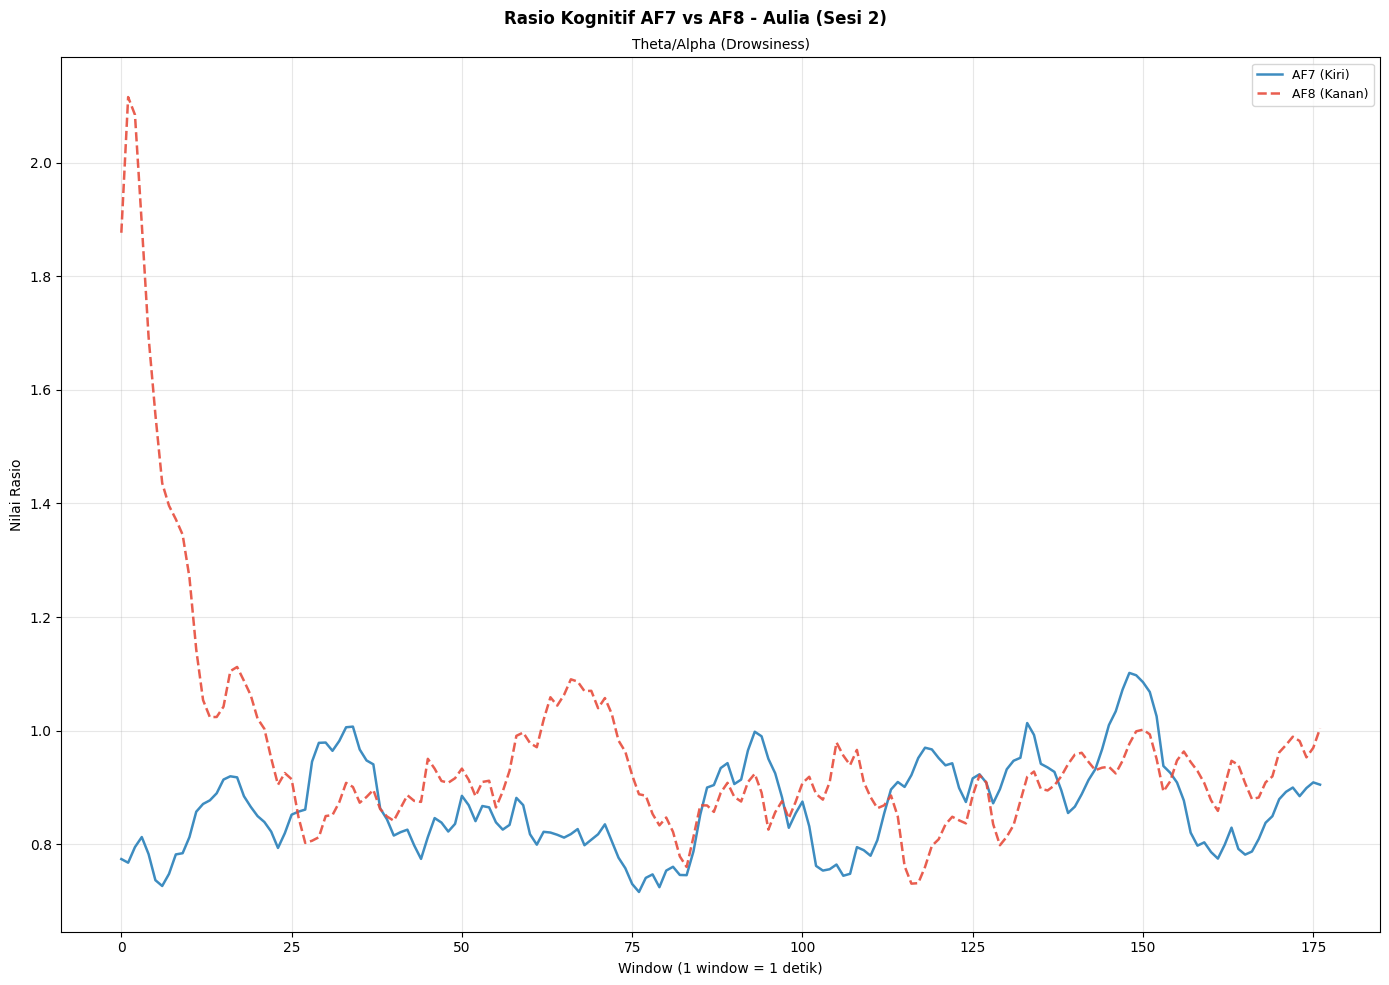

Selesai plot Aulia



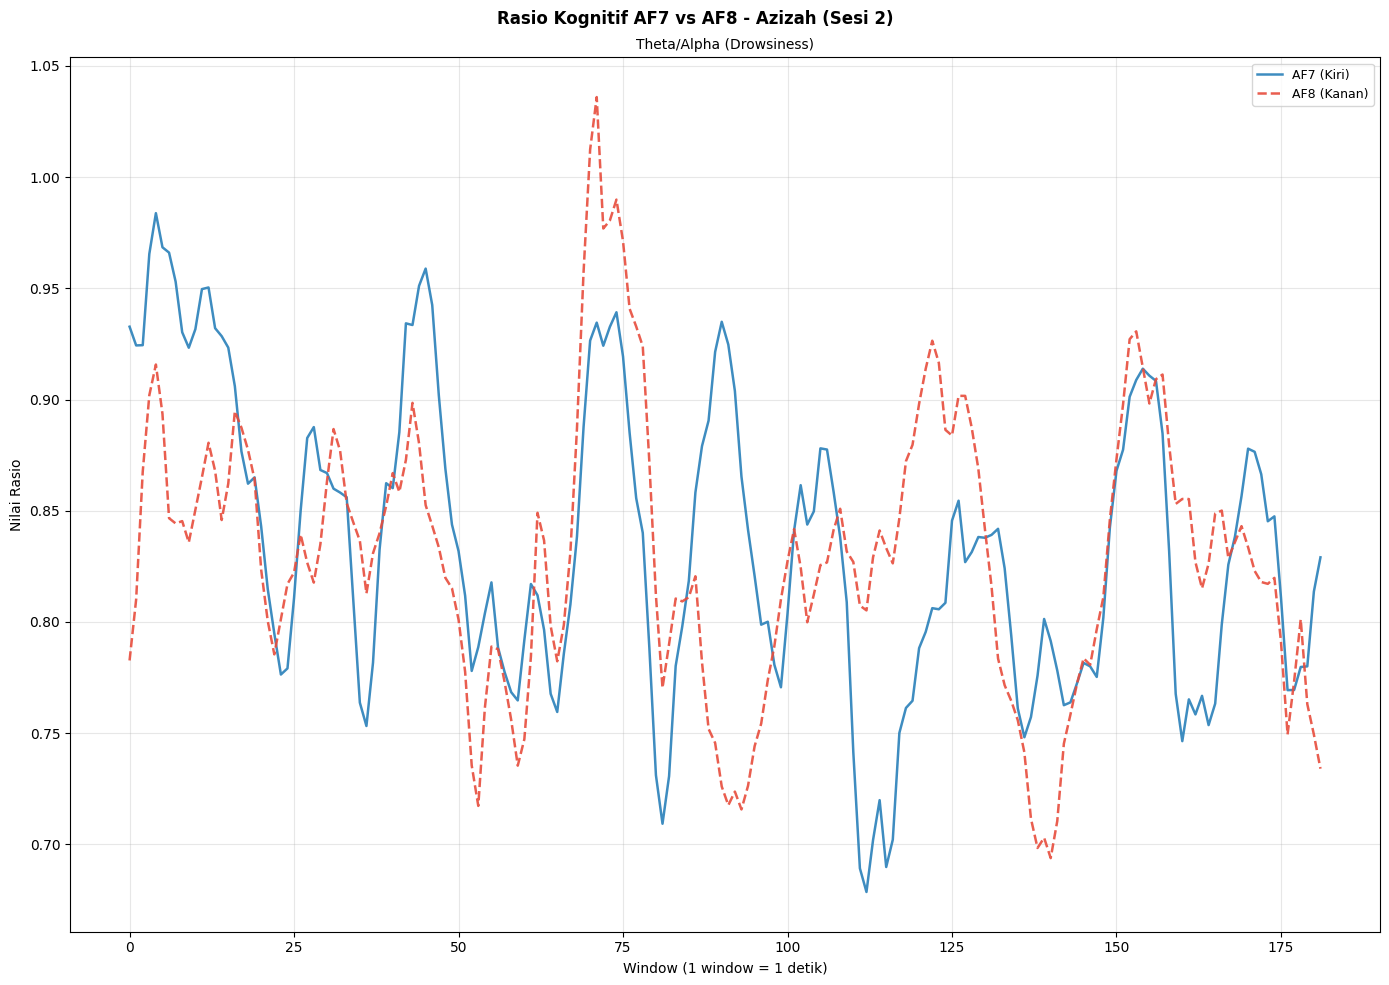

Selesai plot Azizah



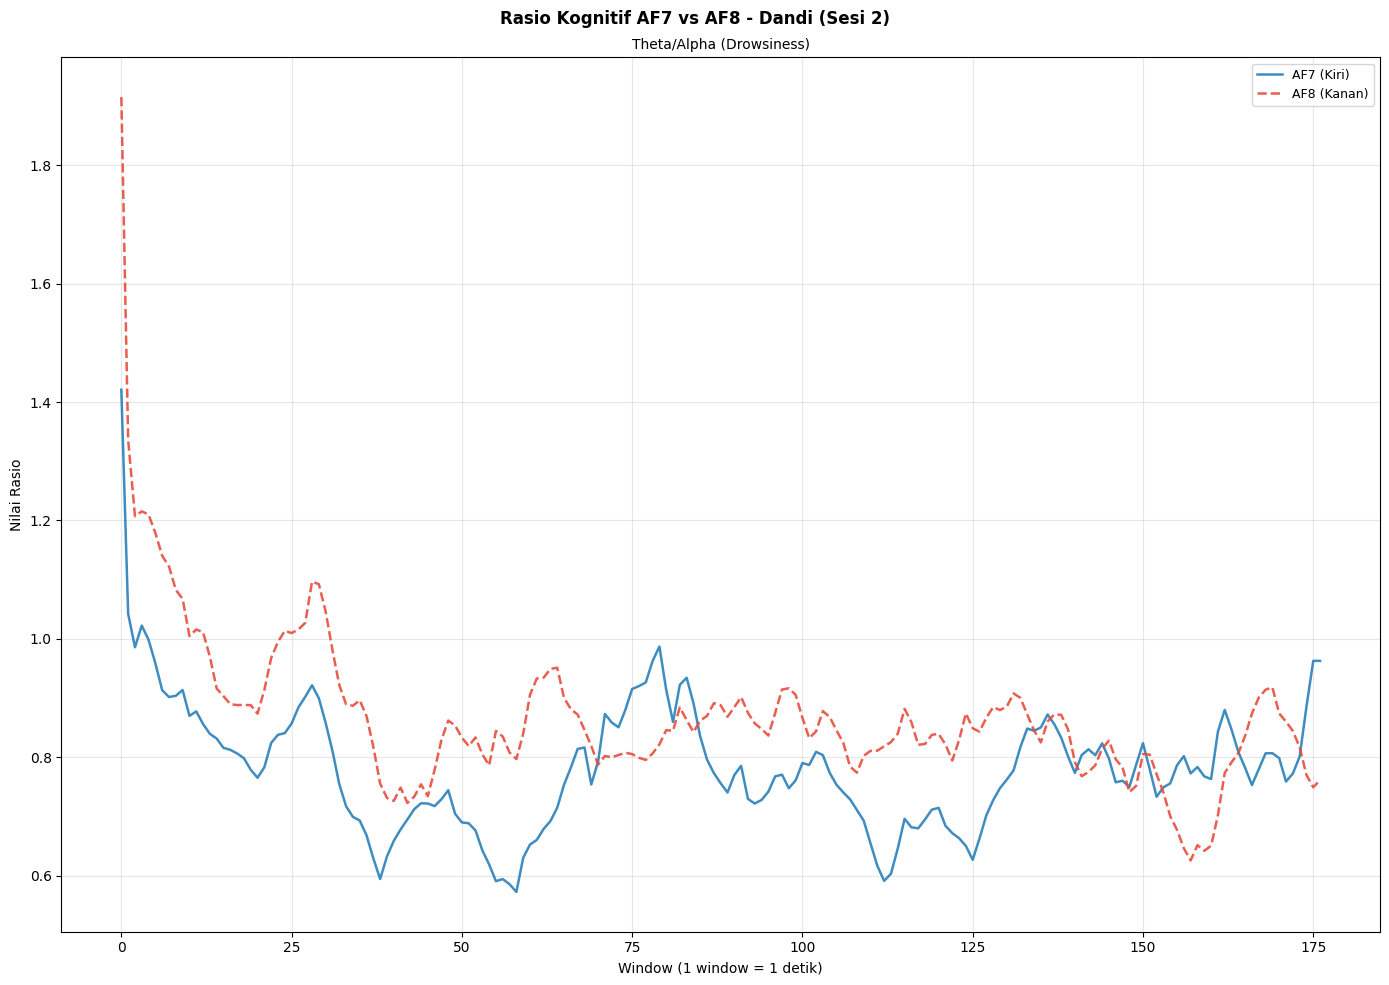

Selesai plot Dandi



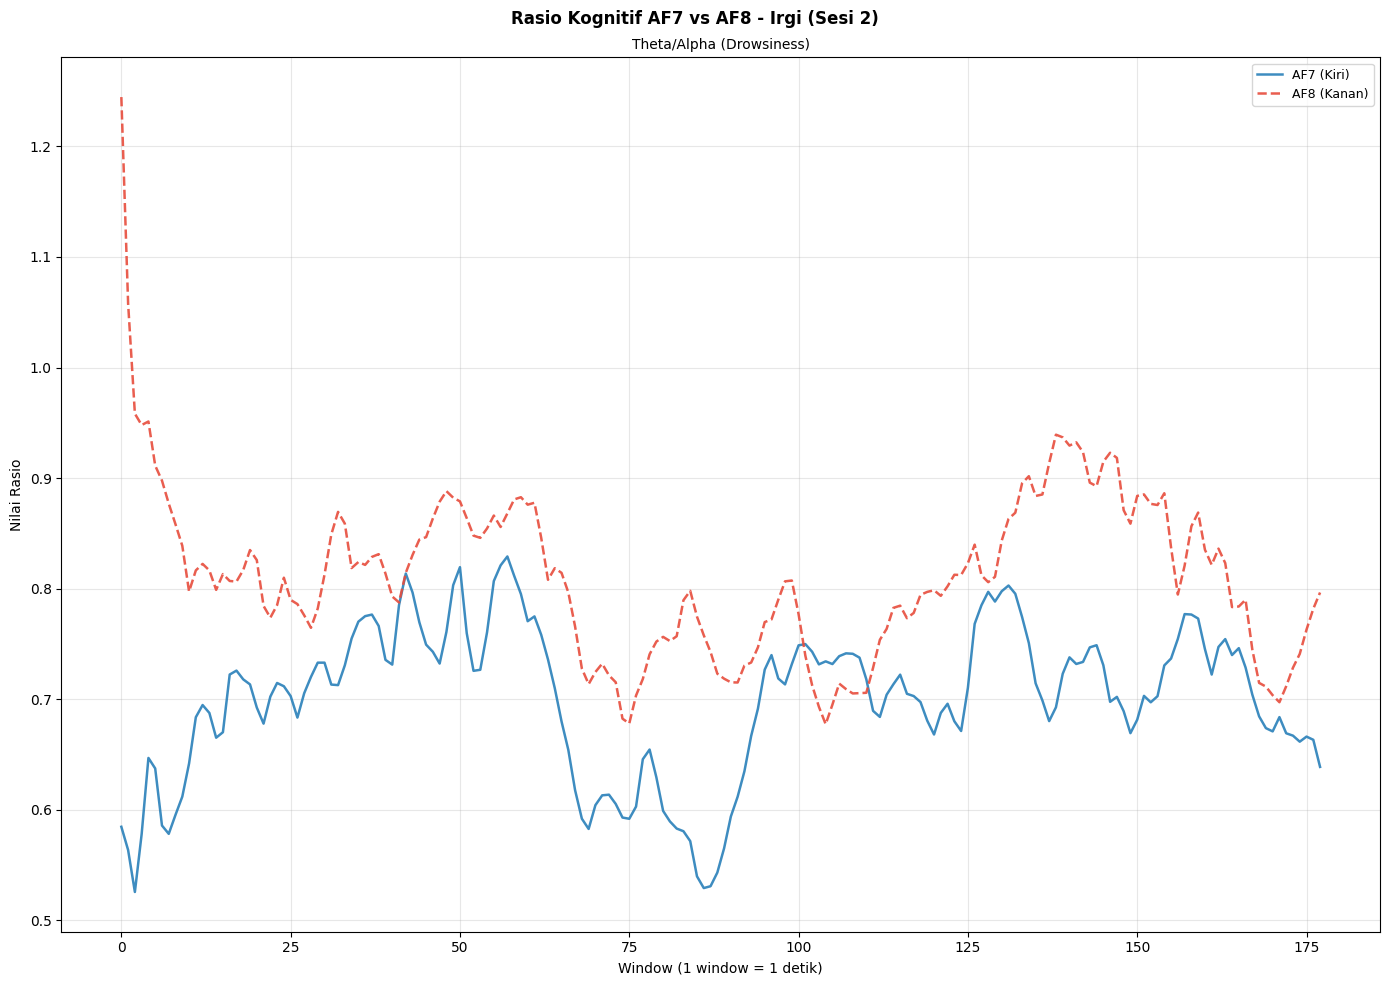

Selesai plot Irgi



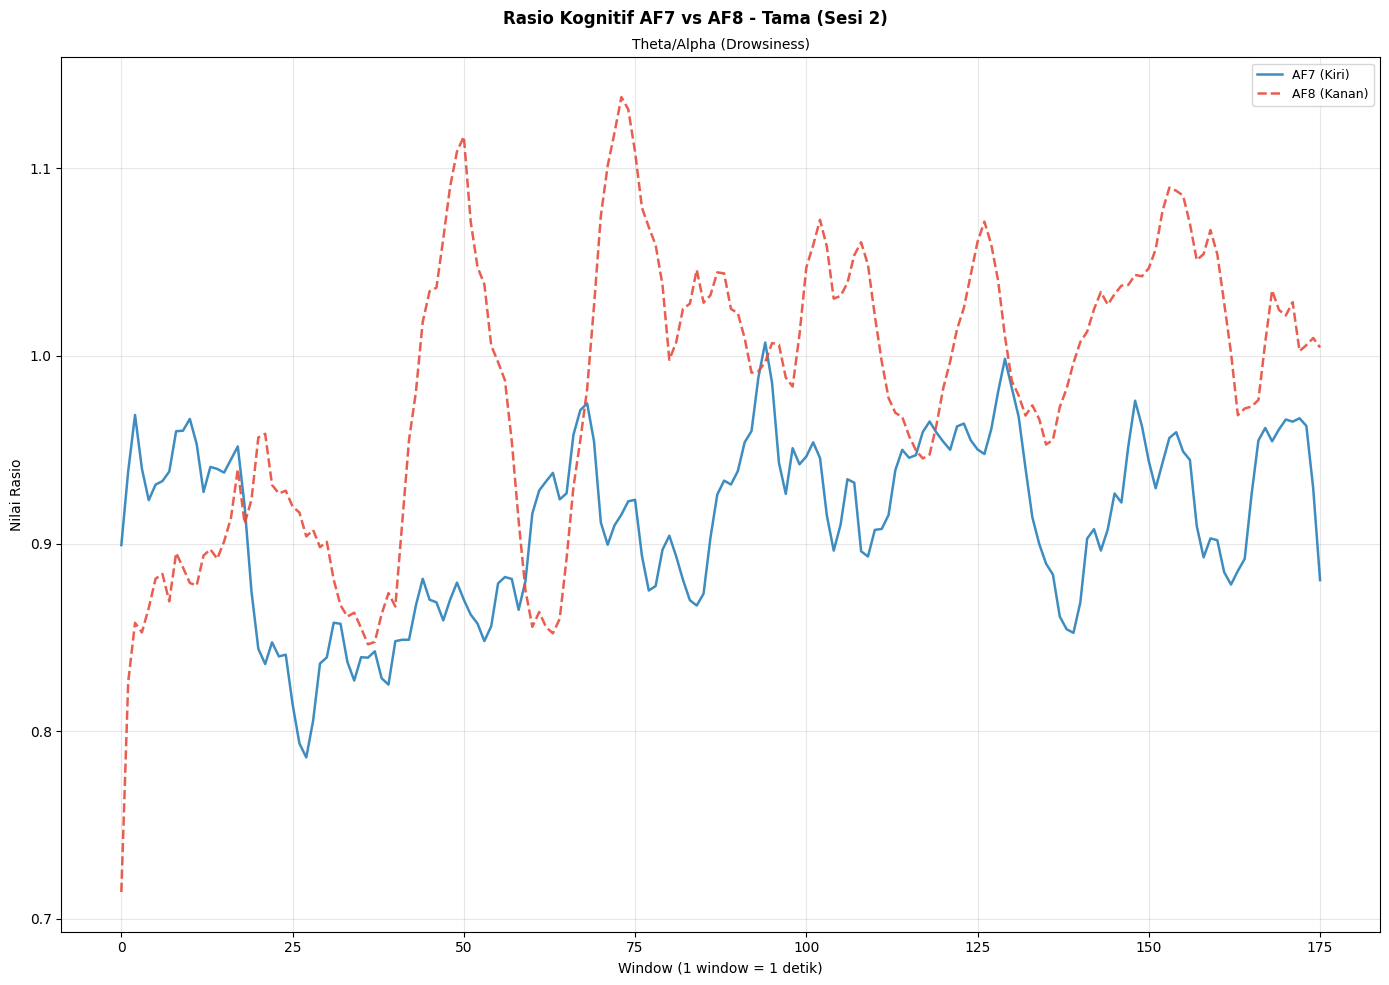

Selesai plot Tama



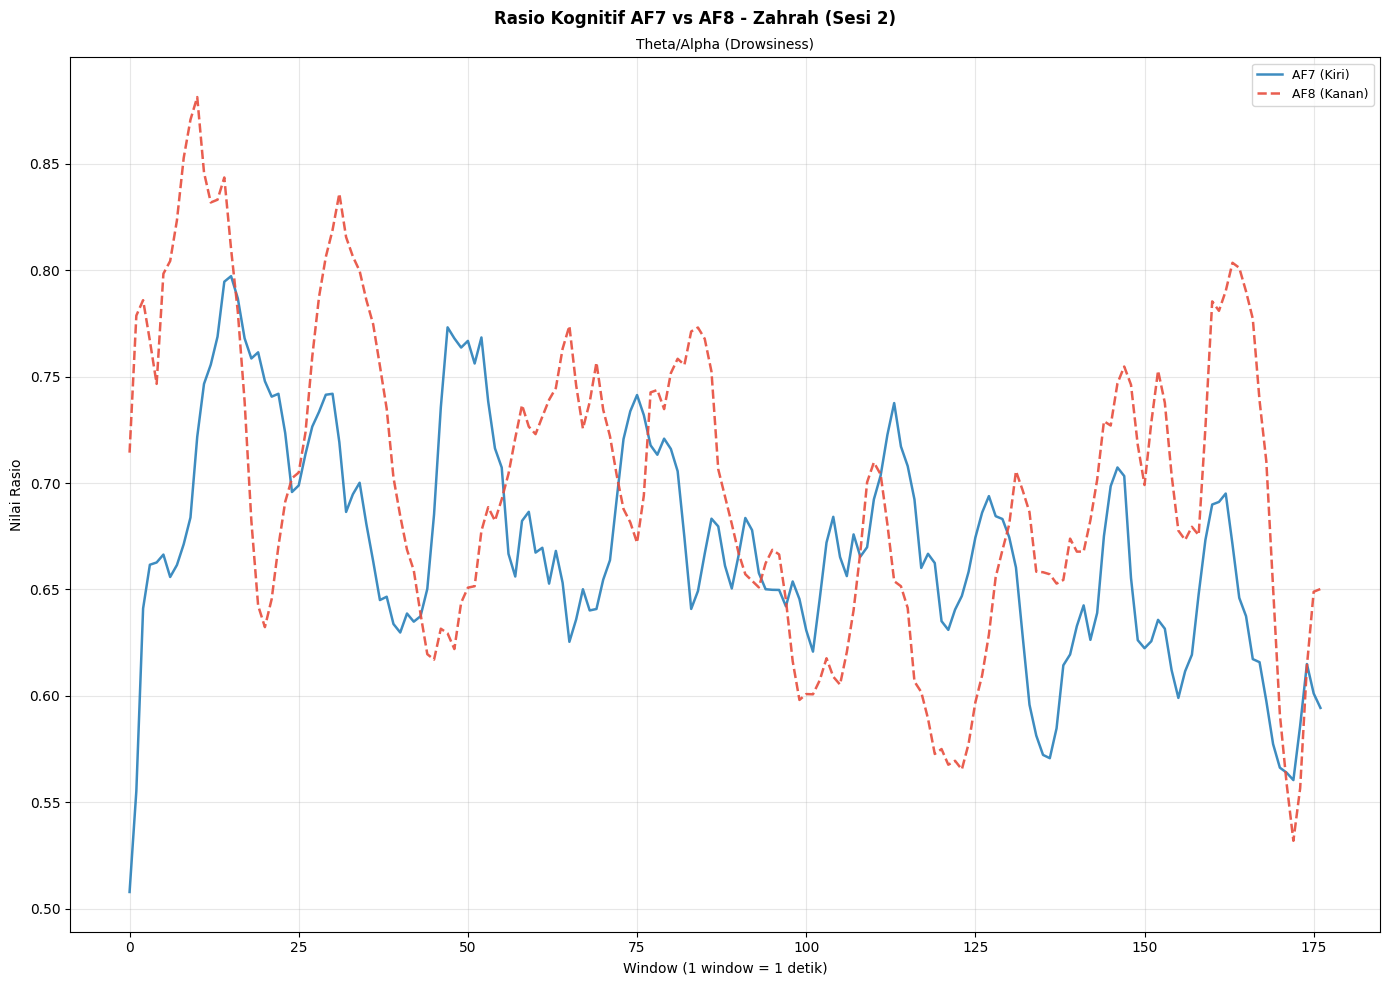

Selesai plot Zahrah



In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# CELL 8b - Visualisasi Rasio: AF7 vs AF8 per Subjek
# Bandingkan 3 rasio antara hemisfer kiri (AF7) dan kanan (AF8)
# ============================================================

RASIO_LIST = [
    ('theta_alpha', 'Theta/Alpha (Drowsiness)'),
]

for nama, df in data_rasio.items():

    fig, ax = plt.subplots(1, 1, figsize=(14, 10)) # Unpack directly to ax instead of axes
    fig.suptitle(f'Rasio Kognitif AF7 vs AF8 - {nama} (Sesi 2)',
                 fontsize=12, fontweight='bold')

    # The loop will run once with i=0, as RASIO_LIST currently has only one item.
    # 'ax' is a single Axes object, so we use 'ax' directly instead of 'ax[i]'
    for i, (rasio_key, rasio_label) in enumerate(RASIO_LIST):

        s_af7 = df[f'{rasio_key}_AF7'].rolling(window=10, min_periods=1).mean()
        s_af8 = df[f'{rasio_key}_AF8'].rolling(window=10, min_periods=1).mean()

        ax.plot(df['window'], s_af7,
                     color='#2980b9', linewidth=1.8, label='AF7 (Kiri)', alpha=0.9)
        ax.plot(df['window'], s_af8,
                     color='#e74c3c', linewidth=1.8, label='AF8 (Kanan)', alpha=0.9,
                     linestyle='--')

        ax.set_title(rasio_label, fontsize=10)
        ax.set_ylabel('Nilai Rasio')
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(True, alpha=0.3)

    # Since there is only one subplot (ax), accessing axes[2] is incorrect.
    # The xlabel should be set on the single axes object 'ax'.
    ax.set_xlabel('Window (1 window = 1 detik)')

    plt.tight_layout()
    plt.show()
    print(f'Selesai plot {nama}\n')

In [ ]:
# ============================================================
# CELL 9 - Ringkasan Statistik per Subjek
# Mean, Std, Min, Max dari Theta/Alpha di AF7 dan AF8
# ============================================================

print('=' * 65)
print('RINGKASAN STATISTIK: Theta/Alpha (Cognitive Load Index)')
print('AF7 = Hemisfer Kiri | AF8 = Hemisfer Kanan')
print('=' * 65)

for nama, df in data_rasio.items():
    print(f'\n{nama}:')
    print(f'  {"Sensor":<10} {"Mean":>10} {"Std":>10} {"Min":>10} {"Max":>10}')
    print(f'  {"-"*50}')

    for sensor in ['AF7', 'AF8']:
        kolom = f'theta_alpha_{sensor}'
        mean = df[kolom].mean()
        std  = df[kolom].std()
        mn   = df[kolom].min()
        mx   = df[kolom].max()
        print(f'  {sensor:<10} {mean:>10.4f} {std:>10.4f} {mn:>10.4f} {mx:>10.4f}')

    asimetri = df['theta_alpha_AF7'].mean() - df['theta_alpha_AF8'].mean()
    print(f'  Asimetri (AF7 - AF8): {asimetri:+.4f}')
    if asimetri > 0:
        print(f'  → Hemisfer kiri lebih aktif')
    elif asimetri < 0:
        print(f'  → Hemisfer kanan lebih aktif')
    else:
        print(f'  → Kedua hemisfer seimbang')

RINGKASAN STATISTIK: Theta/Alpha (Cognitive Load Index)
AF7 = Hemisfer Kiri | AF8 = Hemisfer Kanan

Aulia:
  Sensor           Mean        Std        Min        Max
  --------------------------------------------------
  AF7            0.8692     0.1972     0.3562     1.5997
  AF8            0.9401     0.2495     0.4645     2.3551
  Asimetri (AF7 - AF8): -0.0709
  → Hemisfer kanan lebih aktif

Azizah:
  Sensor           Mean        Std        Min        Max
  --------------------------------------------------
  AF7            0.8342     0.1705     0.4470     1.3581
  AF8            0.8274     0.1625     0.4272     1.4824
  Asimetri (AF7 - AF8): +0.0069
  → Hemisfer kiri lebih aktif

Dandi:
  Sensor           Mean        Std        Min        Max
  --------------------------------------------------
  AF7            0.7805     0.2071     0.3845     1.5068
  AF8            0.8519     0.2223     0.3689     1.9154
  Asimetri (AF7 - AF8): -0.0714
  → Hemisfer kanan lebih aktif

Irgi:
  Sensor 

In [ ]:
# ============================================================
# CELL 9b - Uji Statistik: Wilcoxon Signed-Rank Test
# Menguji apakah perbedaan AF7 vs AF8 signifikan per subjek
# H0: Tidak ada perbedaan antara Theta/Alpha AF7 dan AF8
# H1: Ada perbedaan signifikan antara AF7 dan AF8
# ============================================================

from scipy.stats import wilcoxon

print('=' * 65)
print('UJI WILCOXON SIGNED-RANK TEST: AF7 vs AF8')
print('Theta/Alpha Ratio | Significance level: α = 0.05')
print('=' * 65)

for nama, df in data_rasio.items():
    af7 = df['theta_alpha_AF7'].dropna()
    af8 = df['theta_alpha_AF8'].dropna()

    # Pastikan panjang sama
    min_len = min(len(af7), len(af8))
    af7 = af7.iloc[:min_len]
    af8 = af8.iloc[:min_len]

    stat, p_value = wilcoxon(af7, af8)

    print(f'\n{nama}:')
    print(f'  Statistic : {stat:.4f}')
    print(f'  p-value   : {p_value:.4f}')

    if p_value < 0.05:
        print(f'  Hasil     : SIGNIFIKAN ✓ (p < 0.05)')
        if df['theta_alpha_AF7'].mean() > df['theta_alpha_AF8'].mean():
            print(f'  Arah      : AF7 (kiri) > AF8 (kanan)')
        else:
            print(f'  Arah      : AF8 (kanan) > AF7 (kiri)')
    else:
        print(f'  Hasil     : Tidak signifikan (p ≥ 0.05)')

UJI WILCOXON SIGNED-RANK TEST: AF7 vs AF8
Theta/Alpha Ratio | Significance level: α = 0.05

Aulia:
  Statistic : 5408.0000
  p-value   : 0.0003
  Hasil     : SIGNIFIKAN ✓ (p < 0.05)
  Arah      : AF8 (kanan) > AF7 (kiri)

Azizah:
  Statistic : 8139.0000
  p-value   : 0.7922
  Hasil     : Tidak signifikan (p ≥ 0.05)

Dandi:
  Statistic : 4983.0000
  p-value   : 0.0000
  Hasil     : SIGNIFIKAN ✓ (p < 0.05)
  Arah      : AF8 (kanan) > AF7 (kiri)

Irgi:
  Statistic : 2947.0000
  p-value   : 0.0000
  Hasil     : SIGNIFIKAN ✓ (p < 0.05)
  Arah      : AF8 (kanan) > AF7 (kiri)

Tama:
  Statistic : 4016.0000
  p-value   : 0.0000
  Hasil     : SIGNIFIKAN ✓ (p < 0.05)
  Arah      : AF8 (kanan) > AF7 (kiri)

Zahrah:
  Statistic : 6557.0000
  p-value   : 0.0533
  Hasil     : Tidak signifikan (p ≥ 0.05)


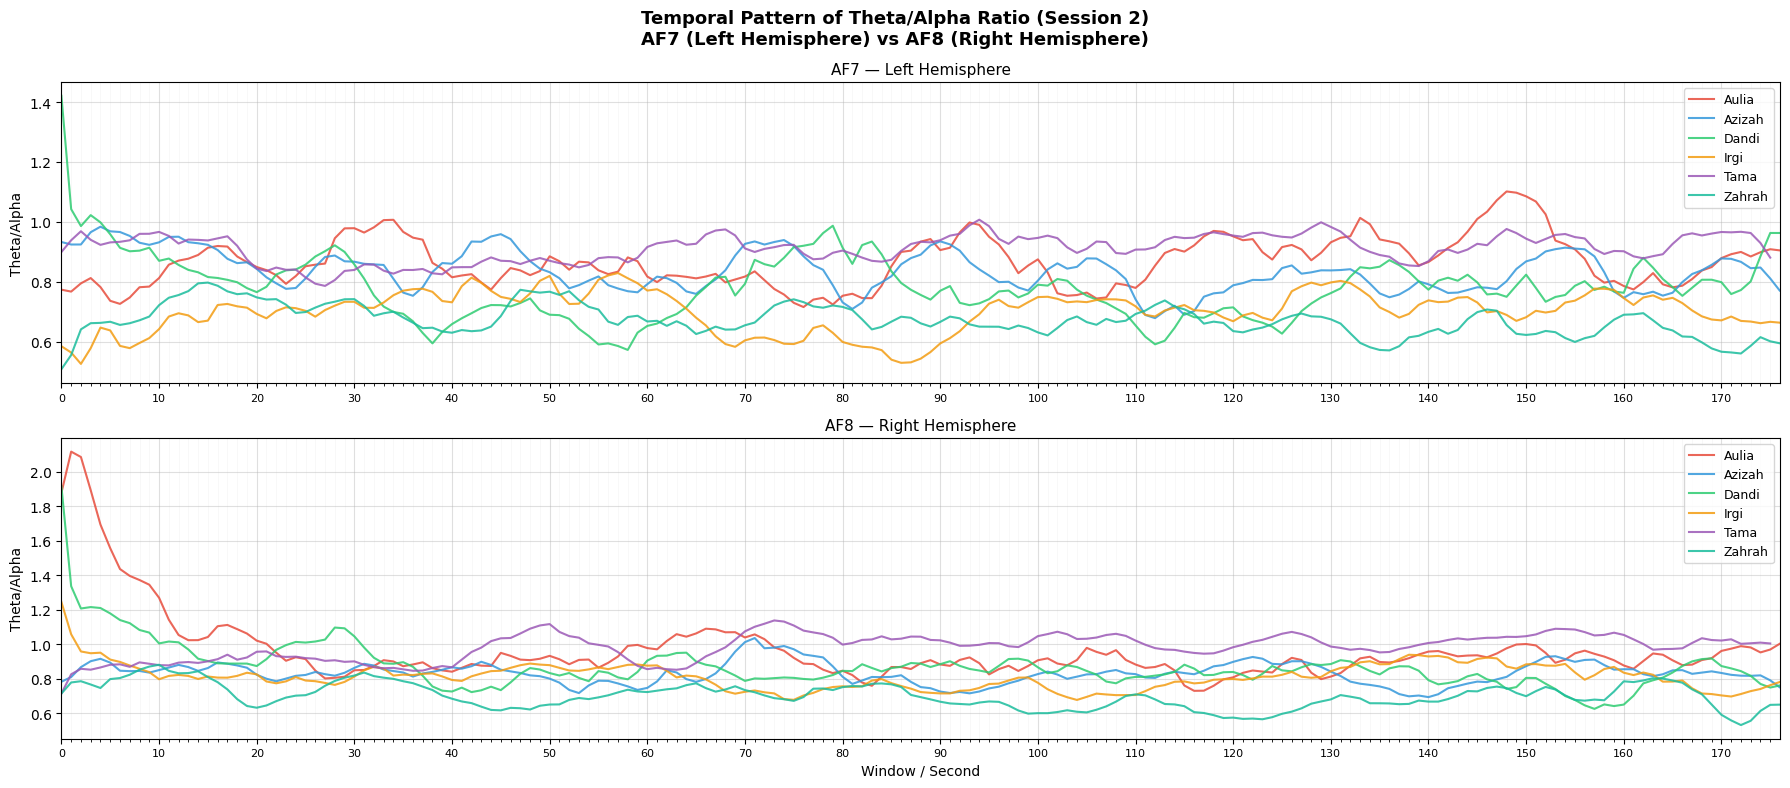


Analisis selesai.
Pipeline: Load → Preprocessing → Sliding Window → Theta/Alpha (Cognitive Load Index)

Interpretasi:
  Nilai tinggi = cognitive load tinggi, attention aktif
  Nilai rendah = otak santai, kurang fokus
  Asimetri AF7 vs AF8 = perbedaan aktivasi hemisfer kiri dan kanan


In [ ]:
# ============================================================
# CELL 10 - Perbandingan Semua Subjek dalam 1 Plot
# Cognitive Load Index tiap subjek ditampilkan bersama
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(18, 8))
fig.suptitle('Temporal Pattern of Theta/Alpha Ratio (Session 2)\n'
             'AF7 (Left Hemisphere) vs AF8 (Right Hemisphere)',
             fontsize=13, fontweight='bold')

for nama, df in data_rasio.items():

    s_af7 = df['theta_alpha_AF7'].rolling(window=10, min_periods=1).mean()
    s_af8 = df['theta_alpha_AF8'].rolling(window=10, min_periods=1).mean()

    axes[0].plot(df['window'], s_af7,
                 color=WARNA[nama], linewidth=1.5,
                 label=nama, alpha=0.85)
    axes[1].plot(df['window'], s_af8,
                 color=WARNA[nama], linewidth=1.5,
                 label=nama, alpha=0.85)

# Ambil panjang data terpendek untuk batas grid
max_window = min(len(df) for df in data_rasio.values())

for ax, title in zip(axes, ['AF7 — Left Hemisphere', 'AF8 — Right Hemisphere']):
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Theta/Alpha')
    ax.legend(fontsize=9, loc='upper right')

    # Grid minor per 1 detik
    ax.set_xticks(range(0, max_window, 1), minor=True)
    # Grid major per 10 detik
    ax.set_xticks(range(0, max_window, 10), minor=False)
    ax.set_xticklabels([str(x) for x in range(0, max_window, 10)], fontsize=8)

    ax.grid(True, which='major', alpha=0.4, linewidth=0.8)
    ax.grid(True, which='minor', alpha=0.15, linewidth=0.4)

    ax.set_xlim(0, max_window)

axes[1].set_xlabel('Window / Second', fontsize=10)

plt.tight_layout()
plt.show()

print('\nAnalisis selesai.')
print('Pipeline: Load → Preprocessing → Sliding Window → Theta/Alpha (Cognitive Load Index)')
print('\nInterpretasi:')
print('  Nilai tinggi = cognitive load tinggi, attention aktif')
print('  Nilai rendah = otak santai, kurang fokus')
print('  Asimetri AF7 vs AF8 = perbedaan aktivasi hemisfer kiri dan kanan')

# **Analisis Pila Temporal Bersama**

In [ ]:
# ============================================================
# CELL 11 - Pola Temporal Bersama: Mean Semua Subjek
# Hitung rata-rata Theta/Alpha seluruh subjek per window
# untuk melihat momen di mana semua subjek bergerak bersama
# ============================================================

import pandas as pd
import numpy as np

# Ambil window terpendek sebagai batas (subjek beda panjang data)
min_window = min(len(df) for df in data_rasio.values())

# Buat dataframe gabungan per window
df_all_af7 = pd.DataFrame({
    nama: df['theta_alpha_AF7'].values[:min_window]
    for nama, df in data_rasio.items()
})
df_all_af8 = pd.DataFrame({
    nama: df['theta_alpha_AF8'].values[:min_window]
    for nama, df in data_rasio.items()
})

df_all_af7['mean']   = df_all_af7.mean(axis=1)
df_all_af7['std']    = df_all_af7.std(axis=1)
df_all_af8['mean']   = df_all_af8.mean(axis=1)
df_all_af8['std']    = df_all_af8.std(axis=1)
df_all_af7['window'] = range(min_window)
df_all_af8['window'] = range(min_window)

print(f'Jumlah window yang dibandingkan: {min_window}')
print('Dataframe temporal bersama berhasil dibuat')

Jumlah window yang dibandingkan: 176
Dataframe temporal bersama berhasil dibuat


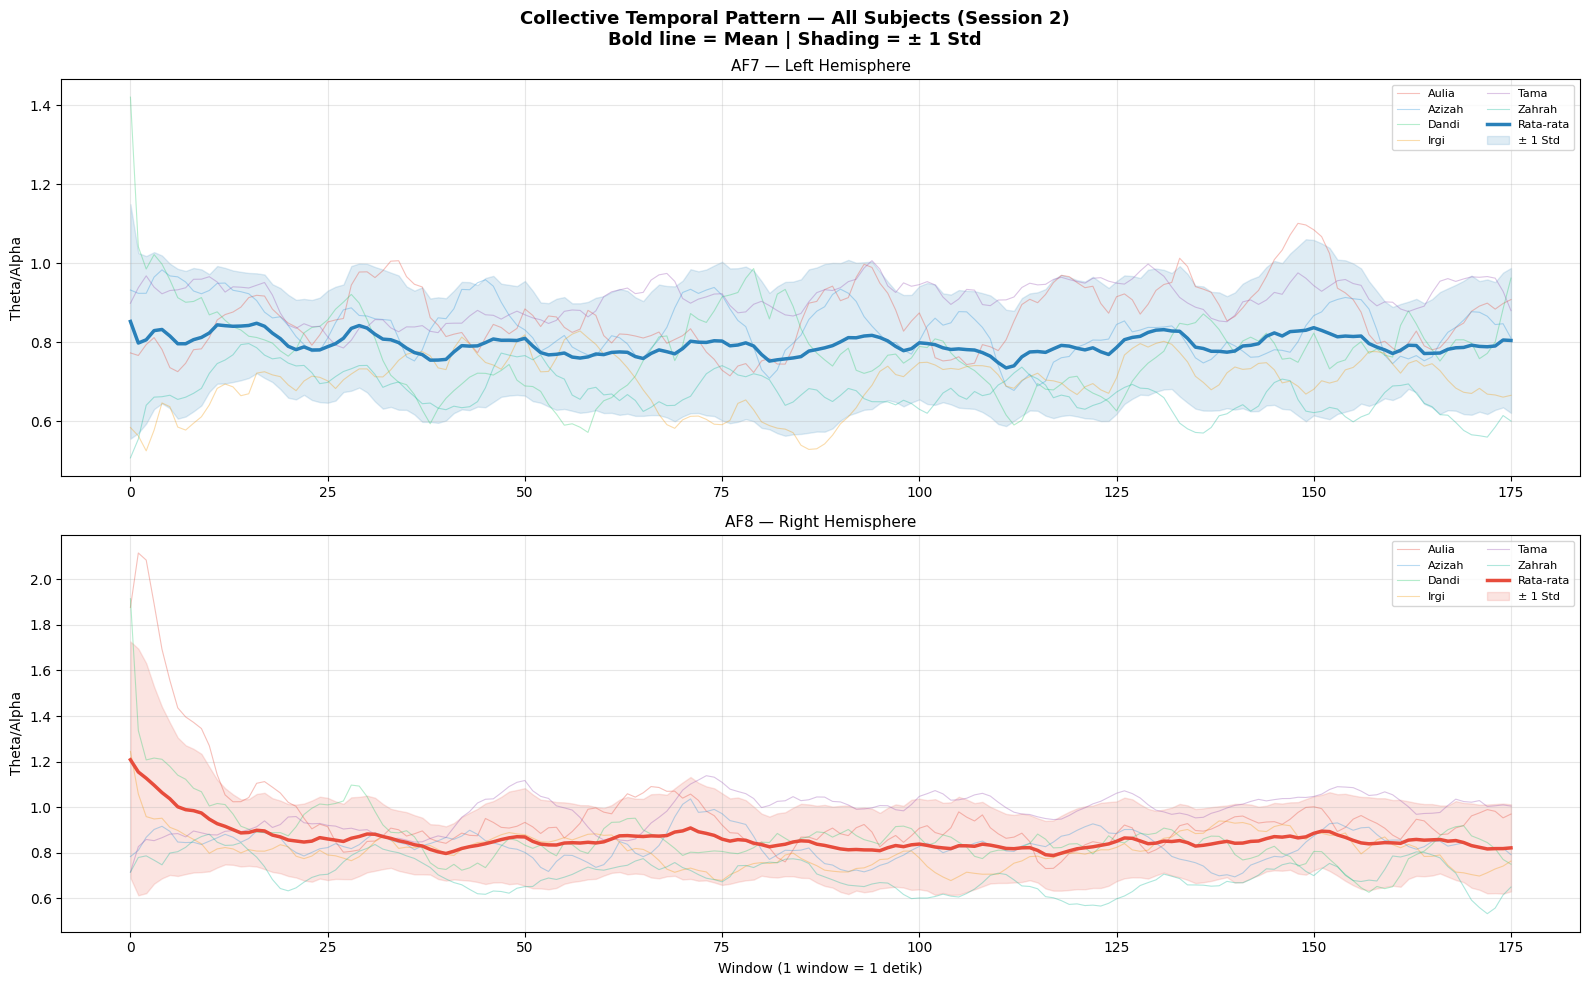

In [ ]:
# ============================================================
# CELL 11b - Visualisasi Pola Temporal Bersama
# Garis tebal = rata-rata semua subjek
# Shading = ± 1 std (area kesepakatan antar subjek)
# ============================================================

import os

SAVE_DIR = '/content/drive/MyDrive/TK AI/EEG/Sesi 2/Output_Figures'
os.makedirs(SAVE_DIR, exist_ok=True)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle('Collective Temporal Pattern — All Subjects (Session 2)\n'
             'Bold line = Mean | Shading = ± 1 Std',
             fontsize=13, fontweight='bold')

for ax, df_all, sensor, warna_mean in zip(
    axes,
    [df_all_af7, df_all_af8],
    ['AF7 — Left Hemisphere', 'AF8 — Right Hemisphere'],
    ['#2980b9', '#e74c3c']
):
    w = df_all['window']

    # Plot tiap subjek (tipis, transparan)
    for nama in SUBJEK:
        smooth = df_all[nama].rolling(window=10, min_periods=1).mean()
        ax.plot(w, smooth, color=WARNA[nama], linewidth=0.8,
                alpha=0.35, label=nama)

    # Plot mean ± std
    mean_smooth = df_all['mean'].rolling(window=10, min_periods=1).mean()
    std_smooth  = df_all['std'].rolling(window=10, min_periods=1).mean()

    ax.plot(w, mean_smooth, color=warna_mean, linewidth=2.5,
            label='Rata-rata', zorder=5)
    ax.fill_between(w,
                    mean_smooth - std_smooth,
                    mean_smooth + std_smooth,
                    alpha=0.15, color=warna_mean, label='± 1 Std')

    ax.set_title(sensor, fontsize=11)
    ax.set_ylabel('Theta/Alpha')
    ax.legend(fontsize=8, loc='upper right', ncol=2)
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel('Window (1 window = 1 detik)')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/Fig3_Collective_Pattern.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CELL 11c - Deteksi Momen Konvergensi
# Momen di mana std antar subjek rendah = semua bergerak bersama
# Momen di mana std tinggi = pola subjek divergen
# ============================================================

THRESHOLD_KONVERGEN = 0.15  # Std rendah = subjek seragam

print('=== MOMEN KONVERGENSI ANTAR SUBJEK ===')
print(f'Threshold std: < {THRESHOLD_KONVERGEN} (semua subjek bergerak seragam)\n')

for sensor, df_all, label in [
    ('AF7', df_all_af7, 'Hemisfer Kiri'),
    ('AF8', df_all_af8, 'Hemisfer Kanan')
]:
    std_smooth = df_all['std'].rolling(window=10, min_periods=1).mean()
    konvergen  = df_all['window'][std_smooth < THRESHOLD_KONVERGEN]

    print(f'{sensor} ({label}):')
    print(f'  Jumlah window konvergen : {len(konvergen)} dari {min_window} window')
    print(f'  Persentase              : {len(konvergen)/min_window*100:.1f}%')
    print(f'  Std rata-rata keseluruhan: {df_all["std"].mean():.4f}')
    print()

=== MOMEN KONVERGENSI ANTAR SUBJEK ===
Threshold std: < 0.15 (semua subjek bergerak seragam)

AF7 (Hemisfer Kiri):
  Jumlah window konvergen : 61 dari 176 window
  Persentase              : 34.7%
  Std rata-rata keseluruhan: 0.1627

AF8 (Hemisfer Kanan):
  Jumlah window konvergen : 32 dari 176 window
  Persentase              : 18.2%
  Std rata-rata keseluruhan: 0.1760



# **Klasifikasi Attention Level**

In [ ]:
# ============================================================
# CELL 12 - Klasifikasi Attention Level per Subjek
# Threshold berbasis persentil distribusi tiap subjek sendiri
# (per-subject percentile threshold)
#
# Tinggi  : Theta/Alpha > persentil ke-75
# Sedang  : persentil ke-25 <= Theta/Alpha <= persentil ke-75
# Rendah  : Theta/Alpha < persentil ke-25
#
# Referensi: Xu et al. (2023), Int. J. Environ. Res. Public Health
# ============================================================

data_level = {}

semua_af7 = pd.concat([df['theta_alpha_AF7'] for df in data_rasio.values()])
semua_af8 = pd.concat([df['theta_alpha_AF8'] for df in data_rasio.values()])

THRESHOLD = {
    'AF7': {'p25': semua_af7.quantile(0.25), 'p75': semua_af7.quantile(0.75)},
    'AF8': {'p25': semua_af8.quantile(0.25), 'p75': semua_af8.quantile(0.75)},
}

print('Threshold global:')
for sensor, val in THRESHOLD.items():
    print(f'  {sensor} — P25: {val["p25"]:.4f} | P75: {val["p75"]:.4f}')
print()

for nama, df in data_rasio.items():

    df_level = df.copy()

    for sensor in ['AF7', 'AF8']:
        kolom = f'theta_alpha_{sensor}'
        kolom_level = f'level_{sensor}'

        p25 = THRESHOLD[sensor]['p25']
        p75 = THRESHOLD[sensor]['p75']

        df_level[kolom_level] = pd.cut(
            df_level[kolom],
            bins=[-np.inf, p25, p75, np.inf],
            labels=['Rendah', 'Sedang', 'Tinggi']
        )

    data_level[nama] = df_level

print('Klasifikasi attention level selesai')
print('Threshold berbasis persentil ke-25 dan ke-75 per subjek\n')

# Preview threshold tiap subjek
print(f'{"Subjek":<10} {"AF7 P25":>10} {"AF7 P75":>10} {"AF8 P25":>10} {"AF8 P75":>10}')
print('-' * 52)
for nama, df in data_level.items():
    af7_p25 = data_rasio[nama]['theta_alpha_AF7'].quantile(0.25)
    af7_p75 = data_rasio[nama]['theta_alpha_AF7'].quantile(0.75)
    af8_p25 = data_rasio[nama]['theta_alpha_AF8'].quantile(0.25)
    af8_p75 = data_rasio[nama]['theta_alpha_AF8'].quantile(0.75)
    print(f'{nama:<10} {af7_p25:>10.4f} {af7_p75:>10.4f} {af8_p25:>10.4f} {af8_p75:>10.4f}')

Threshold global:
  AF7 — P25: 0.6609 | P75: 0.9094
  AF8 — P25: 0.7173 | P75: 0.9717

Klasifikasi attention level selesai
Threshold berbasis persentil ke-25 dan ke-75 per subjek

Subjek        AF7 P25    AF7 P75    AF8 P25    AF8 P75
----------------------------------------------------
Aulia          0.7365     0.9812     0.7798     1.0539
Azizah         0.7062     0.9171     0.7295     0.9104
Dandi          0.6251     0.9050     0.7138     0.9817
Irgi           0.6005     0.7899     0.7103     0.8910
Tama           0.8356     0.9799     0.9093     1.0688
Zahrah         0.5888     0.7515     0.6031     0.8014


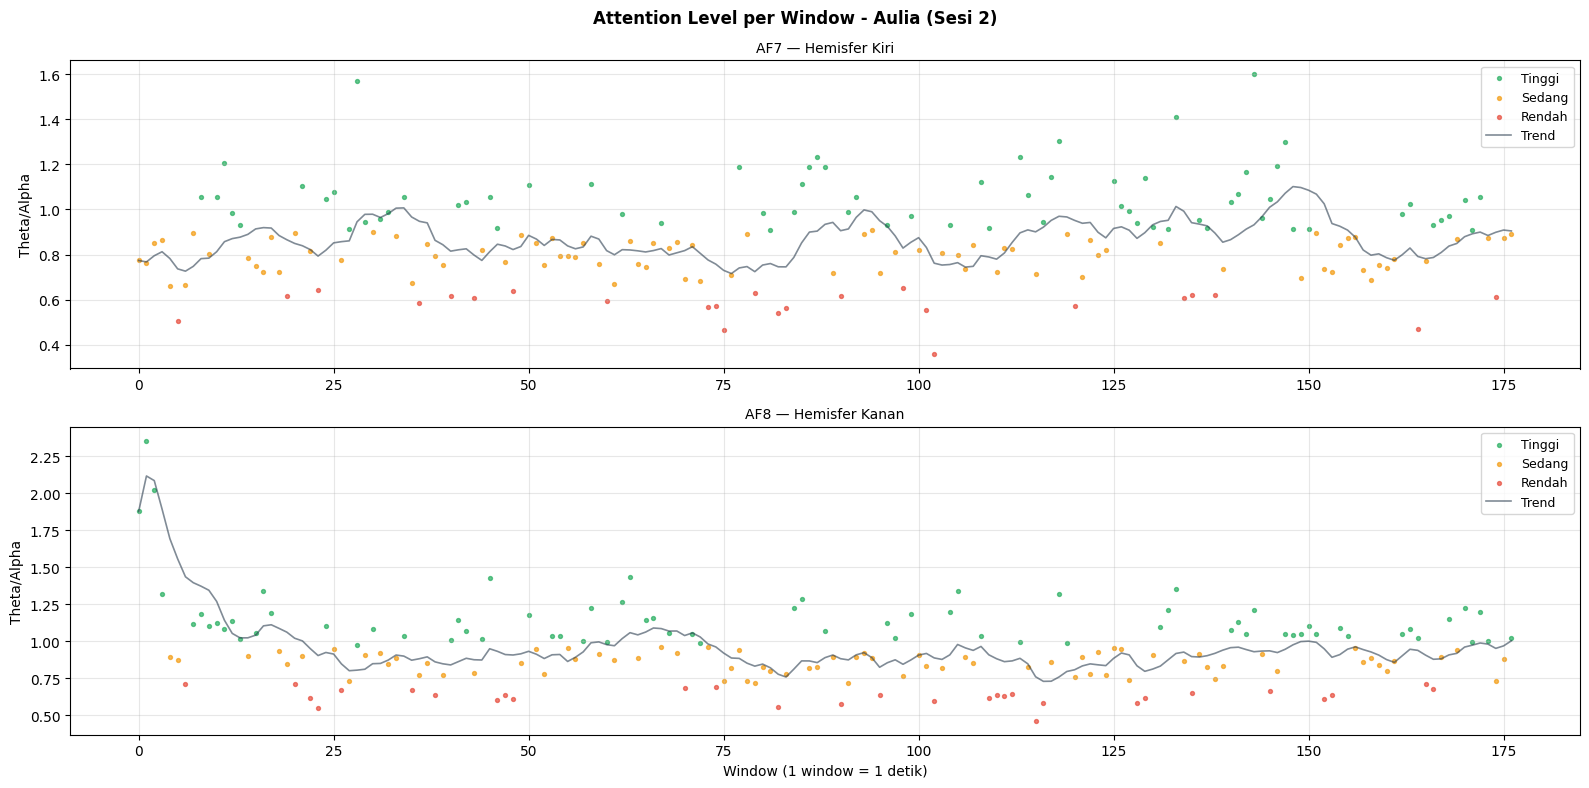

Selesai plot Aulia



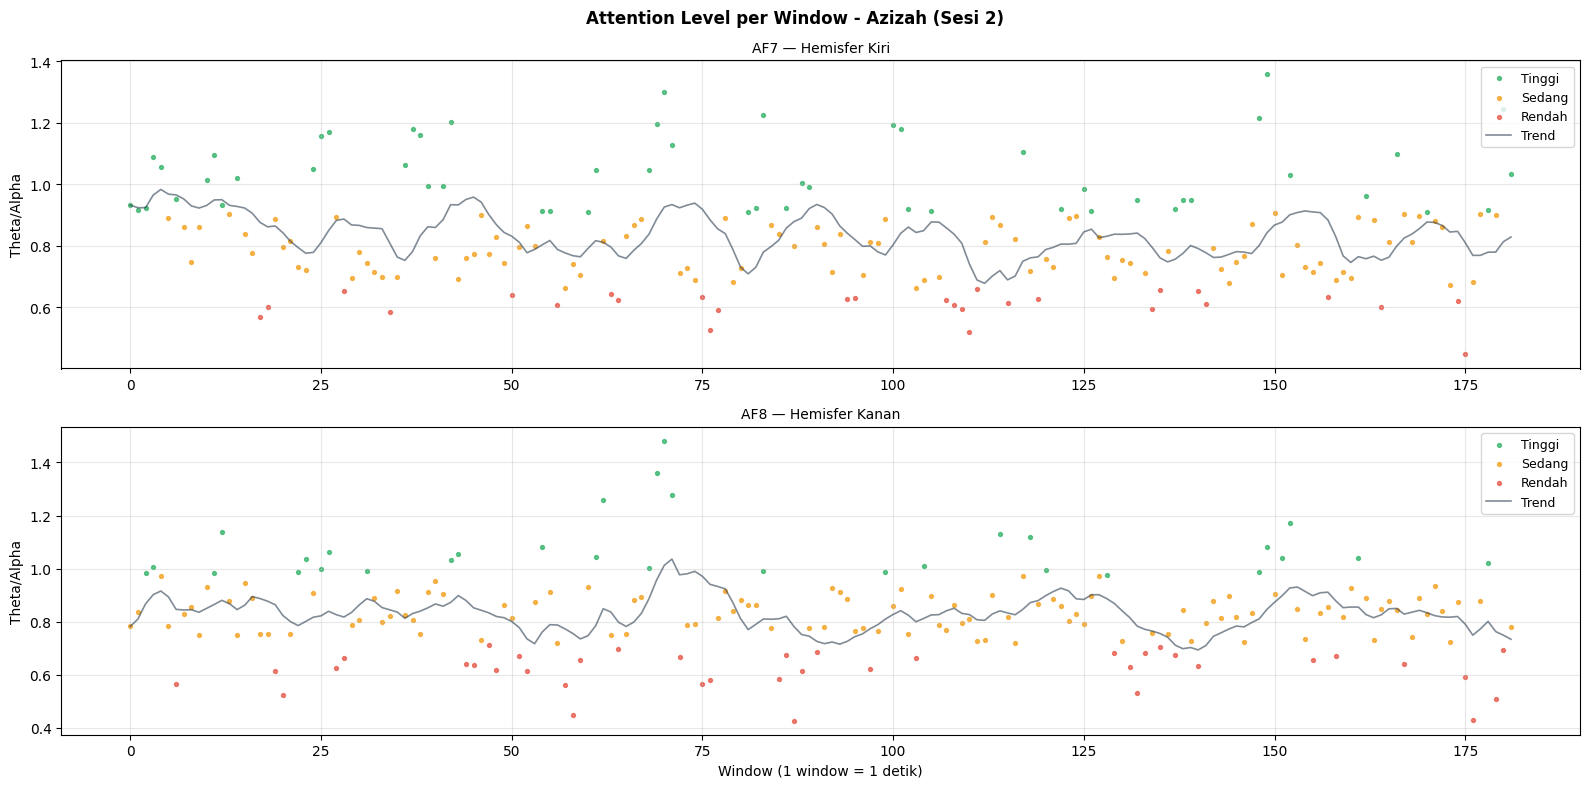

Selesai plot Azizah



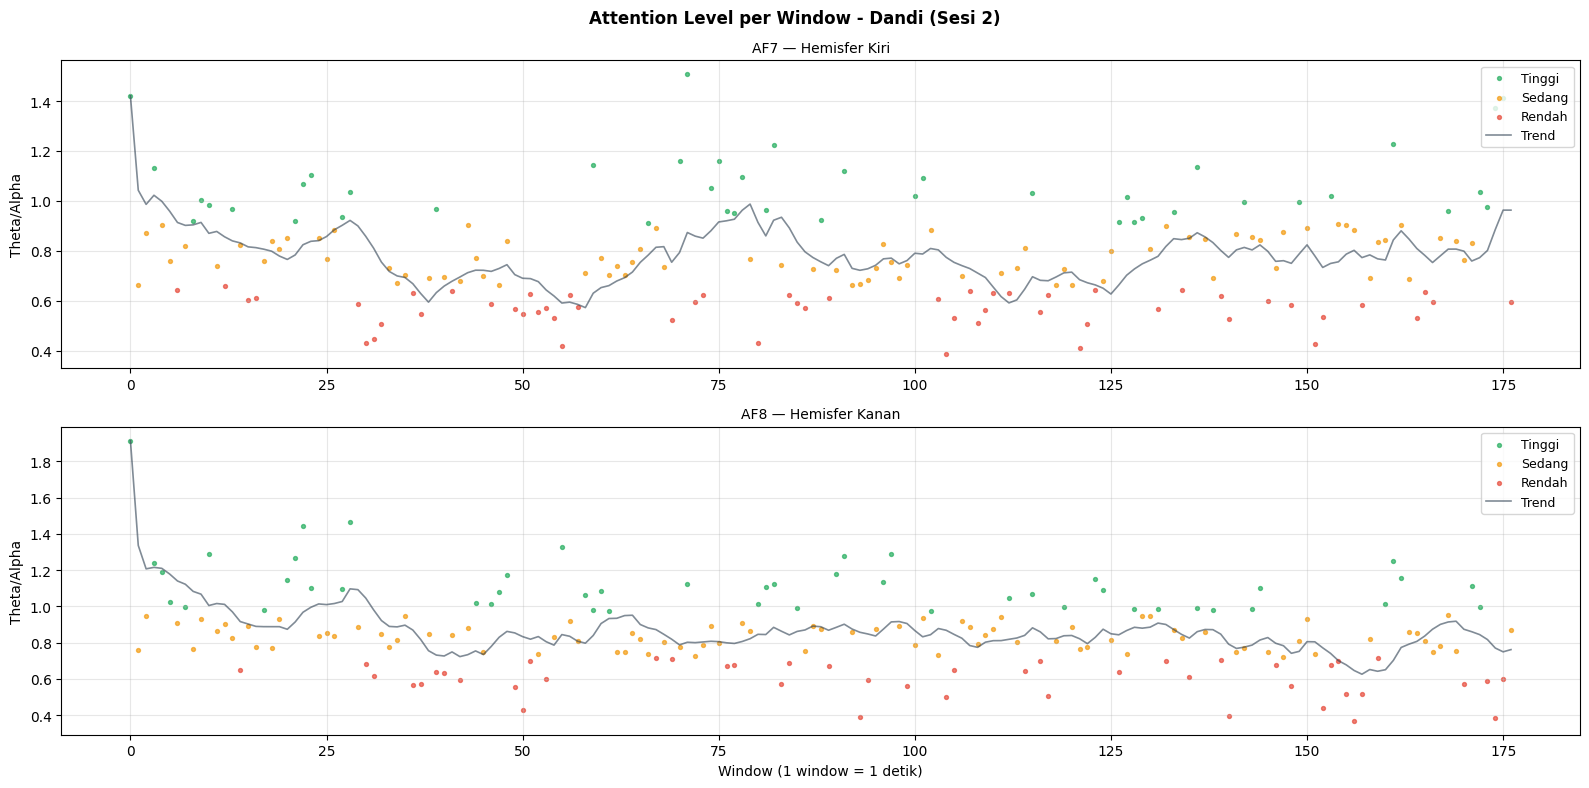

Selesai plot Dandi



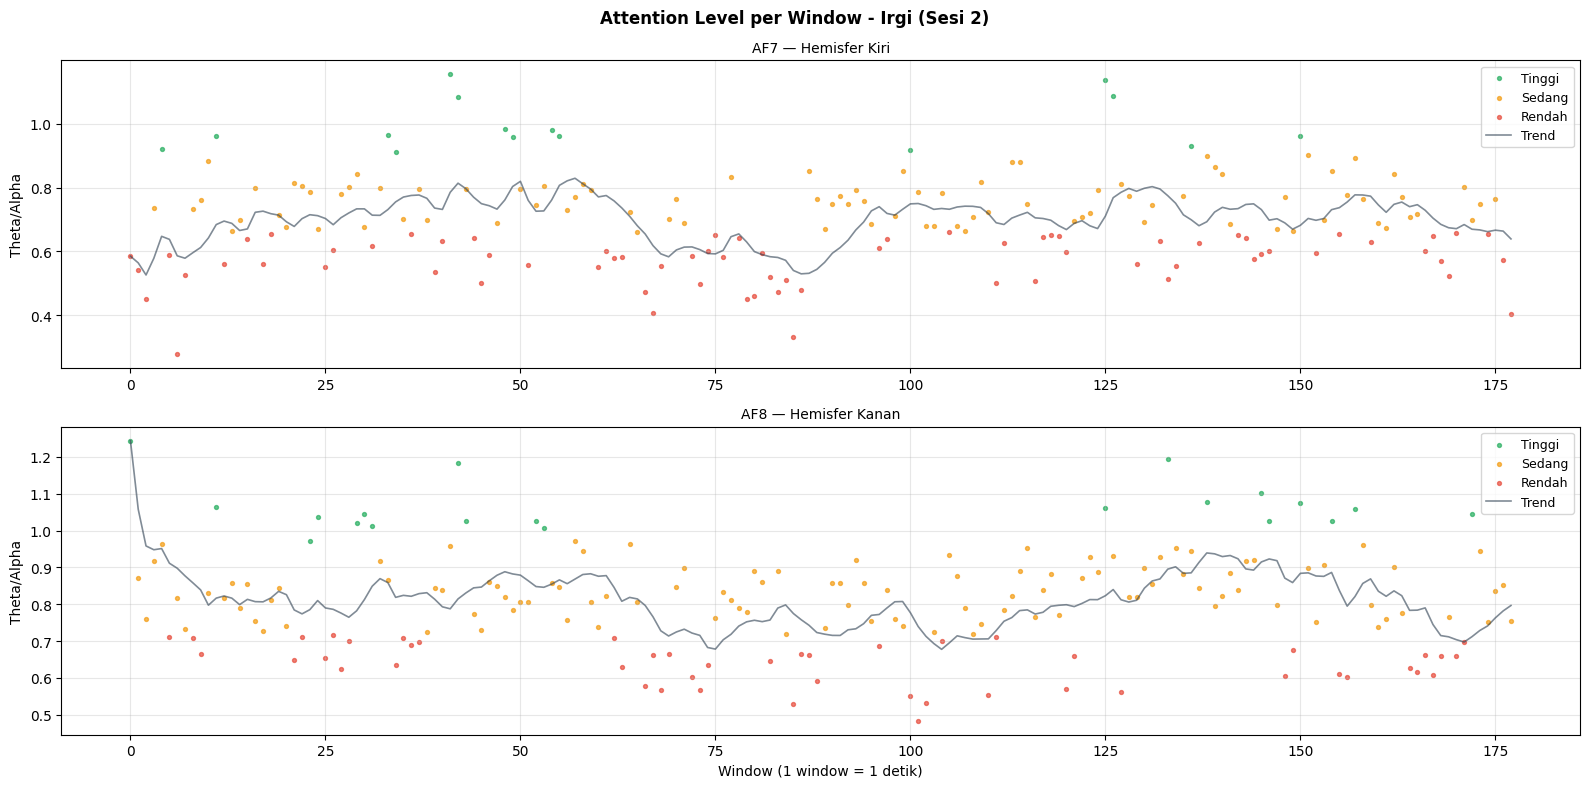

Selesai plot Irgi



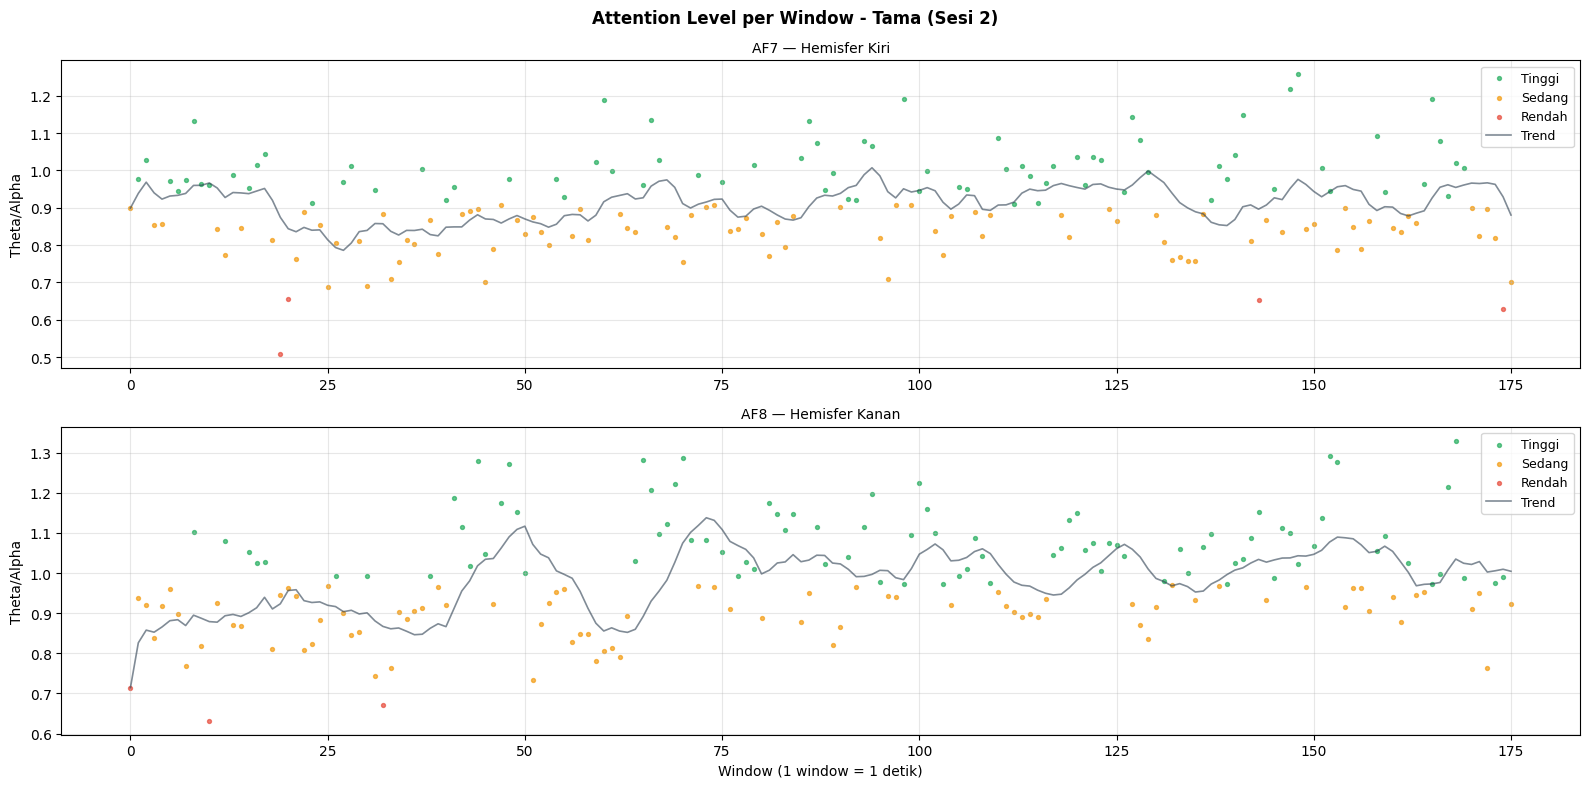

Selesai plot Tama



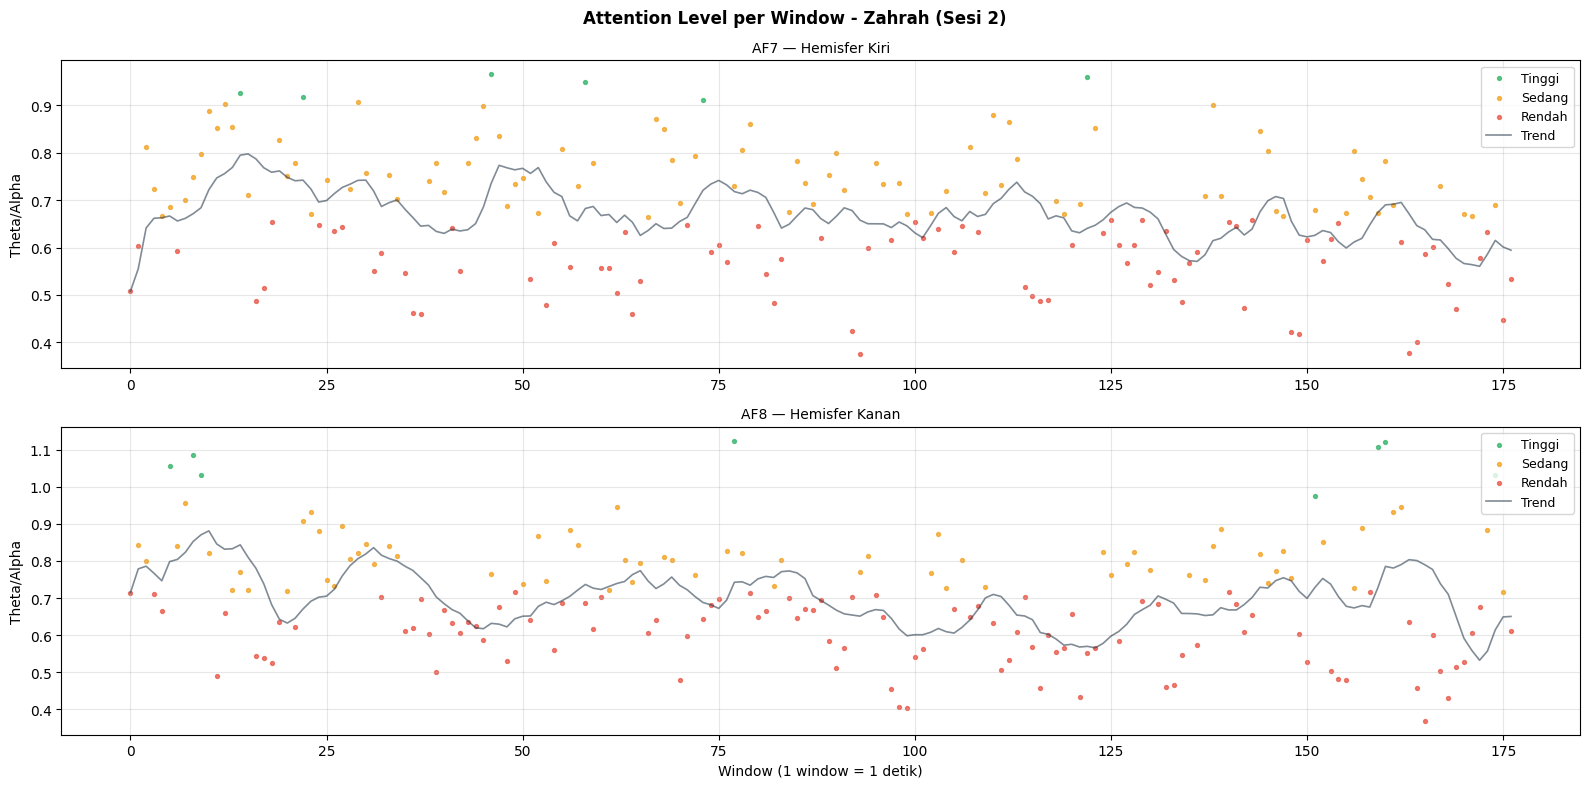

Selesai plot Zahrah



In [ ]:
# ============================================================
# CELL 12b - Visualisasi Time Series dengan Warna per Level
# Hijau = Tinggi | Kuning = Sedang | Merah = Rendah
# ============================================================

WARNA_LEVEL = {
    'Tinggi' : '#27ae60',
    'Sedang' : '#f39c12',
    'Rendah' : '#e74c3c'
}

for nama, df in data_level.items():

    fig, axes = plt.subplots(2, 1, figsize=(16, 8))
    fig.suptitle(f'Attention Level per Window - {nama} (Sesi 2)',
                 fontsize=12, fontweight='bold')

    for ax, sensor, label in zip(
        axes,
        ['AF7', 'AF8'],
        ['AF7 — Hemisfer Kiri', 'AF8 — Hemisfer Kanan']
    ):
        kolom       = f'theta_alpha_{sensor}'
        kolom_level = f'level_{sensor}'

        for level, warna in WARNA_LEVEL.items():
            mask = df[kolom_level] == level
            ax.scatter(df['window'][mask], df[kolom][mask],
                       color=warna, s=8, alpha=0.7, label=level)

        # Overlay garis smooth
        smooth = df[kolom].rolling(window=10, min_periods=1).mean()
        ax.plot(df['window'], smooth, color='#2c3e50',
                linewidth=1.2, alpha=0.6, label='Trend')

        ax.set_title(label, fontsize=10)
        ax.set_ylabel('Theta/Alpha')
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(True, alpha=0.3)

    axes[1].set_xlabel('Window (1 window = 1 detik)')

    plt.tight_layout()
    plt.show()
    print(f'Selesai plot {nama}\n')

In [ ]:
# ============================================================
# CELL 12c - Ringkasan Distribusi Attention Level per Subjek
# Persentase waktu di tiap level untuk AF7 dan AF8
# ============================================================

print('=' * 65)
print('DISTRIBUSI ATTENTION LEVEL PER SUBJEK')
print('Tinggi (>P75) | Sedang (P25-P75) | Rendah (<P25)')
print('=' * 65)

for nama, df in data_level.items():
    print(f'\n{nama}:')
    print(f'  {"Sensor":<8} {"Tinggi":>10} {"Sedang":>10} {"Rendah":>10}')
    print(f'  {"-"*40}')

    for sensor in ['AF7', 'AF8']:
        kolom_level = f'level_{sensor}'
        total       = len(df)
        tinggi = (df[kolom_level] == 'Tinggi').sum() / total * 100
        sedang = (df[kolom_level] == 'Sedang').sum() / total * 100
        rendah = (df[kolom_level] == 'Rendah').sum() / total * 100
        print(f'  {sensor:<8} {tinggi:>9.1f}% {sedang:>9.1f}% {rendah:>9.1f}%')

DISTRIBUSI ATTENTION LEVEL PER SUBJEK
Tinggi (>P75) | Sedang (P25-P75) | Rendah (<P25)

Aulia:
  Sensor       Tinggi     Sedang     Rendah
  ----------------------------------------
  AF7           39.5%      46.9%      13.6%
  AF8           40.1%      42.9%      16.9%

Azizah:
  Sensor       Tinggi     Sedang     Rendah
  ----------------------------------------
  AF7           29.7%      54.9%      15.4%
  AF8           17.0%      61.5%      21.4%

Dandi:
  Sensor       Tinggi     Sedang     Rendah
  ----------------------------------------
  AF7           24.3%      44.6%      31.1%
  AF8           27.1%      47.5%      25.4%

Irgi:
  Sensor       Tinggi     Sedang     Rendah
  ----------------------------------------
  AF7            8.4%      51.1%      40.4%
  AF8           11.2%      61.8%      27.0%

Tama:
  Sensor       Tinggi     Sedang     Rendah
  ----------------------------------------
  AF7           44.9%      52.8%       2.3%
  AF8           50.6%      47.7%       1.7%

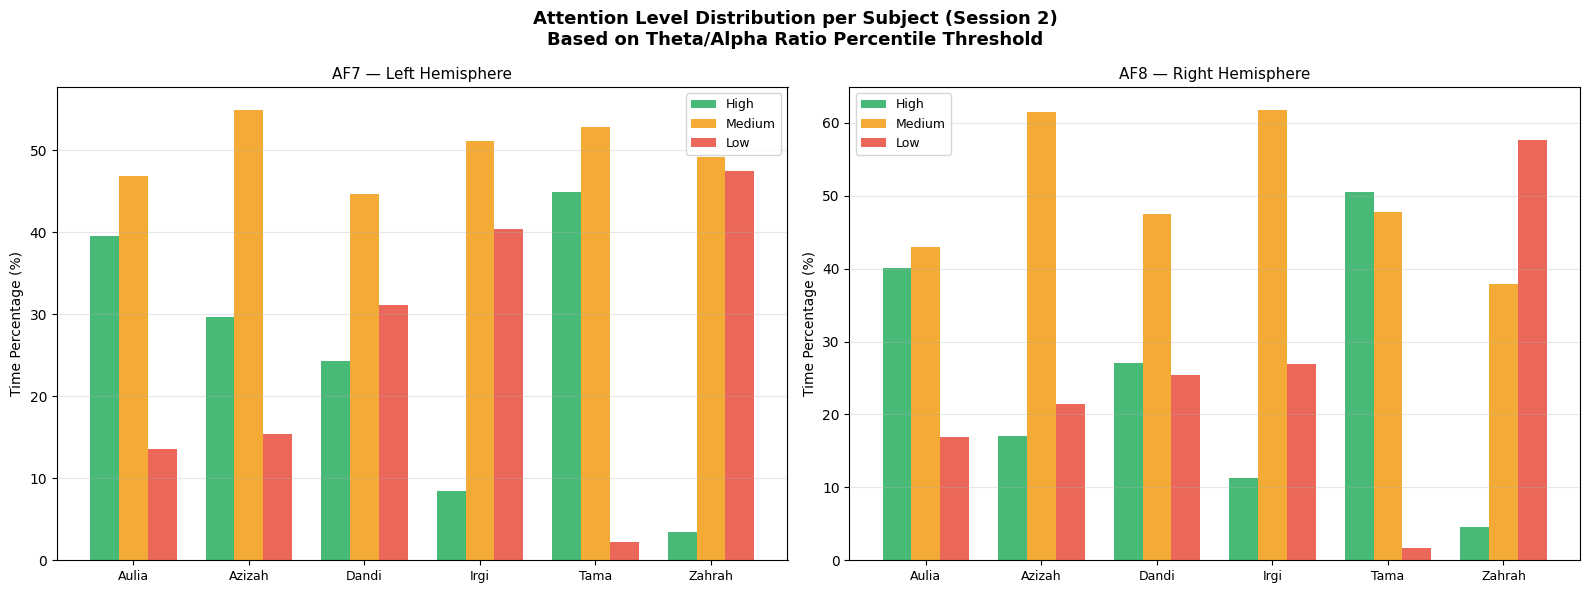

In [ ]:
# ============================================================
# CELL 12d - Bar Chart Distribusi Level Semua Subjek
# Perbandingan visual proporsi attention tiap subjek
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Attention Level Distribution per Subject (Session 2)\n'
             'Based on Theta/Alpha Ratio Percentile Threshold',
             fontsize=13, fontweight='bold')

for ax, sensor, label in zip(
    axes,
    ['AF7', 'AF8'],
    ['AF7 — Left Hemisphere', 'AF8 — Right Hemisphere'],
):
    tinggi_list = []
    sedang_list = []
    rendah_list = []

    for nama, df in data_level.items():
        kolom_level = f'level_{sensor}'
        total       = len(df)
        tinggi_list.append((df[kolom_level] == 'Tinggi').sum() / total * 100)
        sedang_list.append((df[kolom_level] == 'Sedang').sum() / total * 100)
        rendah_list.append((df[kolom_level] == 'Rendah').sum() / total * 100)

    x = np.arange(len(SUBJEK))
    w = 0.25

    ax.bar(x - w, tinggi_list, w, label='High',   color='#27ae60', alpha=0.85)
    ax.bar(x,     sedang_list, w, label='Medium', color='#f39c12', alpha=0.85)
    ax.bar(x + w, rendah_list, w, label='Low',    color='#e74c3c', alpha=0.85)

    ax.set_title(label, fontsize=11)
    ax.set_ylabel('Time Percentage (%)', fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(SUBJEK, fontsize=9)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# Cek distribusi std dan temukan momen penting
print('=== STATISTIK STD ANTAR SUBJEK ===')
for sensor, df_all, label in [
    ('AF7', df_all_af7, 'Hemisfer Kiri'),
    ('AF8', df_all_af8, 'Hemisfer Kanan')
]:
    std_smooth = df_all['std'].rolling(window=10, min_periods=1).mean()
    mean_smooth = df_all['mean'].rolling(window=10, min_periods=1).mean()

    print(f'\n{sensor} ({label}):')
    print(f'  Std min: {std_smooth.min():.4f} | max: {std_smooth.max():.4f} | mean: {std_smooth.mean():.4f}')
    print(f'  Mean min: {mean_smooth.min():.4f} | max: {mean_smooth.max():.4f}')

    # Top 5 window konvergen (std terendah)
    top_konvergen = df_all['window'][std_smooth.nsmallest(5).index].values
    print(f'  Top 5 window paling konvergen: {sorted(top_konvergen)}')

    # Top 5 window divergen (std tertinggi)
    top_divergen = df_all['window'][std_smooth.nlargest(5).index].values
    print(f'  Top 5 window paling divergen : {sorted(top_divergen)}')

    # Top 5 puncak mean tertinggi
    top_tinggi = df_all['window'][mean_smooth.nlargest(5).index].values
    print(f'  Top 5 window mean tertinggi  : {sorted(top_tinggi)}')

    # Top 5 lembah mean terendah
    top_rendah = df_all['window'][mean_smooth.nsmallest(5).index].values
    print(f'  Top 5 window mean terendah   : {sorted(top_rendah)}')

=== STATISTIK STD ANTAR SUBJEK ===

AF7 (Hemisfer Kiri):
  Std min: 0.1103 | max: 0.2968 | mean: 0.1633
  Mean min: 0.7355 | max: 0.8531
  Top 5 window paling konvergen: [np.int64(22), np.int64(160), np.int64(161), np.int64(162), np.int64(163)]
  Top 5 window paling divergen : [np.int64(0), np.int64(1), np.int64(149), np.int64(150), np.int64(151)]
  Top 5 window mean tertinggi  : [np.int64(0), np.int64(11), np.int64(15), np.int64(16), np.int64(29)]
  Top 5 window mean terendah   : [np.int64(38), np.int64(81), np.int64(110), np.int64(111), np.int64(112)]

AF8 (Hemisfer Kanan):
  Std min: 0.1107 | max: 0.5415 | mean: 0.1828
  Mean min: 0.7873 | max: 1.2080
  Top 5 window paling konvergen: [np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41)]
  Top 5 window paling divergen : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  Top 5 window mean tertinggi  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  Top 5 window mean terendah   : [n

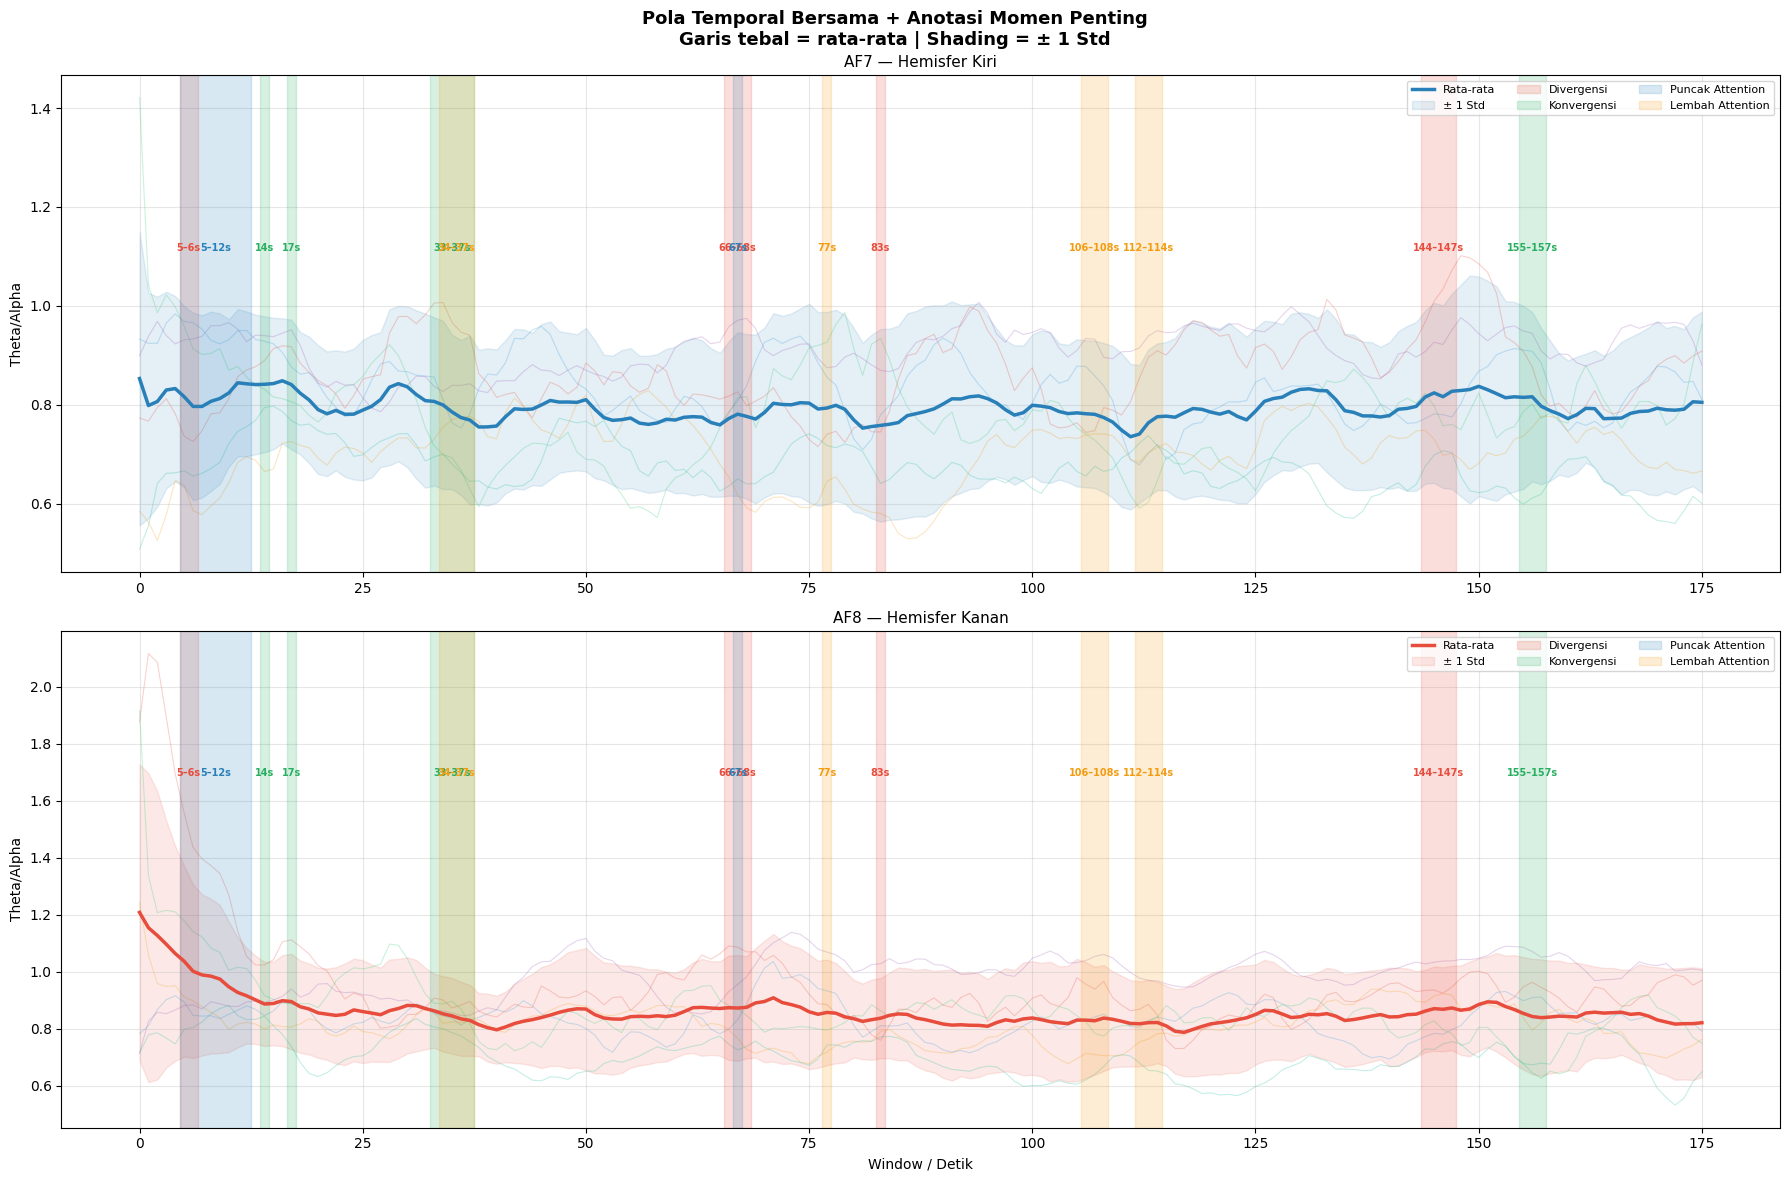

In [ ]:
# ============================================================
# CELL 11b2 - Visualisasi Pola Temporal dengan Anotasi Momen Penting
# ============================================================

MOMEN = {
    'divergen': {
        'windows': [5, 6, 66, 67, 68, 83, 144, 145, 146, 147],
        'warna'  : '#e74c3c',
        'label'  : 'Divergensi'
    },
    'konvergen': {
        'windows': [14, 17, 33, 34, 35, 36, 37, 155, 156, 157],
        'warna'  : '#27ae60',
        'label'  : 'Konvergensi'
    },
    'puncak': {
        'windows': [5, 6, 7, 8, 9, 11, 12, 67],
        'warna'  : '#2980b9',
        'label'  : 'Puncak Attention'
    },
    'lembah': {
        'windows': [34, 35, 36, 37, 77, 106, 107, 108, 112, 113, 114],
        'warna'  : '#f39c12',
        'label'  : 'Lembah Attention'
    },
}

fig, axes = plt.subplots(2, 1, figsize=(18, 12))
fig.suptitle('Pola Temporal Bersama + Anotasi Momen Penting\n'
             'Garis tebal = rata-rata | Shading = ± 1 Std',
             fontsize=13, fontweight='bold')

for ax, df_all, sensor, warna_mean in zip(
    axes,
    [df_all_af7, df_all_af8],
    ['AF7 — Hemisfer Kiri', 'AF8 — Hemisfer Kanan'],
    ['#2980b9', '#e74c3c']
):
    w = df_all['window']
    mean_smooth = df_all['mean'].rolling(window=10, min_periods=1).mean()
    std_smooth  = df_all['std'].rolling(window=10, min_periods=1).mean()

    # Plot tiap subjek (tipis, transparan)
    for nama in SUBJEK:
        smooth = df_all[nama].rolling(window=10, min_periods=1).mean()
        ax.plot(w, smooth, color=WARNA[nama], linewidth=0.8, alpha=0.25)

    # Plot mean ± std
    ax.plot(w, mean_smooth, color=warna_mean, linewidth=2.5,
            label='Rata-rata', zorder=5)
    ax.fill_between(w,
                    mean_smooth - std_smooth,
                    mean_smooth + std_smooth,
                    alpha=0.12, color=warna_mean, label='± 1 Std')

    # Tandai momen penting
    y_min = ax.get_ylim()[0] if ax.get_ylim()[0] != 0 else mean_smooth.min() - std_smooth.max()
    y_max = mean_smooth.max() + std_smooth.max()

    label_sudah = set()
    for tipe, info in MOMEN.items():
        # Kelompokkan window yang berurutan jadi satu blok
        windows = sorted(info['windows'])
        blok = []
        start = windows[0]
        end   = windows[0]
        for i in range(1, len(windows)):
            if windows[i] <= end + 2:
                end = windows[i]
            else:
                blok.append((start, end))
                start = windows[i]
                end   = windows[i]
        blok.append((start, end))

        for (s, e) in blok:
            label_text = info['label'] if info['label'] not in label_sudah else None
            ax.axvspan(s - 0.5, e + 0.5,
                       alpha=0.18, color=info['warna'],
                       label=label_text, zorder=2)
            if label_text:
                label_sudah.add(info['label'])

            # Tambah label teks di atas shading
            ax.text((s + e) / 2, y_max * 0.98,
                    f'{s}–{e}s' if s != e else f'{s}s',
                    ha='center', va='top', fontsize=7,
                    color=info['warna'], fontweight='bold')

    ax.set_title(sensor, fontsize=11)
    ax.set_ylabel('Theta/Alpha')
    ax.legend(fontsize=8, loc='upper right', ncol=3)
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel('Window / Detik')

plt.tight_layout()
plt.show()

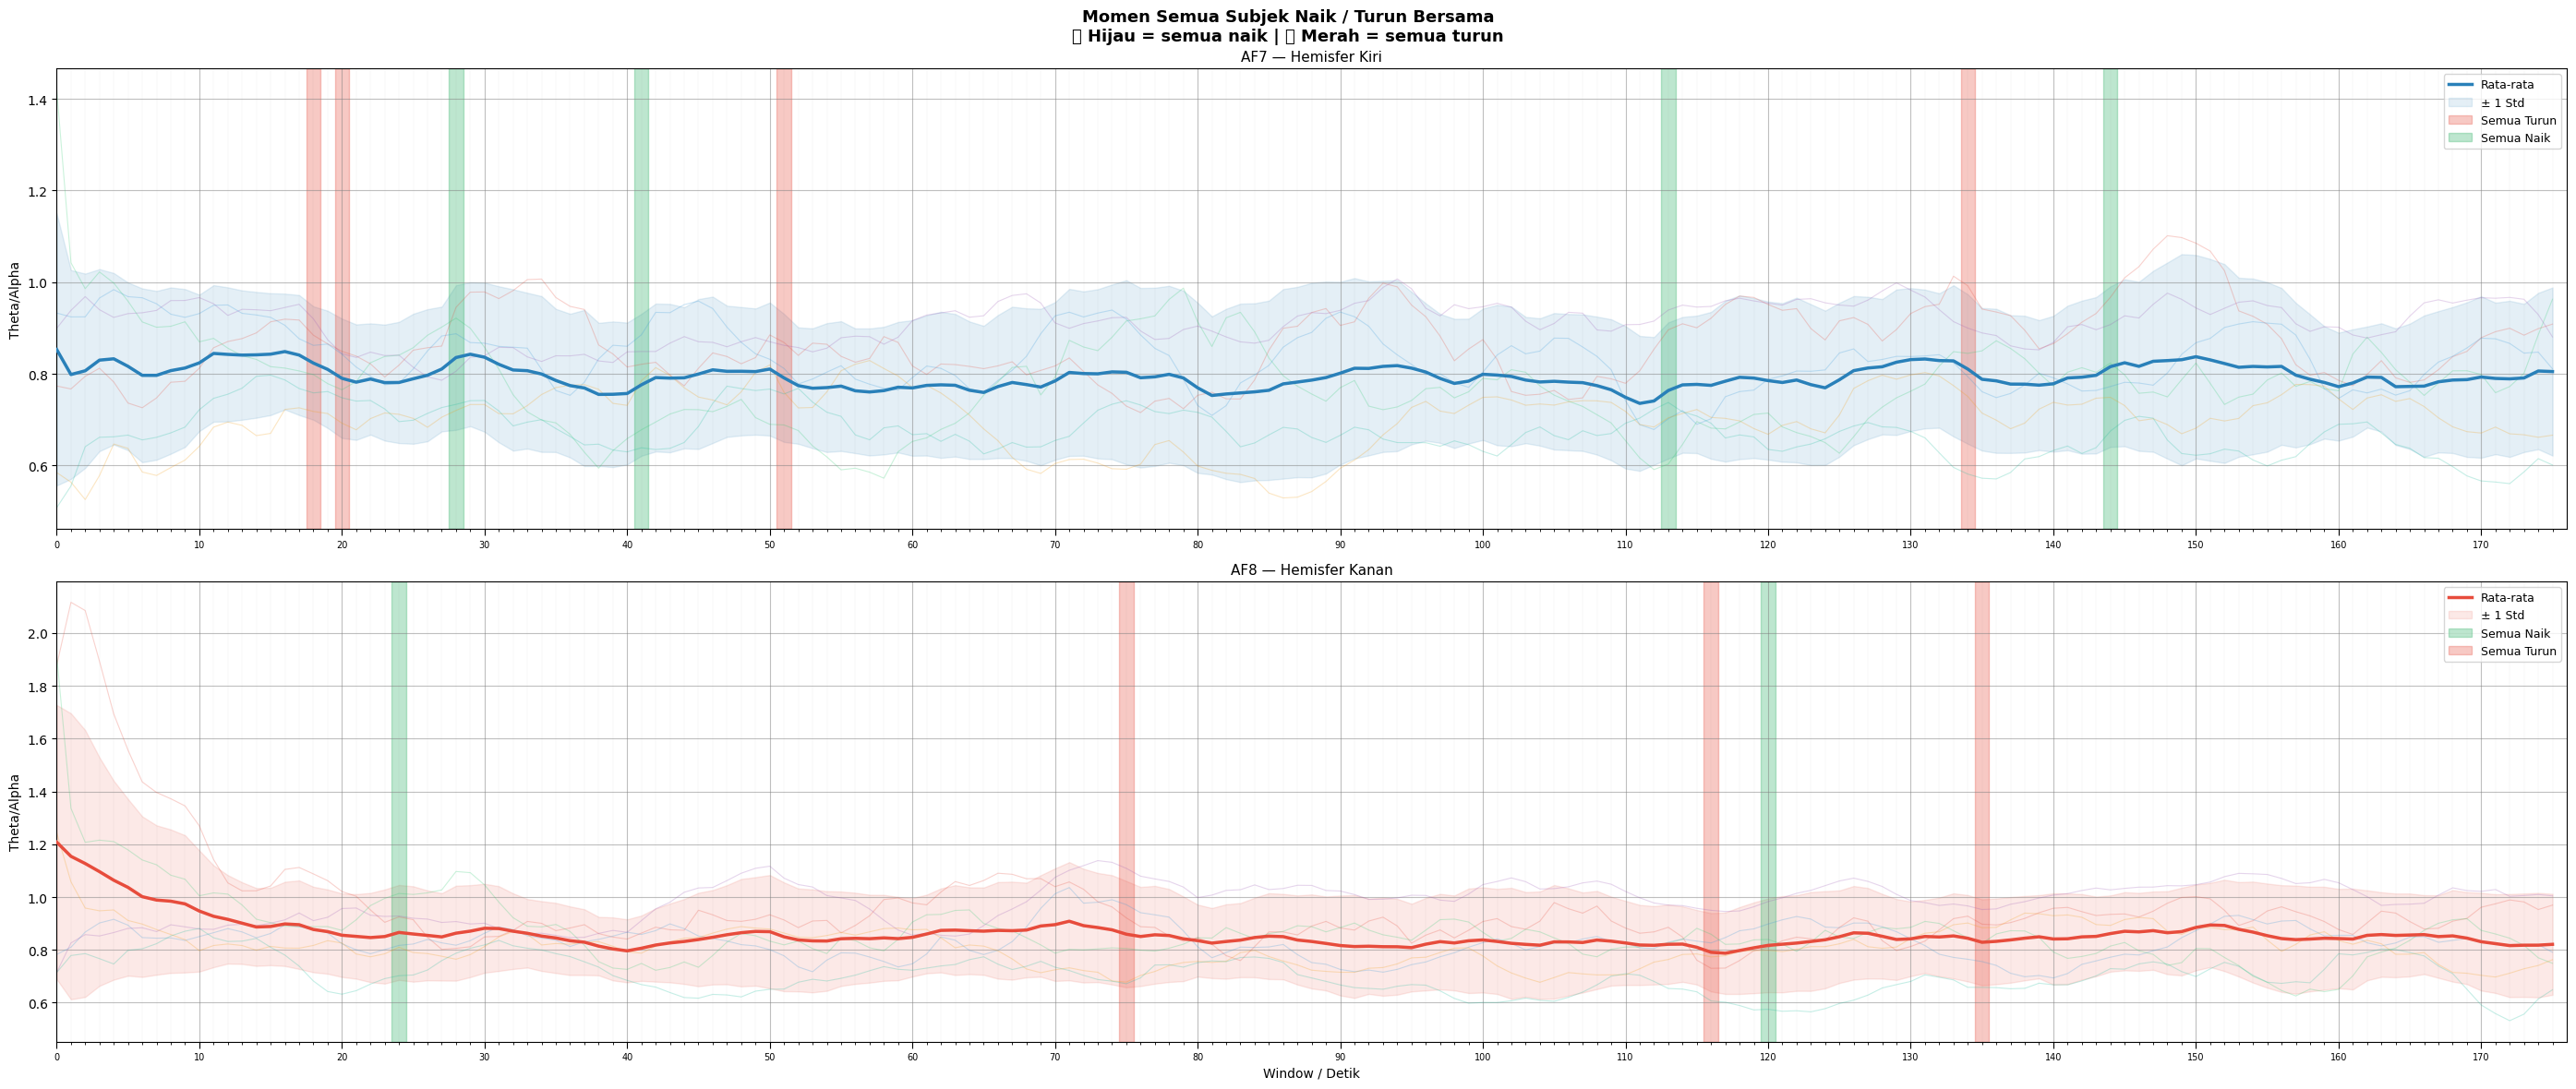

=== DETIK SEMUA SUBJEK NAIK / TURUN BERSAMA ===

AF7:
  Semua naik  (4 window) : [28, 41, 113, 144]
  Semua turun (4 window): [18, 20, 51, 134]

AF8:
  Semua naik  (2 window) : [24, 120]
  Semua turun (3 window): [75, 116, 135]



In [ ]:
# ============================================================
# CELL 11b3 - Deteksi Momen Semua Subjek Naik / Semua Turun Bersama
# Naik  = semua subjek delta positif di window tersebut
# Turun = semua subjek delta negatif di window tersebut
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(28, 12))
fig.suptitle('Momen Semua Subjek Naik / Turun Bersama\n'
             '🟢 Hijau = semua naik | 🔴 Merah = semua turun',
             fontsize=13, fontweight='bold')

for ax, df_all, sensor, warna_mean in zip(
    axes,
    [df_all_af7, df_all_af8],
    ['AF7 — Hemisfer Kiri', 'AF8 — Hemisfer Kanan'],
    ['#2980b9', '#e74c3c']
):
    w           = df_all['window'].values
    mean_smooth = df_all['mean'].rolling(window=10, min_periods=1).mean()
    std_smooth  = df_all['std'].rolling(window=10, min_periods=1).mean()

    # Hitung delta dari data SMOOTH
    semua_naik  = pd.Series(True, index=df_all.index)
    semua_turun = pd.Series(True, index=df_all.index)

    for nama in SUBJEK:
        smooth = df_all[nama].rolling(window=10, min_periods=1).mean()
        delta  = smooth.diff()
        semua_naik  = semua_naik  & (delta > 0)
        semua_turun = semua_turun & (delta < 0)

    # Plot subjek (transparan)
    for nama in SUBJEK:
        smooth = df_all[nama].rolling(window=10, min_periods=1).mean()
        ax.plot(w, smooth, color=WARNA[nama], linewidth=0.8, alpha=0.25)

    # Plot mean ± std
    ax.plot(w, mean_smooth, color=warna_mean, linewidth=2.5,
            label='Rata-rata', zorder=5)
    ax.fill_between(w, mean_smooth - std_smooth,
                    mean_smooth + std_smooth,
                    alpha=0.12, color=warna_mean, label='± 1 Std')

    # Shading naik dan turun
    naik_label  = True
    turun_label = True

    for i in range(1, len(w)):
        if semua_naik.iloc[i]:
            ax.axvspan(w[i] - 0.5, w[i] + 0.5,
                       alpha=0.30, color='#27ae60',
                       label='Semua Naik' if naik_label else None)
            naik_label = False
        if semua_turun.iloc[i]:
            ax.axvspan(w[i] - 0.5, w[i] + 0.5,
                       alpha=0.30, color='#e74c3c',
                       label='Semua Turun' if turun_label else None)
            turun_label = False

    ax.set_title(sensor, fontsize=11)
    ax.set_ylabel('Theta/Alpha')
    ax.legend(fontsize=9, loc='upper right')

    # Grid per 1 detik (minor) dan per 10 detik (major)
    max_w = int(w.max()) + 1
    ax.set_xlim(0, max_w)
    ax.set_xticks(range(0, max_w, 10), minor=False)
    ax.set_xticks(range(0, max_w, 1),  minor=True)
    ax.set_xticklabels([str(x) for x in range(0, max_w, 10)], fontsize=7)
    ax.grid(True, which='major', alpha=0.5, linewidth=0.8, color='gray')
    ax.grid(True, which='minor', alpha=0.15, linewidth=0.3, color='gray')
    ax.tick_params(axis='x', which='minor', length=2)
    ax.tick_params(axis='x', which='major', length=5)

axes[1].set_xlabel('Window / Detik', fontsize=10)

plt.tight_layout()
plt.show()

# Print detik spesifiknya
print('=== DETIK SEMUA SUBJEK NAIK / TURUN BERSAMA ===\n')
for df_all, sensor in [(df_all_af7, 'AF7'), (df_all_af8, 'AF8')]:
    semua_naik  = pd.Series(True, index=df_all.index)
    semua_turun = pd.Series(True, index=df_all.index)

    for nama in SUBJEK:
        smooth = df_all[nama].rolling(window=10, min_periods=1).mean()
        delta  = smooth.diff()
        semua_naik  = semua_naik  & (delta > 0)
        semua_turun = semua_turun & (delta < 0)

    w_naik  = df_all['window'][semua_naik].tolist()
    w_turun = df_all['window'][semua_turun].tolist()

    print(f'{sensor}:')
    print(f'  Semua naik  ({len(w_naik)} window) : {w_naik}')
    print(f'  Semua turun ({len(w_turun)} window): {w_turun}')
    print()

In [ ]:
for nama, df in data_clean.items():
    ts = pd.to_datetime(df['TimeStamp'])
    durasi = (ts.max() - ts.min()).total_seconds()
    print(f'{nama}:')
    print(f'  Mulai  : {ts.min()}')
    print(f'  Selesai: {ts.max()}')
    print(f'  Durasi : {durasi:.1f} detik ({durasi/60:.1f} menit)')
    print(f'  Jumlah baris: {len(df):,}')
    print()

Aulia:
  Mulai  : 2026-05-06 16:21:04.178000
  Selesai: 2026-05-06 16:24:00.192000
  Durasi : 176.0 detik (2.9 menit)
  Jumlah baris: 45,109

Azizah:
  Mulai  : 2026-05-06 16:30:14.581000
  Selesai: 2026-05-06 16:33:15.085000
  Durasi : 180.5 detik (3.0 menit)
  Jumlah baris: 46,266

Dandi:
  Mulai  : 2026-05-06 16:10:25.188000
  Selesai: 2026-05-06 16:13:21.900000
  Durasi : 176.7 detik (2.9 menit)
  Jumlah baris: 45,308

Irgi:
  Mulai  : 2026-05-06 16:10:24.707000
  Selesai: 2026-05-06 16:13:21.183000
  Durasi : 176.5 detik (2.9 menit)
  Jumlah baris: 45,306

Tama:
  Mulai  : 2026-05-06 16:52:55.262000
  Selesai: 2026-05-06 16:55:50.754000
  Durasi : 175.5 detik (2.9 menit)
  Jumlah baris: 45,065

Zahrah:
  Mulai  : 2026-05-06 16:21:04.877000
  Selesai: 2026-05-06 16:24:00.876000
  Durasi : 176.0 detik (2.9 menit)
  Jumlah baris: 45,109

